## **1) Training Dataset** 

### **Veryfing the Datasets for Nulls and Outliers**

In [120]:
import pandas as pd
import numpy as np

import logging
import os
from datetime import datetime

os.makedirs("logs", exist_ok=True)
logger = logging.getLogger("Merged-store-EDA")
logger.setLevel(logging.INFO)

In [121]:
if not logger.handlers:

    # Log file with timestamp
    log_file = f"logs/eda_{datetime.now():%Y%m%d}.log"

    # File handler
    file_handler = logging.FileHandler(log_file, mode="a", encoding="utf-8")
    file_handler.setLevel(logging.INFO)

    # Console handler
    console_handler = logging.StreamHandler()
    console_handler.setLevel(logging.INFO)

    # Log format
    formatter = logging.Formatter(
        "%(asctime)s | %(levelname)s | %(message)s",
        datefmt="%Y-%m-%d %H:%M:%S"
    )

    file_handler.setFormatter(formatter)
    console_handler.setFormatter(formatter)

    logger.addHandler(file_handler)
    logger.addHandler(console_handler)

logger.info("=" * 70)
logger.info("TRAIN STORE SALES - EDA LOGGING STARTED")
logger.info("=" * 70)


2026-11-10 11:22:08 | INFO | ======================================================================
2026-11-10 11:22:08 | INFO | TRAIN STORE SALES - EDA LOGGING STARTED
2026-11-10 11:22:08 | INFO | ======================================================================


In [122]:
train_df = pd.read_csv('./data/train_merged.csv')
train_df.head()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8172\454856589.py:1: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv('./data/train_merged.csv')


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Year,...,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDateMissing
0,1,5,2015-07-31,5263,555,1,1,0,1,2015,...,c,a,1270.0,9.0,2008.0,0,0.0,0.0,NoPromo2,0
1,2,5,2015-07-31,6064,625,1,1,0,1,2015,...,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",0
2,3,5,2015-07-31,8314,821,1,1,0,1,2015,...,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",0
3,4,5,2015-07-31,13995,1498,1,1,0,1,2015,...,c,c,620.0,9.0,2009.0,0,0.0,0.0,NoPromo2,0
4,5,5,2015-07-31,4822,559,1,1,0,1,2015,...,a,a,16107.5,4.0,2015.0,0,0.0,0.0,NoPromo2,0


In [123]:
logger.info("=" * 70)
logger.info("Starting dataset overview analysis")
logger.info("=" * 70)

try:
    logger.info(f"Training dataset shape: {train_df.shape}")

    logger.info(f"Training dataset columns: {list(train_df.columns)}")

    logger.info(f"Training dataset memory usage: {train_df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

    logger.info("Dataset overview analysis completed successfully")

except Exception:
    logger.exception("Error during dataset overview analysis")

2026-11-10 11:22:12 | INFO | ======================================================================
2026-11-10 11:22:12 | INFO | Starting dataset overview analysis
2026-11-10 11:22:12 | INFO | ======================================================================
2026-11-10 11:22:12 | INFO | Training dataset shape: (1017209, 24)
2026-11-10 11:22:12 | INFO | Training dataset columns: ['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDateMissing']
2026-11-10 11:22:13 | INFO | Training dataset memory usage: 439.54 MB
2026-11-10 11:22:13 | INFO | Dataset overview analysis completed successfully


In [124]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 24 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   Store                      1017209 non-null  int64  
 1   DayOfWeek                  1017209 non-null  int64  
 2   Date                       1017209 non-null  str    
 3   Sales                      1017209 non-null  int64  
 4   Customers                  1017209 non-null  int64  
 5   Open                       1017209 non-null  int64  
 6   Promo                      1017209 non-null  int64  
 7   StateHoliday               1017209 non-null  object 
 8   SchoolHoliday              1017209 non-null  int64  
 9   Year                       1017209 non-null  int64  
 10  Month                      1017209 non-null  int64  
 11  Day                        1017209 non-null  int64  
 12  WeekOfYear                 1017209 non-null  int64  
 13  IsWeekend              

In [125]:
# Count duplicate rows
print("Duplicate rows in train_df:", train_df.duplicated().sum())

Duplicate rows in train_df: 0


In [126]:
train_df.isnull().sum()

Store                        0
DayOfWeek                    0
Date                         0
Sales                        0
Customers                    0
Open                         0
Promo                        0
StateHoliday                 0
SchoolHoliday                0
Year                         0
Month                        0
Day                          0
WeekOfYear                   0
IsWeekend                    0
StoreType                    0
Assortment                   0
CompetitionDistance          0
CompetitionOpenSinceMonth    0
CompetitionOpenSinceYear     0
Promo2                       0
Promo2SinceWeek              0
Promo2SinceYear              0
PromoInterval                0
CompetitionDateMissing       0
dtype: int64

In [127]:
logger.info("=" * 70)
logger.info("Starting missing-value analysis")
logger.info("=" * 70)

try:
    missing_count = train_df.isnull().sum()
    missing_percentage = (
        missing_count / len(train_df) * 100
    )

    missing_summary = pd.DataFrame({
        "MissingCount": missing_count,
        "MissingPercentage": missing_percentage
    })

    missing_summary = missing_summary[
        missing_summary["MissingCount"] > 0
    ].sort_values("MissingCount", ascending=False)

    logger.info(f"Missing-value summary:\n{missing_summary.to_string()}")

    if missing_summary.empty:
        logger.info("No missing values found in the training dataset")

    logger.info("Missing-value analysis completed successfully")

except Exception:
    logger.exception("Error during missing-value analysis")


2026-11-10 11:22:15 | INFO | ======================================================================
2026-11-10 11:22:15 | INFO | Starting missing-value analysis
2026-11-10 11:22:15 | INFO | ======================================================================
2026-11-10 11:22:15 | INFO | Missing-value summary:
Empty DataFrame
Columns: [MissingCount, MissingPercentage]
Index: []
2026-11-10 11:22:15 | INFO | No missing values found in the training dataset
2026-11-10 11:22:15 | INFO | Missing-value analysis completed successfully


In [128]:
# Identify numerical columns
numerical_cols = train_df.select_dtypes(
    include=np.number
).columns.tolist()

print("All numerical columns:")
print(numerical_cols)

All numerical columns:
['Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'CompetitionDateMissing']


In [129]:
continuous_cols = [
    col for col in [
        'Sales',
        'Customers',
        'CompetitionDistance',
        'CompetitionOpenSinceMonth',
        'CompetitionOpenSinceYear',
        'Promo2SinceWeek',
        'Promo2SinceYear'
    ]
    if col in train_df.columns
]

print("Continuous variables for outlier analysis:")
print(continuous_cols)

Continuous variables for outlier analysis:
['Sales', 'Customers', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2SinceWeek', 'Promo2SinceYear']


In [130]:
outlier_results = []

for col in continuous_cols:
    series = train_df[col].dropna()

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = series[
        (series < lower_bound) | (series > upper_bound)
    ]

    outlier_results.append({
        'Column': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': round(
            len(outliers) / len(series) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(
    outlier_summary.sort_values(
        'Outlier Percentage',
        ascending=False
    )
)

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
1,Customers,405.0,837.0,432.0,-243.0,1485.0,38095,3.75
0,Sales,3727.0,7856.0,4129.0,-2466.5,14049.5,26694,2.62
2,CompetitionDistance,710.0,6880.0,6170.0,-8545.0,16135.0,0,0.00
3,CompetitionOpenSinceMonth,0.0,9.0,9.0,-13.5,22.5,0,0.00
4,CompetitionOpenSinceYear,0.0,2011.0,2011.0,-3016.5,5027.5,0,0.00
5,Promo2SinceWeek,0.0,22.0,22.0,-33.0,55.0,0,0.00
6,Promo2SinceYear,0.0,2012.0,2012.0,-3018.0,5030.0,0,0.00


## Final Data Quality Check

The merged training and test datasets were inspected and found to contain **no missing values** and only a minimal number of potential outliers, which appear to be valid observations.

**Conclusion:** The datasets are clean and ready for model preparation, with no further cleaning required at this stage.

In [131]:
logger.info("=" * 70)
logger.info("Starting outlier analysis using the IQR method")
logger.info("=" * 70)

try:
    numerical_columns = train_df.select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()

    outlier_results = []

    for col in numerical_columns:
        Q1 = train_df[col].quantile(0.25)
        Q3 = train_df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outlier_count = (
            (train_df[col] < lower_bound) |
            (train_df[col] > upper_bound)
        ).sum()

        outlier_results.append({
            "Feature": col,
            "OutlierCount": outlier_count,
            "OutlierPercentage": round(
                outlier_count / len(train_df) * 100, 2
            )
        })

    outlier_summary = pd.DataFrame(outlier_results)

    logger.info(f"Outlier summary:\n{outlier_summary.to_string(index=False)}")
    logger.info("Outlier analysis completed successfully")

except Exception:
    logger.exception("Error during outlier analysis")


2026-11-10 11:22:15 | INFO | ======================================================================
2026-11-10 11:22:15 | INFO | Starting outlier analysis using the IQR method
2026-11-10 11:22:15 | INFO | ======================================================================
2026-11-10 11:22:16 | INFO | Outlier summary:
                  Feature  OutlierCount  OutlierPercentage
                    Store             0               0.00
                DayOfWeek             0               0.00
                    Sales         26694               2.62
                Customers         38095               3.75
                     Open        172817              16.99
                    Promo             0               0.00
            SchoolHoliday        181721              17.86
                     Year             0               0.00
                    Month             0               0.00
                      Day             0               0.00
               WeekOfYear    

In [132]:
logger.info('=' * 70)
logger.info("Starting descriptive statistical analysis")
logger.info('=' * 70)

try:
    numeric_summary = train_df.describe()

    logger.info("Descriptive statistics generated successfully")
    logger.info(f"\n{numeric_summary.to_string()}")

except Exception:
    logger.exception("Error during descriptive statistical analysis")


2026-11-10 11:22:16 | INFO | ======================================================================
2026-11-10 11:22:16 | INFO | Starting descriptive statistical analysis
2026-11-10 11:22:16 | INFO | ======================================================================
2026-11-10 11:22:17 | INFO | Descriptive statistics generated successfully
2026-11-10 11:22:17 | INFO | 
              Store     DayOfWeek         Sales     Customers          Open         Promo  SchoolHoliday          Year         Month           Day    WeekOfYear     IsWeekend  CompetitionDistance  CompetitionOpenSinceMonth  CompetitionOpenSinceYear        Promo2  Promo2SinceWeek  Promo2SinceYear  CompetitionDateMissing
count  1.017209e+06  1.017209e+06  1.017209e+06  1.017209e+06  1.017209e+06  1.017209e+06   1.017209e+06  1.017209e+06  1.017209e+06  1.017209e+06  1.017209e+06  1.017209e+06         1.017209e+06               1.017209e+06              1.017209e+06  1.017209e+06     1.017209e+06     1.017209e+06       

### **Performing EDA**

In [133]:
import matplotlib.pyplot as plt
import seaborn as sns

In [134]:
# Consistent, colorful visual theme
sns.set_theme(style="whitegrid", context="notebook")

# Color palettes
numeric_colors = ['#4285F4', '#FB8C00']
bar_palette = sns.color_palette("husl", 10)
pie_colors = sns.color_palette("Set3", 12)

# Continuous numerical columns
numerical_cols = [
    col for col in [
        'Sales',
        'Customers',
        'CompetitionDistance'
    ]
    if col in train_df.columns
]

# Categorical columns stored as text or category
categorical_cols = train_df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Add numerical columns that represent categories
categorical_numeric_cols = [
    'DayOfWeek', 'Open', 'Promo', 'StateHoliday',
    'SchoolHoliday', 'StoreType', 'Assortment', 'Promo2'
]

for col in categorical_numeric_cols:
    if col in train_df.columns and col not in categorical_cols:
        categorical_cols.append(col)

# Exclude identifiers and raw dates from categorical plots
exclude_cols = ['Store', 'Id', 'Date']
categorical_cols = [
    col for col in categorical_cols
    if col not in exclude_cols
]

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)


Numerical columns: ['Sales', 'Customers', 'CompetitionDistance']
Categorical columns: ['StateHoliday', 'StoreType', 'Assortment', 'PromoInterval', 'DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'Promo2']


C:\Users\ASUS\AppData\Local\Temp\ipykernel_8172\2152634300.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_df.select_dtypes(


## Numerical Feature Visualization

`Store` is an identifier, while `DayOfWeek` and `Promo` represent categorical codes. Treating them as continuous measurements could lead to misleading interpretations.

Therefore, the initial numerical analysis focuses on **`Sales`, `Customers`, and `CompetitionDistance`** to examine their distributions and identify potential patterns or anomalies.

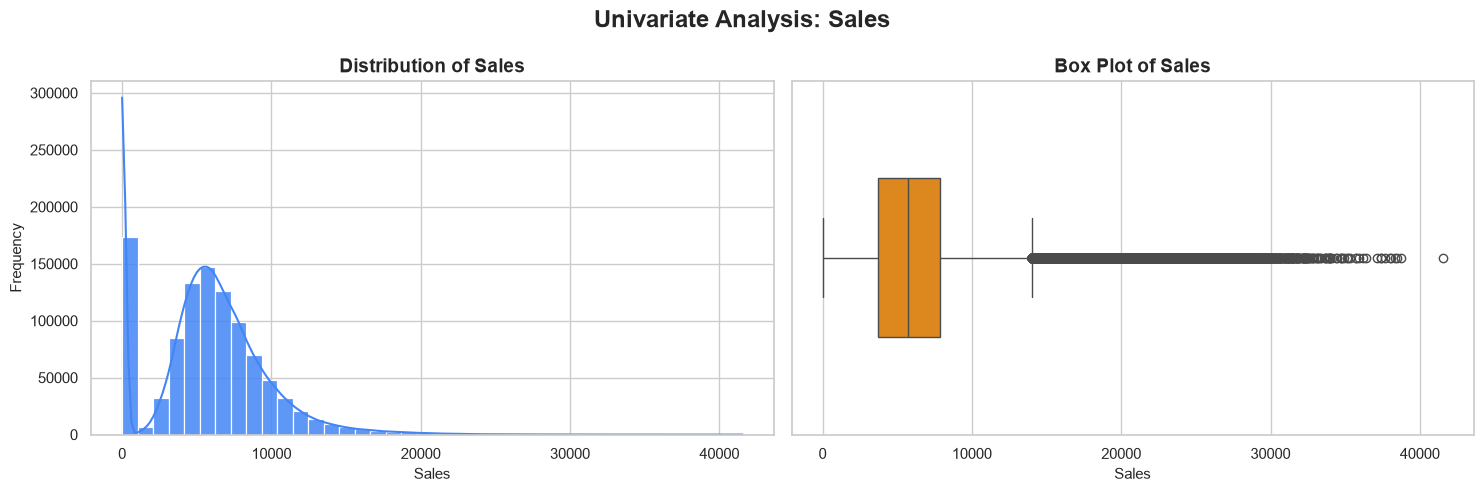

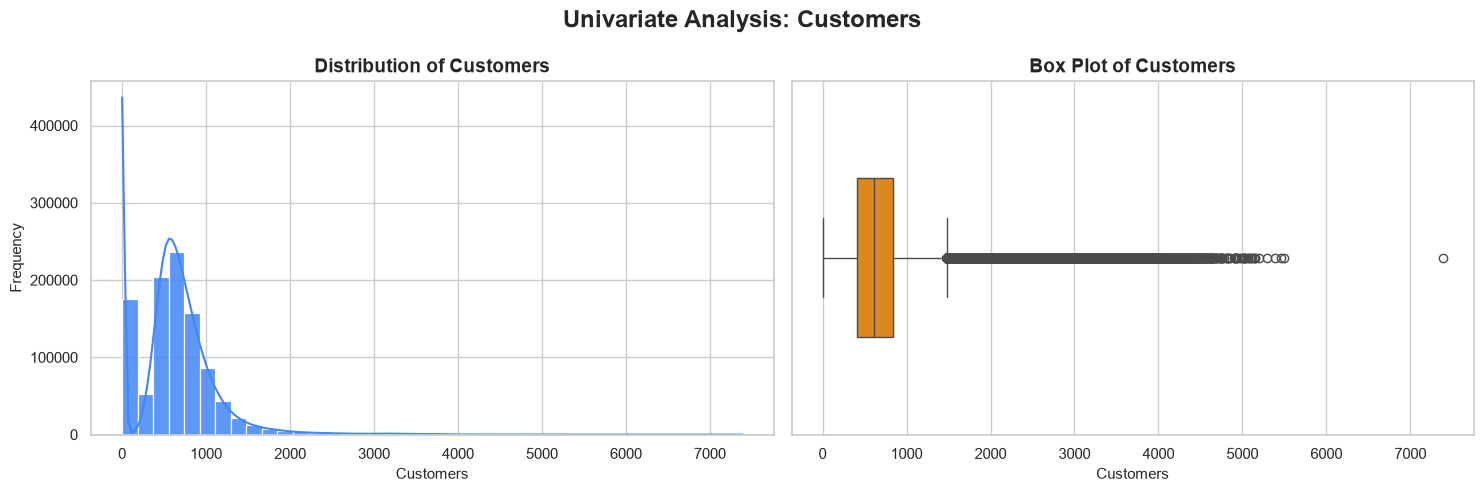

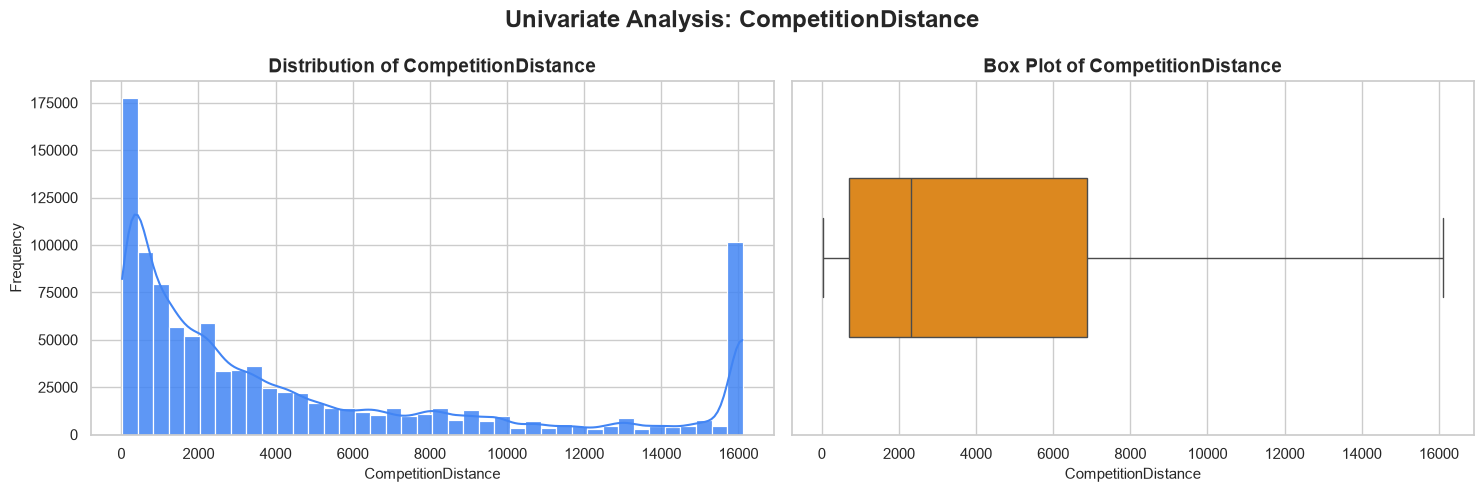

In [135]:
for col in numerical_cols:

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Histogram
    sns.histplot(
        data=train_df,
        x=col,
        bins=40,
        kde=True if train_df[col].nunique() > 10 else False,
        color=numeric_colors[0],
        edgecolor='white',
        alpha=0.85,
        ax=axes[0]
    )

    axes[0].set_title(
        f'Distribution of {col}',
        fontsize=14,
        fontweight='bold'
    )
    axes[0].set_xlabel(col, fontsize=11)
    axes[0].set_ylabel('Frequency', fontsize=11)

    # Box plot
    sns.boxplot(
        data=train_df,
        x=col,
        color=numeric_colors[1],
        width=0.45,
        ax=axes[1]
    )

    axes[1].set_title(
        f'Box Plot of {col}',
        fontsize=14,
        fontweight='bold'
    )
    axes[1].set_xlabel(col, fontsize=11)

    fig.suptitle(
        f'Univariate Analysis: {col}',
        fontsize=17,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.show()


## 🔎Outlier Analysis and Retention Decision

The IQR method identified potential outliers in `Sales` and `Customers`. However, these observations are retained because extreme values may represent genuine business activity rather than data errors.

| Feature | Outliers | Percentage | Decision |
|---|---:|---:|---|
| `Sales` | 26,694 | 2.62% | Retain |
| `Customers` | 38,095 | 3.75% | Retain |

### Justification

- **Genuine business variation:** High sales and customer counts may occur during promotions, holidays, or peak shopping periods.
- **Business significance:** These observations capture important demand patterns that a forecasting model should learn.
- **No confirmed data errors:** IQR flags statistical extremes but does not establish that the values are incorrect.
- **Preserving information:** Removing or capping valid observations could reduce the model's ability to predict peak demand accurately.

**Conclusion:** Retain the identified outliers in `Sales` and `Customers` to preserve genuine business patterns and improve the model's opportunity to learn from high-demand periods.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8172\2118452487.py:17: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.barplot(


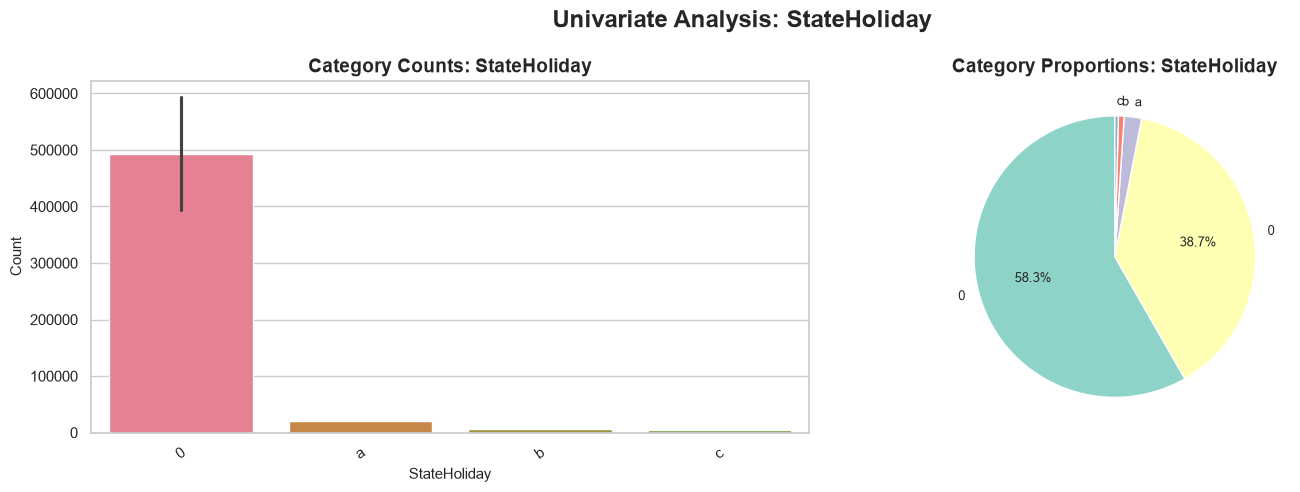

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8172\2118452487.py:17: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.barplot(


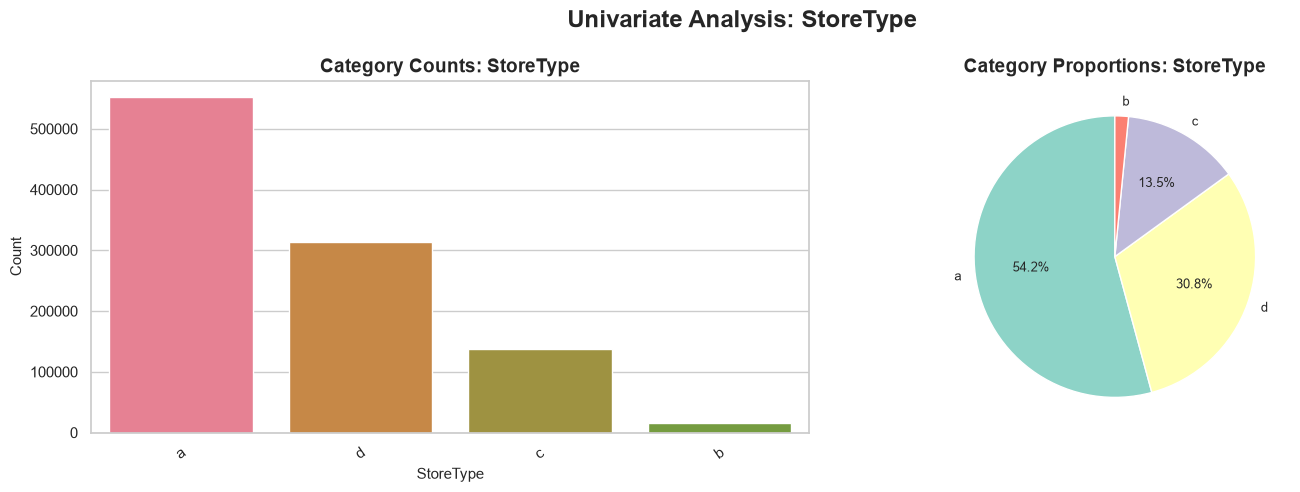

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8172\2118452487.py:17: UserWarning: The palette list has more values (10) than needed (3), which may not be intended.
  sns.barplot(


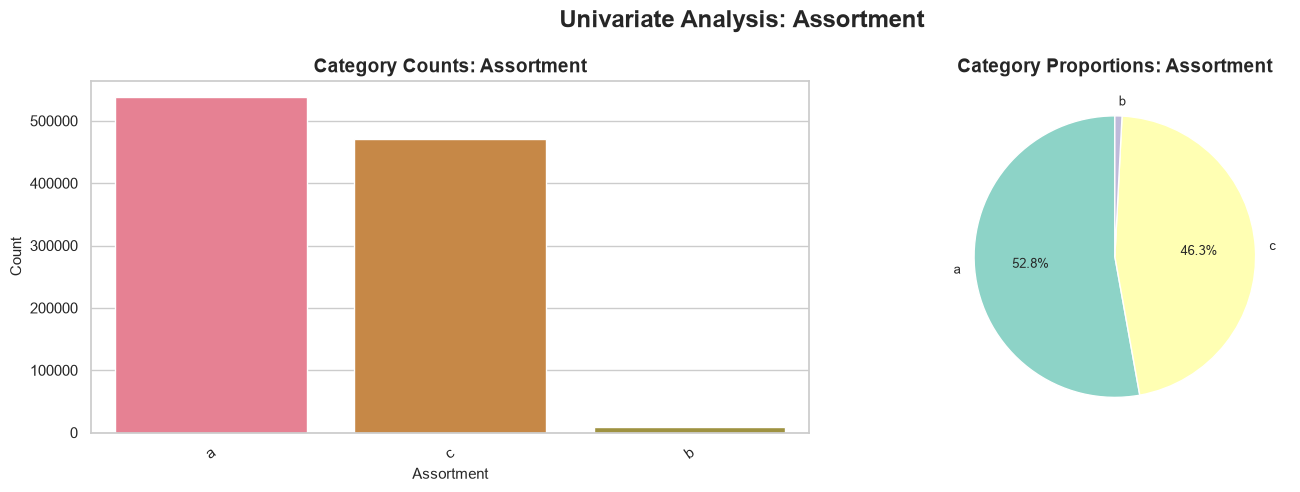

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8172\2118452487.py:17: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.barplot(


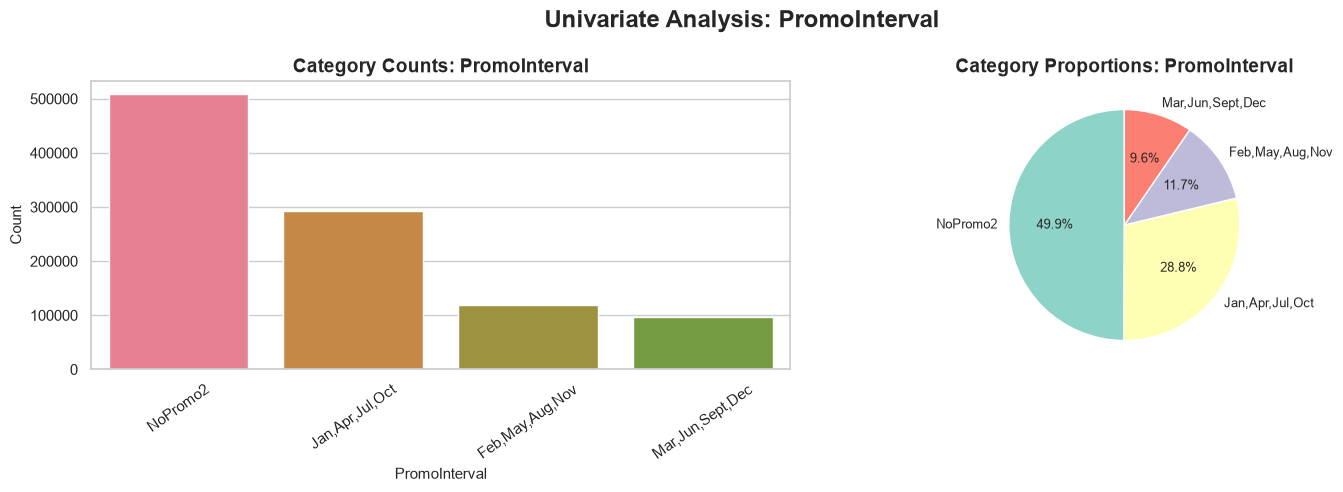

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8172\2118452487.py:17: UserWarning: The palette list has more values (10) than needed (7), which may not be intended.
  sns.barplot(


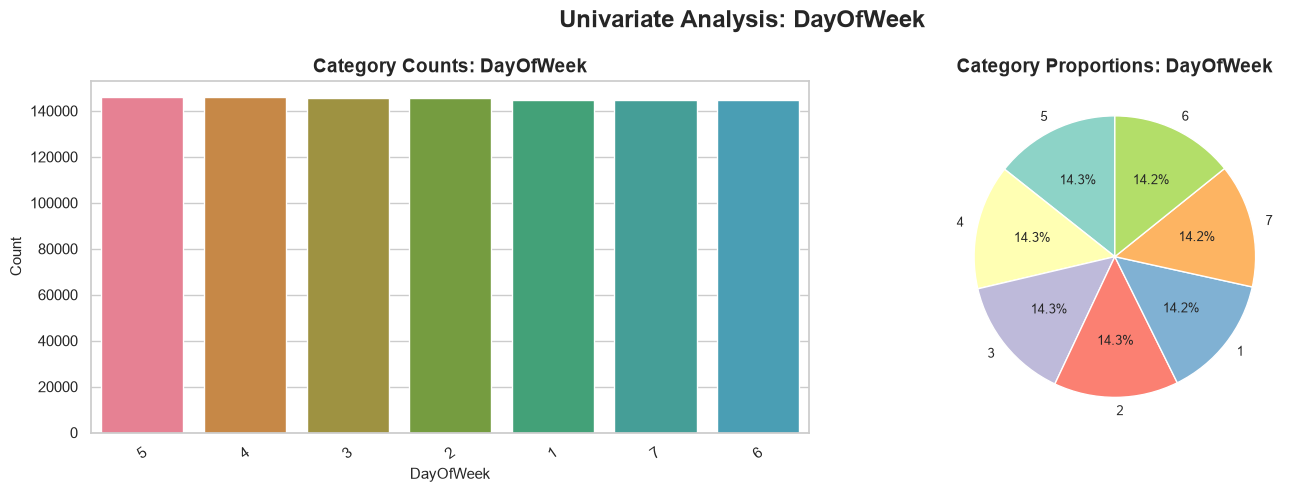

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8172\2118452487.py:17: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.barplot(


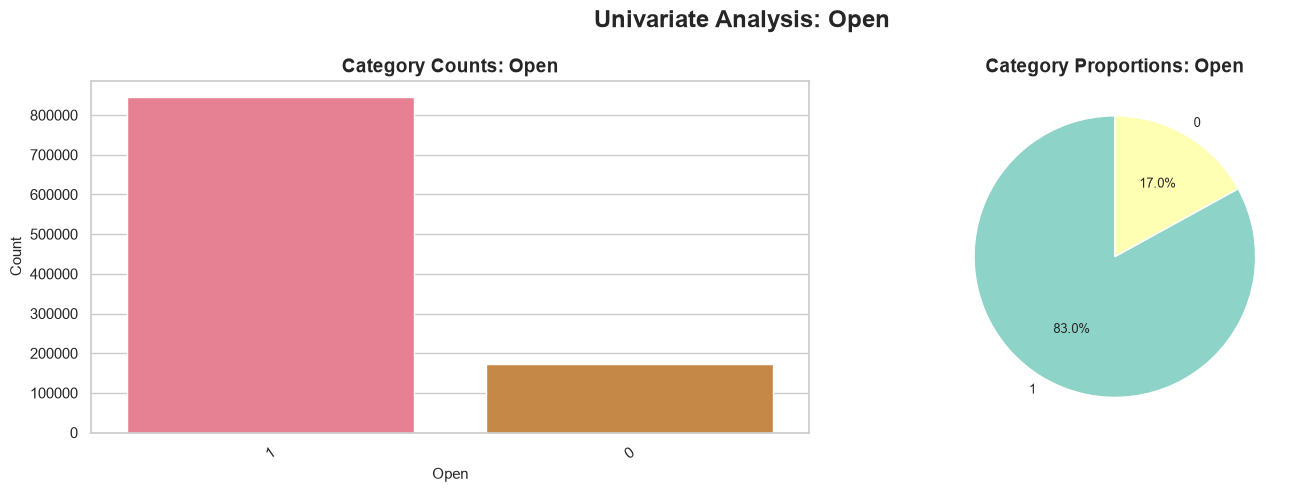

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8172\2118452487.py:17: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.barplot(


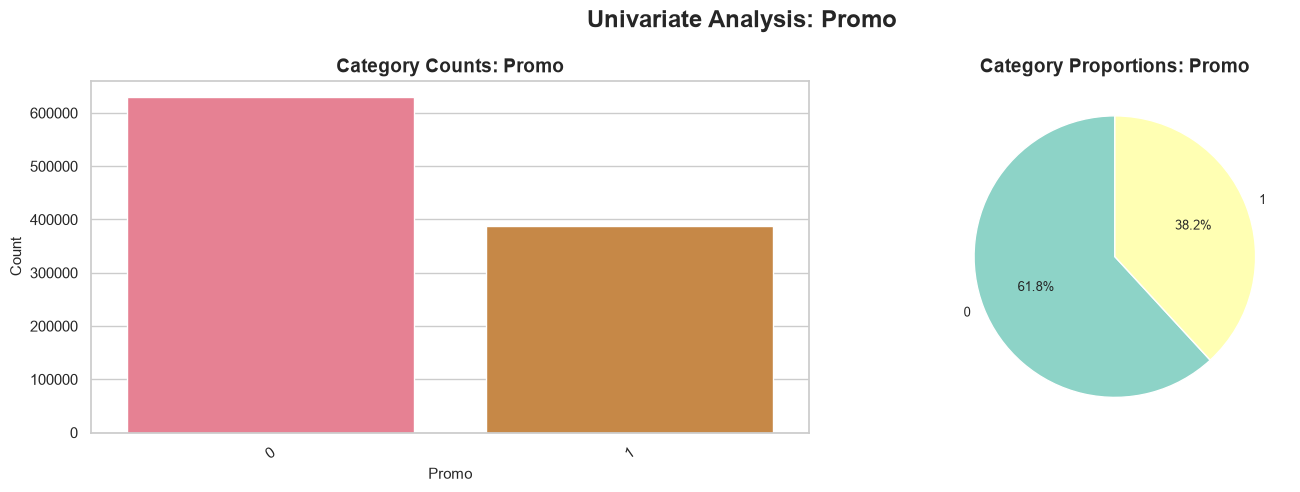

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8172\2118452487.py:17: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.barplot(


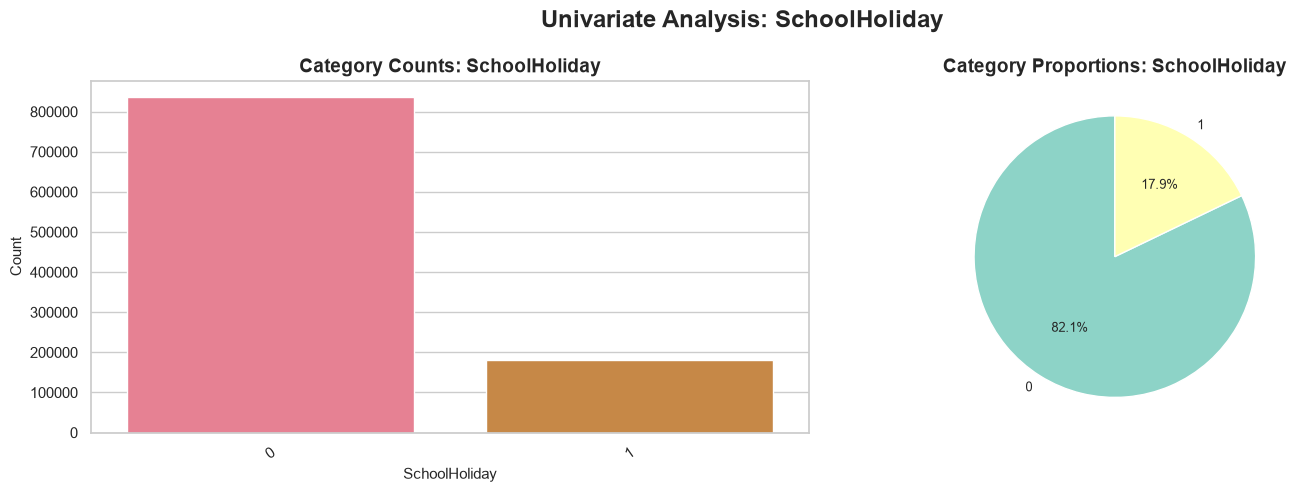

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8172\2118452487.py:17: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.barplot(


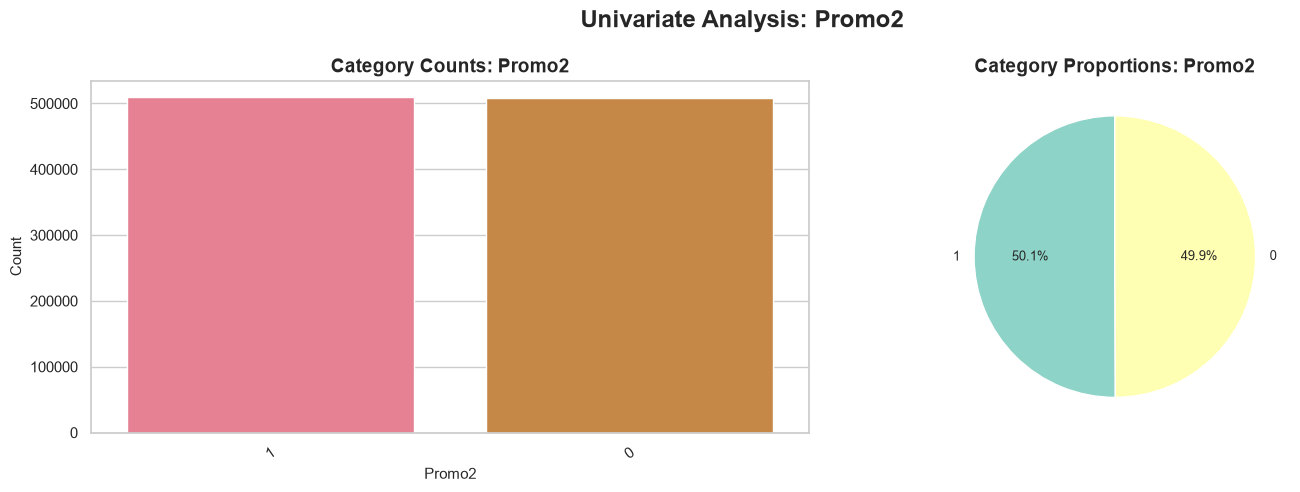

In [136]:
for col in categorical_cols:

    # Count categories, including any remaining missing values
    counts = train_df[col].value_counts(
        dropna=False
    )

    # Improve the display label for missing values
    labels = [
        'Missing' if pd.isna(value) else str(value)
        for value in counts.index
    ]

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Bar chart
    sns.barplot(
        x=labels,
        y=counts.values,
        hue=labels,
        palette=bar_palette,
        legend=False,
        ax=axes[0]
    )

    axes[0].set_title(
        f'Category Counts: {col}',
        fontsize=14,
        fontweight='bold'
    )
    axes[0].set_xlabel(col, fontsize=11)
    axes[0].set_ylabel('Count', fontsize=11)
    axes[0].tick_params(axis='x', rotation=35)

    # Pie chart
    axes[1].pie(
        counts.values,
        labels=labels,
        autopct=lambda pct: f'{pct:.1f}%' if pct >= 2 else '',
        startangle=90,
        colors=pie_colors,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1},
        textprops={'fontsize': 9}
    )

    axes[1].set_title(
        f'Category Proportions: {col}',
        fontsize=14,
        fontweight='bold'
    )

    fig.suptitle(
        f'Univariate Analysis: {col}',
        fontsize=17,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.show()


## 🕵️‍♂️Exploratory Data Analysis – Key Categorical Insights

The categorical feature analysis reveals the distribution of store characteristics, promotional activities, holidays, and operating status across the dataset.

| Feature | Key Insight |
|---|---|
| `StateHoliday` | Most records correspond to non-holiday days (`0`). |
| `StoreType` | Approximately 54% of records belong to Type A stores, followed by around 30% from Type D stores. |
| `Assortment` | Approximately 52% of records have Basic assortment (`a`), while 46% have Extended assortment (`c`). |
| `Promo2` | Around 50% of records are associated with stores that do not participate in the ongoing promotion program (`Promo2 = 0`). |
| `DayOfWeek` | Customer counts are distributed relatively evenly across the seven days of the week. |
| `Open` | Approximately 83% of records indicate that stores were open. |
| `Promo` | Around 61% of records indicate that no promotion was active (`Promo = 0`). |
| `SchoolHoliday` | Approximately 82% of records correspond to non-school-holiday days (`0`). |

### Key Takeaway

The dataset predominantly represents **non-holiday periods, open-store operations, and records without active daily promotions**. Store Types A and D, along with Basic and Extended assortments, account for most observations.

*Note: These percentages describe dataset records, not necessarily unique stores or unique customers. `Promo2` represents participation in a continuing promotion program, whereas `Promo` indicates whether a promotion was active on a particular record.*

In [137]:
logger.info("=" * 70)
logger.info("Starting univariate analysis")
logger.info("=" * 70)

try:
    numerical_columns = train_df.select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()

    categorical_columns = train_df.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    logger.info(f"Numerical columns analyzed: {numerical_columns}")
    logger.info(f"Categorical columns analyzed: {categorical_columns}")

    logger.info(
        f"Number of numerical features: {len(numerical_columns)}"
    )
    logger.info(
        f"Number of categorical features: {len(categorical_columns)}"
    )

    logger.info("Univariate analysis completed successfully")

except Exception:
    logger.exception("Error during univariate analysis")


2026-11-10 11:22:40 | INFO | ======================================================================
2026-11-10 11:22:40 | INFO | Starting univariate analysis
2026-11-10 11:22:40 | INFO | ======================================================================
C:\Users\ASUS\AppData\Local\Temp\ipykernel_8172\2145161972.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = train_df.select_dtypes(
2026-11-10 11:22:40 | INFO | Numerical columns analyzed: ['Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo', 'SchoolHoliday', 'Year', 'Month', 'Day', 'We

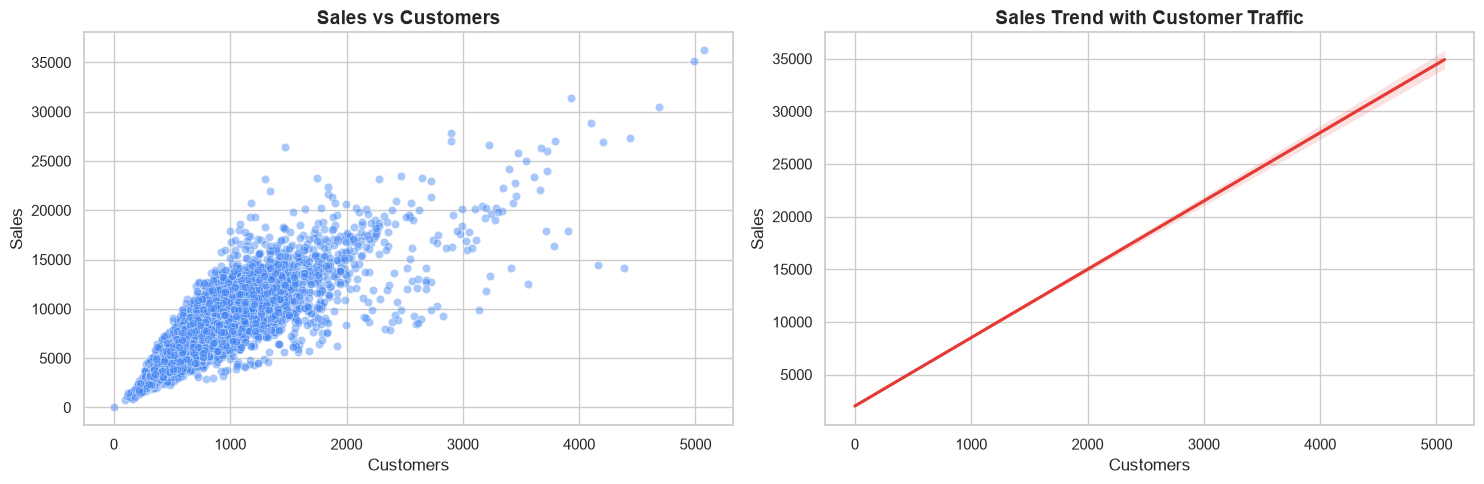

Correlation between Sales and Customers: 0.824


In [138]:
sns.set_theme(style="whitegrid")

# Consider only open stores
open_df = train_df[train_df['Open'] == 1].copy()

# Sample records for visualization
plot_sample = open_df.sample(
    n=min(10000, len(open_df)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(
    data=plot_sample,
    x='Customers',
    y='Sales',
    alpha=0.45,
    color='#4285F4',
    ax=axes[0]
)
axes[0].set_title('Sales vs Customers', fontsize=14, fontweight='bold')

sns.regplot(
    data=plot_sample,
    x='Customers',
    y='Sales',
    scatter=False,
    color='#E53935',
    ax=axes[1]
)
axes[1].set_title('Sales Trend with Customer Traffic',
                  fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print(
    "Correlation between Sales and Customers:",
    round(open_df['Sales'].corr(open_df['Customers']), 3)
)


> ❓ **Research Question :** *What is the relationship between the number of customers and sales performance?*
## 🤵‍♂️Correlation Analysis: Sales vs. Number of Customers

**Correlation Coefficient:** `0.824`

The correlation coefficient of **0.824 indicates a strong positive linear relationship** between `Sales` and `Customers`.

### Key Insights

- **Strong Positive Relationship:** Sales generally increase as the number of customers increases.
- **Business Interpretation:** Higher customer traffic is associated with higher sales performance.
- **Predictive Value:** Customer count is strongly associated with sales and may be useful for understanding sales patterns.

### Conclusion

The strong positive correlation suggests that customer traffic is an important factor associated with store sales.

In [139]:
logger.info("=" * 70)
logger.info("Starting sales and customer relationship analysis")
logger.info("=" * 70)

try:
    open_df = train_df[train_df["Open"] == 1].copy()

    correlation = open_df["Sales"].corr(open_df["Customers"])

    logger.info(f"Open store-day records: {len(open_df)}")
    logger.info(f"Sales-Customers correlation: {correlation:.4f}")

    logger.info(
        f"Average sales: {open_df['Sales'].mean():.2f}"
    )
    logger.info(
        f"Average customers: {open_df['Customers'].mean():.2f}"
    )

    logger.info("Sales and customer analysis completed successfully")

except Exception:
    logger.exception("Error during sales and customer analysis")


2026-11-10 11:22:42 | INFO | ======================================================================
2026-11-10 11:22:42 | INFO | Starting sales and customer relationship analysis
2026-11-10 11:22:42 | INFO | ======================================================================
2026-11-10 11:22:42 | INFO | Open store-day records: 844392
2026-11-10 11:22:42 | INFO | Sales-Customers correlation: 0.8236
2026-11-10 11:22:42 | INFO | Average sales: 6955.51
2026-11-10 11:22:42 | INFO | Average customers: 762.73
2026-11-10 11:22:42 | INFO | Sales and customer analysis completed successfully


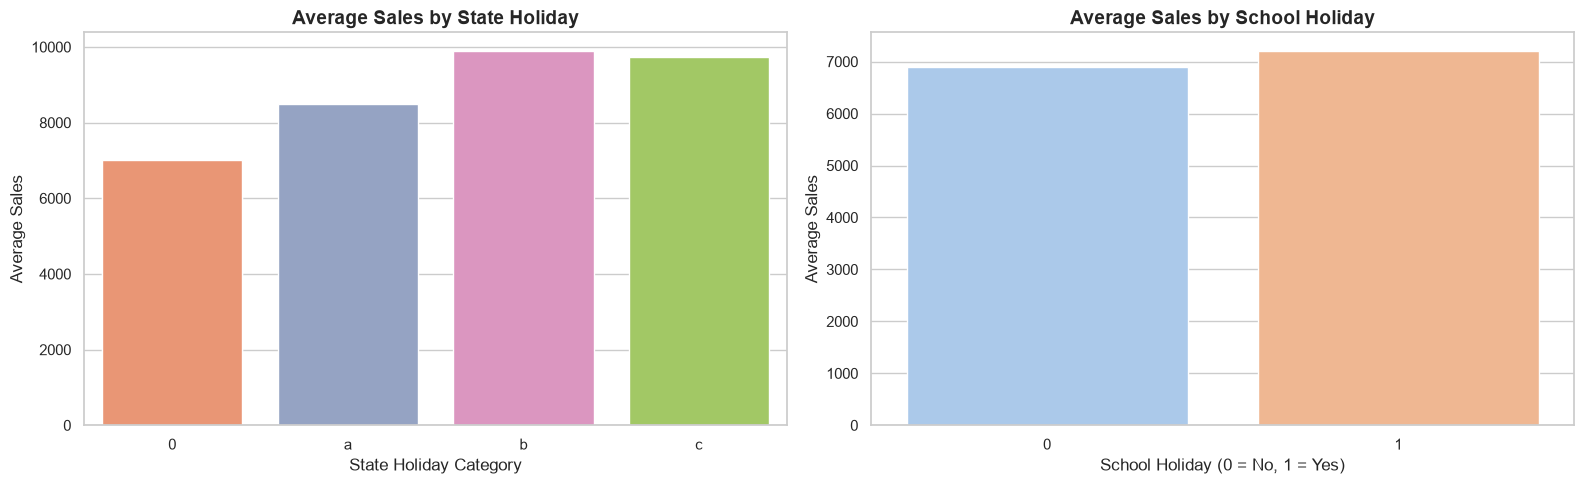

In [140]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(
    data=open_df,
    x='StateHoliday',
    y='Sales',
    estimator='mean',
    errorbar=None,
    hue='StateHoliday',
    palette='Set2',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Average Sales by State Holiday',
                  fontsize=14, fontweight='bold')
axes[0].set_xlabel('State Holiday Category')
axes[0].set_ylabel('Average Sales')

sns.barplot(
    data=open_df,
    x='SchoolHoliday',
    y='Sales',
    estimator='mean',
    errorbar=None,
    hue='SchoolHoliday',
    palette='pastel',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Average Sales by School Holiday',
                  fontsize=14, fontweight='bold')
axes[1].set_xlabel('School Holiday (0 = No, 1 = Yes)')
axes[1].set_ylabel('Average Sales')

plt.tight_layout()
plt.show()


## 🎄 Holiday Impact on Sales

- **State Holidays:** Category `b` records the highest average sales, followed by `c`, `a`, and `0`.
  - `0` – No state holiday
  - `a` – Public holiday
  - `b` – Easter holiday
  - `c` – Christmas holiday

- **School Holidays:** Average sales are slightly higher on school holidays (`1`) than on non-school-holiday days (`0`).

### Key Insight

Holiday periods may influence sales patterns and customer purchasing behaviour. However, these differences should be interpreted alongside store operating status and the number of observations in each category.

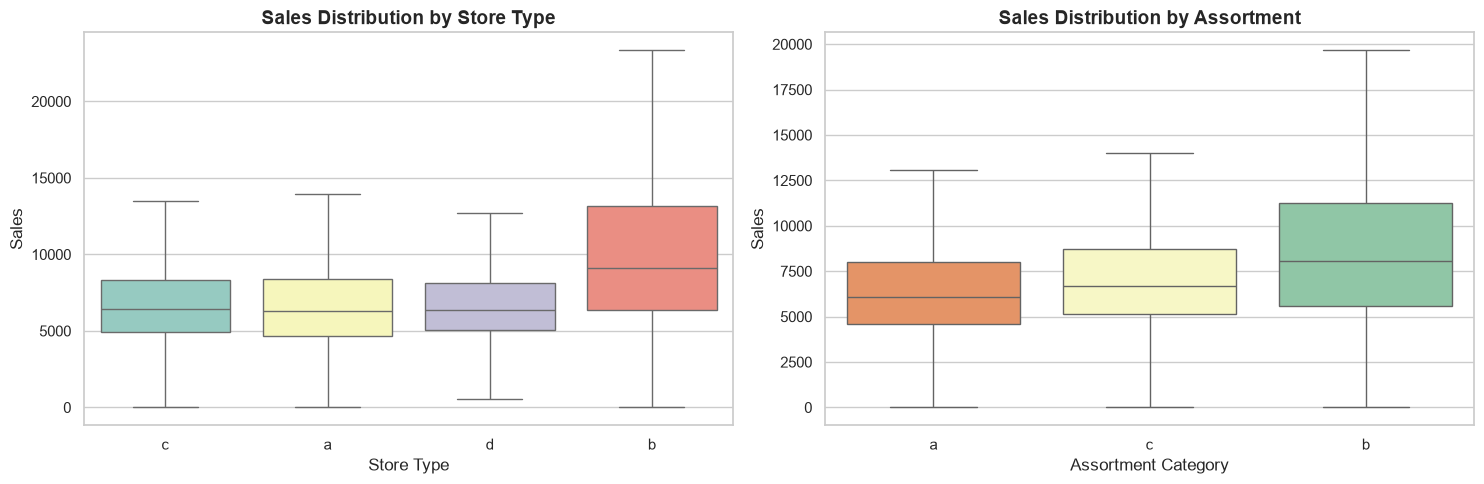

In [141]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=open_df,
    x='StoreType',
    y='Sales',
    hue='StoreType',
    palette='Set3',
    legend=False,
    showfliers=False,
    ax=axes[0]
)
axes[0].set_title('Sales Distribution by Store Type',
                  fontsize=14, fontweight='bold')
axes[0].set_xlabel('Store Type')

sns.boxplot(
    data=open_df,
    x='Assortment',
    y='Sales',
    hue='Assortment',
    palette='Spectral',
    legend=False,
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title('Sales Distribution by Assortment',
                  fontsize=14, fontweight='bold')
axes[1].set_xlabel('Assortment Category')

plt.tight_layout()
plt.show()


## 🏪Sales Analysis by Store Characteristics

- **Store Type:** Type `b` records the highest sales among store types. However, the dataset does not specify its exact store format or physical characteristics.
- **Assortment Type:** Assortment `b` (**Extra assortment**) records the highest sales among assortment categories.

### Key Insight

Store type and assortment may influence sales performance. These findings can help identify high-performing store characteristics for further analysis and sales forecasting.

*Note: Store Type `b` and Assortment Type `b` are distinct categories with different meanings.*

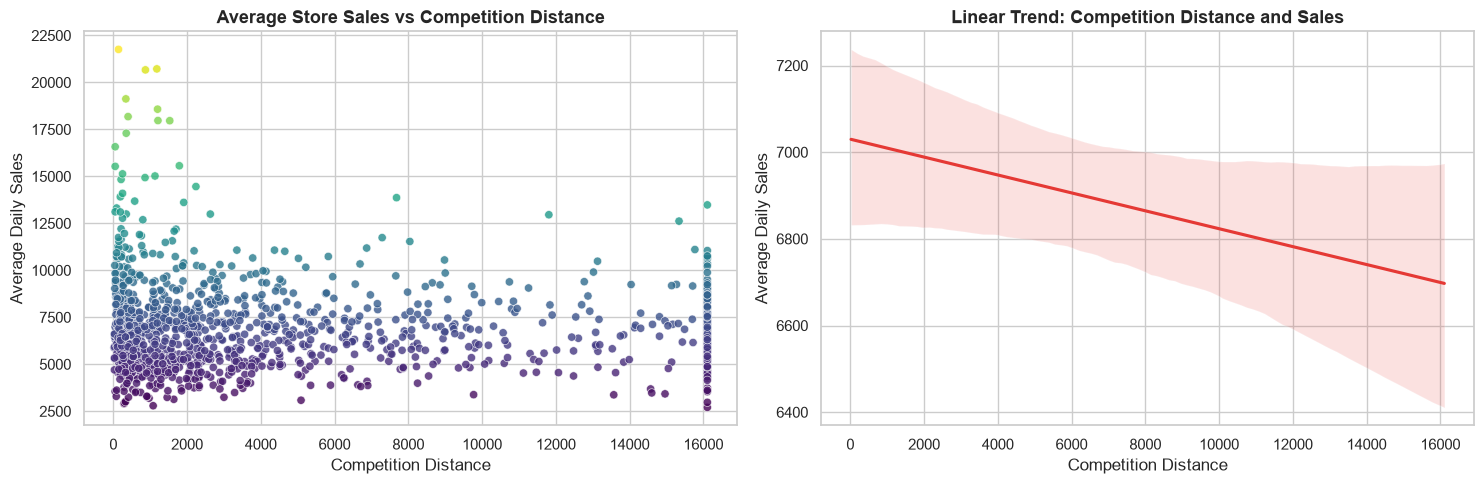

Store-level correlation: -0.045


In [142]:
store_sales = (
    open_df.groupby(['Store', 'CompetitionDistance'], as_index=False)
    .agg(
        AverageSales=('Sales', 'mean'),
        SalesRecords=('Sales', 'size')
    )
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Scatter plot: average sales vs competition distance
sns.scatterplot(
    data=store_sales,
    x='CompetitionDistance',
    y='AverageSales',
    hue='AverageSales',
    palette='viridis',
    legend=False,
    alpha=0.8,
    ax=axes[0]
)

axes[0].set_title(
    'Average Store Sales vs Competition Distance',
    fontsize=13,
    fontweight='bold'
)
axes[0].set_xlabel('Competition Distance')
axes[0].set_ylabel('Average Daily Sales')

# Linear trend line (does not require statsmodels)
sns.regplot(
    data=store_sales,
    x='CompetitionDistance',
    y='AverageSales',
    scatter=False,
    color='#E53935',
    lowess=False,
    ax=axes[1]
)

axes[1].set_title(
    'Linear Trend: Competition Distance and Sales',
    fontsize=13,
    fontweight='bold'
)
axes[1].set_xlabel('Competition Distance')
axes[1].set_ylabel('Average Daily Sales')

plt.tight_layout()
plt.show()

# Correlation
correlation = store_sales[
    ['CompetitionDistance', 'AverageSales']
].corr().iloc[0, 1]

print("Store-level correlation:", round(correlation, 3))

## 🏬Impact of Competition Distance on Sales

**Correlation Coefficient:** `-0.045`

The correlation indicates a **very weak negative relationship** between `CompetitionDistance` and `Sales`.

- **Observation:** Sales tend to decrease slightly as the distance to the nearest competitor increases, but the relationship is negligible.
- **Interpretation:** Competition distance alone has little linear association with sales and is unlikely to explain sales variations effectively.
- **Modeling Decision:** Retain `CompetitionDistance` as a potential feature and evaluate its contribution during model development.

### Key Insight

The correlation is too close to zero to establish a meaningful linear relationship. Other factors, such as store type, promotions, holidays, and customer traffic, may play a more substantial role in explaining sales performance.

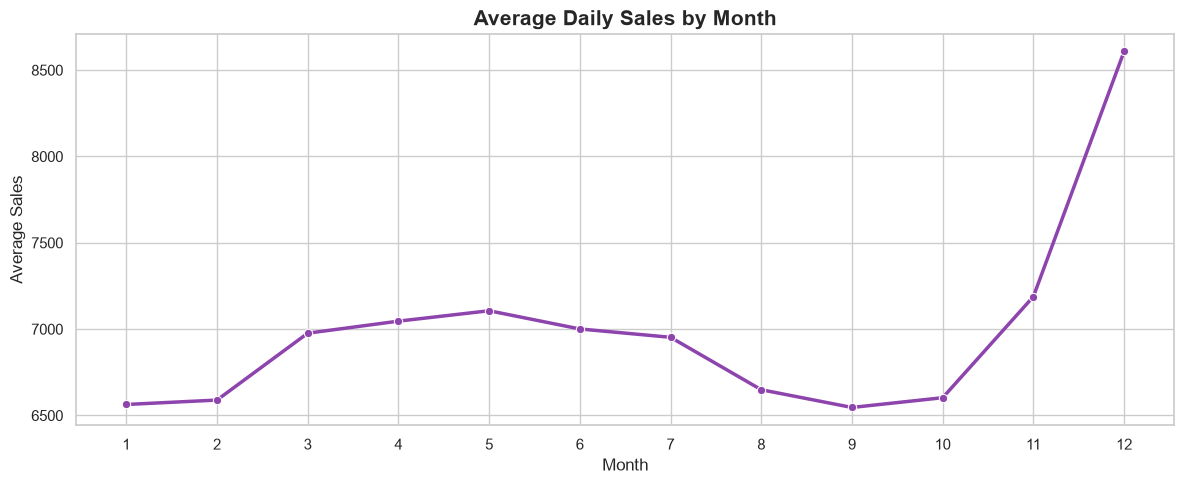

In [143]:
# Ensure Date is datetime
open_df['Date'] = pd.to_datetime(open_df['Date'])

# Extract month if it isn't already present
if 'Month' not in open_df.columns:
    open_df['Month'] = open_df['Date'].dt.month

monthly_sales = (
    open_df.groupby('Month', as_index=False)['Sales']
    .mean()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x='Month',
    y='Sales',
    marker='o',
    linewidth=2.5,
    color='#8E44AD'
)

plt.title('Average Daily Sales by Month',
          fontsize=15, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Average Sales')
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()


## 📆Monthly Sales Trend Analysis

The monthly sales analysis reveals noticeable seasonal variations in average daily sales throughout the year.

### Key Observations

- **Peak Sales:** December records the highest average daily sales, exceeding 8,600.
- **Strong Performance:** March to May shows a steady increase, with sales peaking locally in May.
- **Sales Decline:** Average sales generally decline from June through September, reaching their lowest level in September.
- **Year-End Recovery:** Sales rise sharply in November and December, indicating a strong year-end sales period.

### Business Insight

Sales exhibit a seasonal pattern, with a pronounced peak in December and a dip during late summer. These trends may help inform inventory planning, promotional strategies, and demand forecasting.

*Note: Monthly averages show seasonal associations but do not establish their causes.*

In [144]:
# Consider only records where the store is open
open_df = train_df[train_df['Open'] == 1].copy()

# Random sample for visualizations involving many daily records
plot_df = open_df.sample(
    n=min(20000, len(open_df)),
    random_state=42
)

print("Open-store records:", len(open_df))
print("Records selected for plotting:", len(plot_df))

Open-store records: 844392
Records selected for plotting: 20000


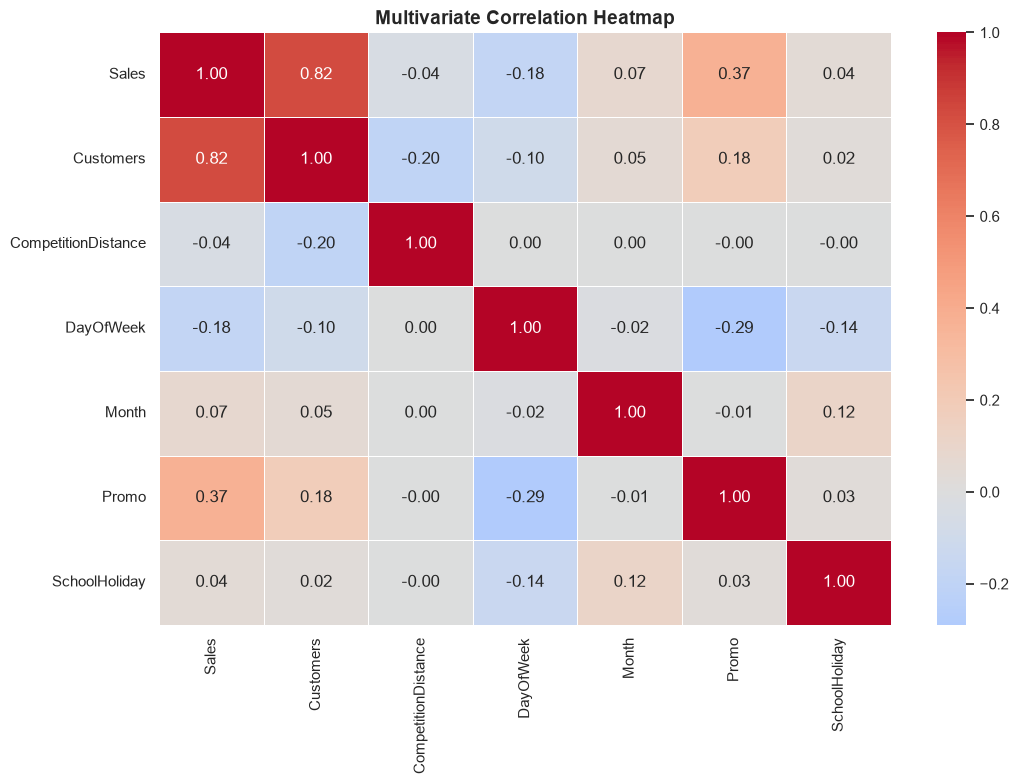

In [145]:
numeric_cols = [
    'Sales',
    'Customers',
    'CompetitionDistance',
    'DayOfWeek',
    'Month',
    'Promo',
    'SchoolHoliday'
]

correlation_matrix = open_df[numeric_cols].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title(
    'Multivariate Correlation Heatmap',
    fontsize=14,
    fontweight='bold'
)
plt.tight_layout()
plt.show()

## 🎢Multivariate Correlation Analysis

The correlation heatmap highlights the strength and direction of linear relationships between sales and selected numerical features.

### Key Findings

| Feature Pair | Correlation | Interpretation |
|---|---:|---|
| `Sales` – `Customers` | **0.82** | Strong positive relationship |
| `Sales` – `Promo` | **0.37** | Moderate positive relationship |
| `Sales` – `DayOfWeek` | **−0.18** | Weak negative relationship |
| `Sales` – `SchoolHoliday` | **0.04** | Negligible relationship |
| `Sales` – `Month` | **0.07** | Very weak positive relationship |
| `Sales` – `CompetitionDistance` | **−0.04** | Negligible negative relationship |

### Key Insights

- **Customer Traffic:** `Customers` has the strongest positive correlation with `Sales`, indicating that higher customer counts are generally associated with higher sales.
- **Promotional Impact:** `Promo` shows a moderate positive association with sales, suggesting that promotional activity may contribute to increased sales.
- **Weekly Patterns:** `DayOfWeek` has a weak negative correlation with sales, indicating some variation across weekdays.
- **Limited Linear Relationships:** `Month`, `SchoolHoliday`, and `CompetitionDistance` show weak or negligible individual linear correlations with sales.

### Conclusion

`Customers` and `Promo` show the strongest positive correlations with `Sales` among the features examined. However, correlation does not imply causation, and weak individual correlations do not necessarily mean a feature lacks predictive value. Seasonal patterns and interactions may still be useful in forecasting.

In [146]:
logger.info("=" * 70)
logger.info("Starting correlation analysis")
logger.info("=" * 70)

try:
    correlation_df = train_df.select_dtypes(
        include=["int64", "float64"]
    )

    correlation_matrix = correlation_df.corr()

    logger.info(
        f"Correlation matrix:\n{correlation_matrix.round(3).to_string()}"
    )

    sales_correlation = (
        correlation_matrix["Sales"]
        .drop("Sales")
        .sort_values(ascending=False)
    )

    logger.info(
        f"Features positively and negatively correlated with Sales:\n"
        f"{sales_correlation.round(3).to_string()}"
    )

    logger.info("Correlation analysis completed successfully")

except Exception:
    logger.exception("Error during correlation analysis")


2026-11-10 11:22:53 | INFO | ======================================================================
2026-11-10 11:22:53 | INFO | Starting correlation analysis
2026-11-10 11:22:53 | INFO | ======================================================================
2026-11-10 11:22:54 | INFO | Correlation matrix:
                           Store  DayOfWeek  Sales  Customers   Open  Promo  SchoolHoliday   Year  Month    Day  WeekOfYear  IsWeekend  CompetitionDistance  CompetitionOpenSinceMonth  CompetitionOpenSinceYear  Promo2  Promo2SinceWeek  Promo2SinceYear  CompetitionDateMissing
Store                      1.000     -0.000  0.005      0.024 -0.000  0.000          0.001  0.000  0.001  0.000       0.001     -0.000               -0.027                     -0.033                    -0.009   0.008            0.011            0.009                   0.009
DayOfWeek                 -0.000      1.000 -0.462     -0.386 -0.529 -0.393         -0.205  0.002 -0.005  0.005      -0.005      0.790        

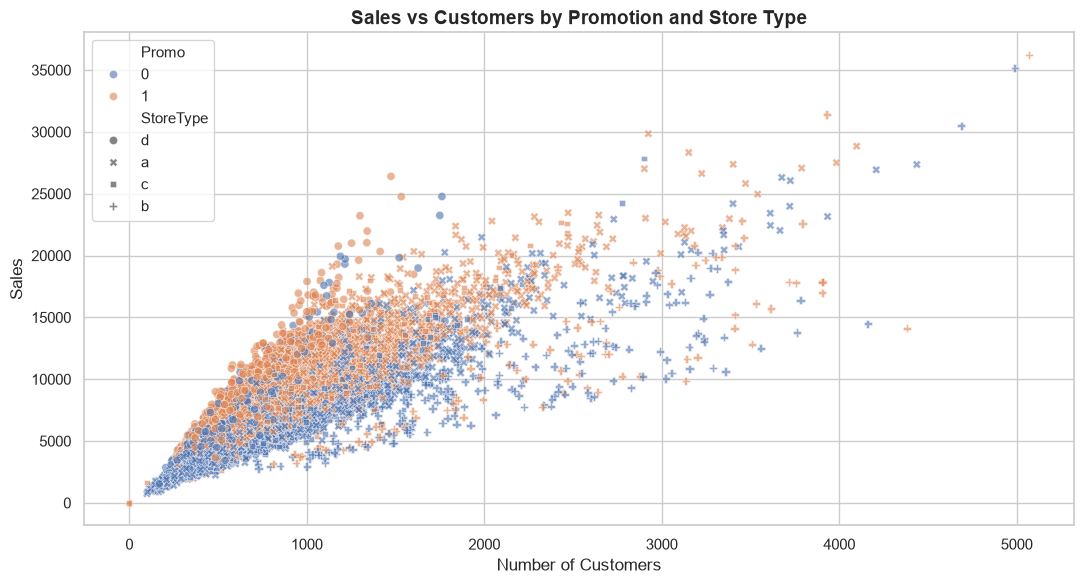

In [147]:
sns.set_theme(style="whitegrid", context="notebook")

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=plot_df,
    x='Customers',
    y='Sales',
    hue='Promo',
    style='StoreType',
    alpha=0.6,
    s=35
)

plt.title(
    'Sales vs Customers by Promotion and Store Type',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Number of Customers')
plt.ylabel('Sales')
plt.tight_layout()
plt.show()

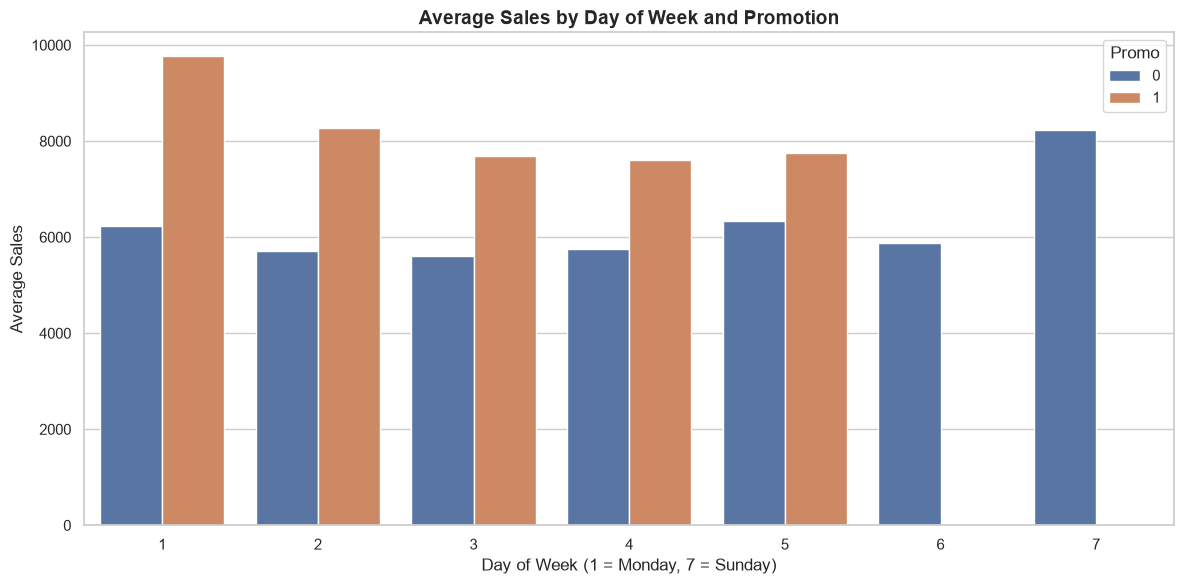

In [148]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=open_df,
    x='DayOfWeek',
    y='Sales',
    hue='Promo',
    errorbar=None
)

plt.title(
    'Average Sales by Day of Week and Promotion',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Day of Week (1 = Monday, 7 = Sunday)')
plt.ylabel('Average Sales')
plt.tight_layout()
plt.show()

## 🏣Weekly Promotion Analysis

### Key Findings

- **Promotion Schedule:** Active promotions are observed from Monday (`DayOfWeek = 1`) to Friday (`DayOfWeek = 5`), with no active promotions recorded on Saturday or Sunday.
- **Peak Promotion Activity:** Monday records the highest number of active promotions among the five weekdays.

### Business Insight

The promotion pattern suggests that promotional activities are concentrated on weekdays, particularly Mondays. This may help inform weekly promotion planning and sales forecasting.

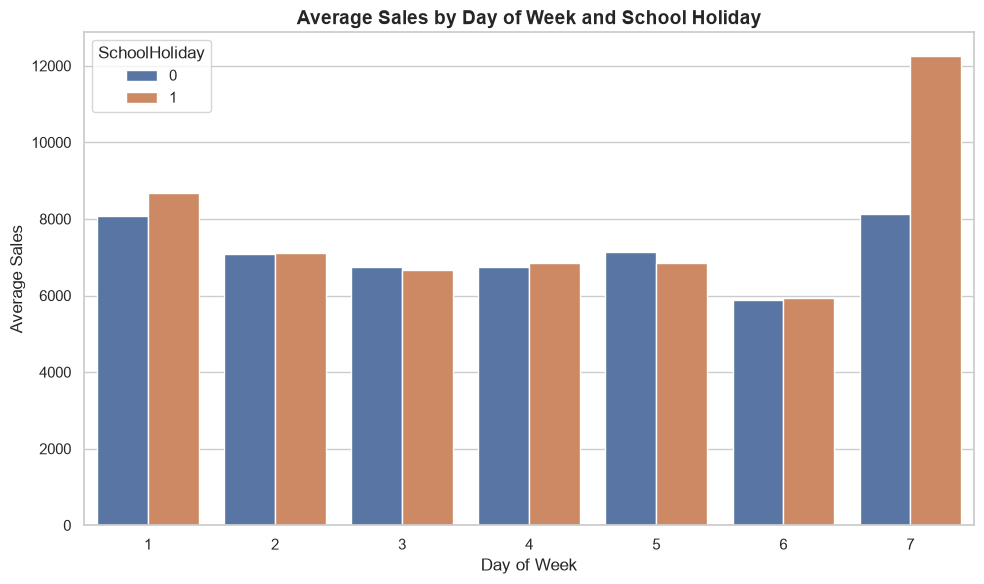

In [149]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=open_df,
    x='DayOfWeek',
    y='Sales',
    hue='SchoolHoliday',
    errorbar=None
)

plt.title(
    'Average Sales by Day of Week and School Holiday',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Day of Week')
plt.ylabel('Average Sales')
plt.tight_layout()
plt.show()

## 🏫Weekly Sales Patterns by School Holiday

### Key Findings

- **Peak Sales Days:** Sunday and Monday record the highest average sales across the week.
- **Consistent Weekly Pattern:** Average sales generally follow a similar pattern on school-holiday and non-school-holiday days, with a few notable differences.
- **School Holiday Effect:** Average sales increase noticeably on Sunday and Monday when schools are on holiday.
- **Friday Variation:** Average sales decrease slightly on Fridays during school holidays.

### Business Insight

School holidays appear to influence sales differently across weekdays, particularly on Sunday and Monday. These variations may help improve day-specific sales forecasting, inventory planning, and promotional strategies.

**Conclusion:** Sunday and Monday are important sales days, with school holidays associated with an additional increase in average sales on these days.

In [150]:
logger.info("=" * 70)
logger.info("Starting weekday and weekend analysis")
logger.info("=" * 70)

try:
    weekday_df = train_df[train_df["Open"] == 1].copy()

    weekday_summary = (
        weekday_df.groupby("DayOfWeek")
        .agg(
            AverageSales=("Sales", "mean"),
            AverageCustomers=("Customers", "mean"),
            StoreDays=("Sales", "size")
        )
        .round(2)
    )

    logger.info(
        f"Weekday performance:\n{weekday_summary.to_string()}"
    )

    weekday_df["DayType"] = np.where(
        weekday_df["DayOfWeek"].isin([6, 7]),
        "Weekend",
        "Weekday"
    )

    weekend_summary = (
        weekday_df.groupby("DayType")
        .agg(
            AverageSales=("Sales", "mean"),
            AverageCustomers=("Customers", "mean"),
            StoreDays=("Sales", "size")
        )
        .round(2)
    )

    logger.info(
        f"Weekday vs weekend summary:\n{weekend_summary.to_string()}"
    )

    logger.info("Weekday and weekend analysis completed successfully")

except Exception:
    logger.exception("Error during weekday and weekend analysis")


2026-11-10 11:22:59 | INFO | ======================================================================
2026-11-10 11:22:59 | INFO | Starting weekday and weekend analysis
2026-11-10 11:22:59 | INFO | ======================================================================
2026-11-10 11:22:59 | INFO | Weekday performance:
           AverageSales  AverageCustomers  StoreDays
DayOfWeek                                           
1               8216.07            855.44     137560
2               7088.11            769.99     143961
3               6728.12            740.60     141936
4               6767.31            755.57     134644
5               7072.68            781.77     138640
6               5874.84            660.18     144058
7               8224.72           1441.53       3593
2026-11-10 11:23:00 | INFO | Weekday vs weekend summary:
         AverageSales  AverageCustomers  StoreDays
DayType                                           
Weekday       7172.41            780.43     696

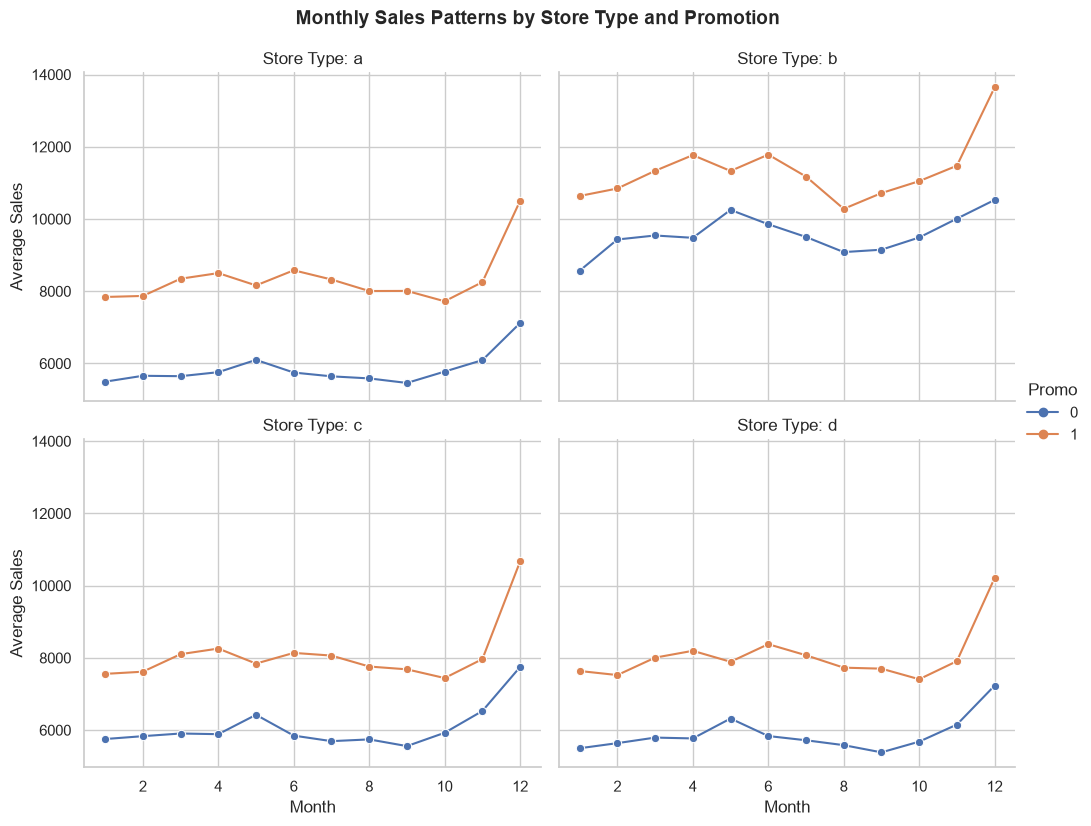

In [151]:
monthly_sales = (
    open_df.groupby(
        ['Month', 'StoreType', 'Promo'],
        as_index=False
    )
    .agg(AverageSales=('Sales', 'mean'))
)

g = sns.relplot(
    data=monthly_sales,
    x='Month',
    y='AverageSales',
    hue='Promo',
    col='StoreType',
    kind='line',
    marker='o',
    col_wrap=2,
    height=4,
    aspect=1.3
)

g.set_axis_labels('Month', 'Average Sales')
g.set_titles('Store Type: {col_name}')
g.figure.suptitle(
    'Monthly Sales Patterns by Store Type and Promotion',
    y=1.03,
    fontsize=14,
    fontweight='bold'
)

plt.show()

## 📆Monthly Sales Patterns by Store Type and Promotion

### Key Findings

- **Promotion Impact:** All four store types (`a`, `b`, `c`, and `d`) record higher average sales when promotions are active (`Promo = 1`).
- **Store Type B:** Consistently records the highest average sales across the months, with a pronounced peak in December.
- **December Peak:** All store types show a substantial increase in average sales in December, particularly during promotional periods.
- **Seasonal Variation:** Average sales generally soften between August and October before recovering toward year-end.
- **Store Types A, C, and D:** Show similar seasonal patterns, with lower sales levels than Type B.

### Business Insights

- Promotions are associated with higher average sales across every store type.
- December represents a strong sales period, suggesting the importance of seasonal inventory and staffing plans.
- Store-specific sales patterns should be considered when planning promotions and forecasting demand.

**Conclusion:** Promotional activity and seasonal patterns are important dimensions of sales analysis. Store Type B leads in average sales, while December consistently emerges as a peak month across all store types.

*Note: The chart shows associations; it does not independently establish that promotions cause higher sales.*

In [152]:
# Keep only open-store records
holiday_df = train_df[train_df['Open'] == 1].copy()

# Ensure Date is in datetime format
holiday_df['Date'] = pd.to_datetime(holiday_df['Date'])

# Normalize StateHoliday values
holiday_df['StateHoliday'] = (
    holiday_df['StateHoliday']
    .astype(str)
    .replace({'0': 'None', 'nan': 'None'})
)

# Check the available holiday categories
print("State holiday categories:")
print(holiday_df['StateHoliday'].value_counts(dropna=False))

print("\nSchool holiday categories:")
print(holiday_df['SchoolHoliday'].value_counts(dropna=False))

State holiday categories:
StateHoliday
None    843482
a          694
b          145
c           71
Name: count, dtype: int64

School holiday categories:
SchoolHoliday
0    680935
1    163457
Name: count, dtype: int64


In [153]:
# Identify dates containing a state holiday
state_holiday_dates = pd.DatetimeIndex(
    holiday_df.loc[
        holiday_df['StateHoliday'] != 'None', 'Date'
    ].unique()
).normalize().sort_values()

# Identify dates immediately before and after state holidays
before_dates = state_holiday_dates - pd.Timedelta(days=1)
after_dates = state_holiday_dates + pd.Timedelta(days=1)

holiday_df['HolidayPeriod'] = np.select(
    [
        holiday_df['Date'].isin(state_holiday_dates),
        holiday_df['Date'].isin(before_dates),
        holiday_df['Date'].isin(after_dates)
    ],
    [
        'During Holiday',
        'Before Holiday',
        'After Holiday'
    ],
    default='Regular Day'
)

# Compare average sales across periods
state_sales_comparison = (
    holiday_df.groupby('HolidayPeriod', observed=True)
    .agg(
        AverageSales=('Sales', 'mean'),
        MedianSales=('Sales', 'median'),
        TotalRecords=('Sales', 'size')
    )
    .reindex([
        'Before Holiday',
        'During Holiday',
        'After Holiday',
        'Regular Day'
    ])
)

print(state_sales_comparison.round(2))

                AverageSales  MedianSales  TotalRecords
HolidayPeriod                                          
Before Holiday       7628.61       7103.5         25104
During Holiday       8046.69       7413.0          7294
After Holiday        7703.72       7124.0         33058
Regular Day          6891.85       6307.0        778936


> ❓ **Research Question:** *How do sales behave before, during, and after holidays?*
## 👭Holiday Period Analysis – Sales Performance

- **Peak Sales:** During-holiday periods record the highest average and median sales.
- **Post-Holiday Performance:** Average sales remain elevated after holidays compared with regular days.
- **Pre-Holiday Trend:** Sales are also higher before holidays, potentially reflecting increased shopping activity.
- **Regular-Day Baseline:** Regular days have the lowest average sales and account for most observations.

### Business Implication

Holiday periods are associated with stronger sales performance. These findings can support seasonal demand forecasting, inventory planning, and promotional strategies.

**Conclusion:** Average sales are highest during holidays (**8,046.69**), compared with **6,891.85** on regular days—approximately **16.8% higher**.

*Note: Holiday-period comparisons should be interpreted alongside record counts and store operating patterns.*

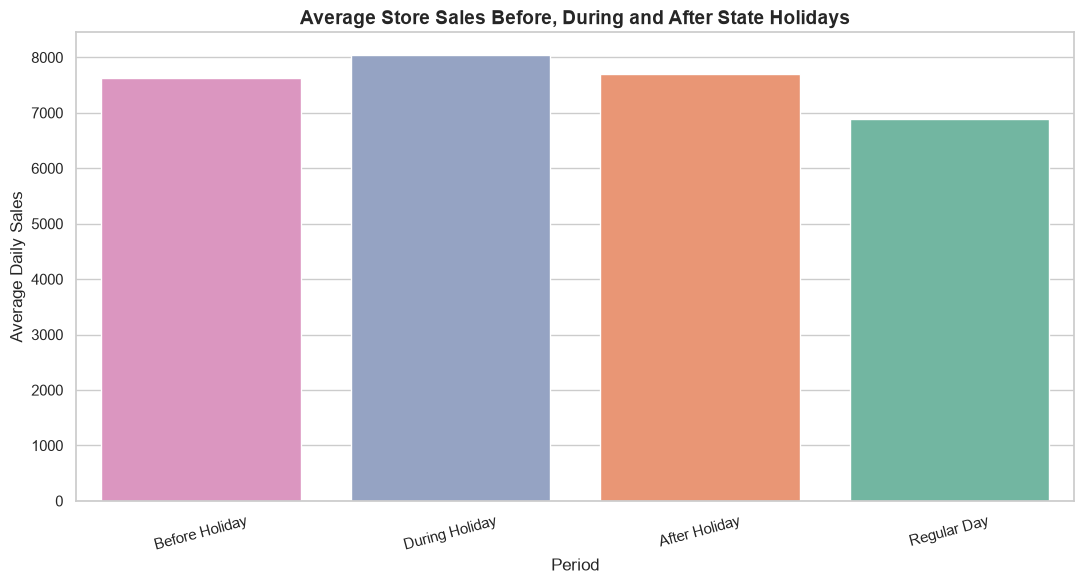

In [154]:
plot_order = [
    'Before Holiday',
    'During Holiday',
    'After Holiday',
    'Regular Day'
]

plt.figure(figsize=(11, 6))

sns.barplot(
    data=holiday_df,
    x='HolidayPeriod',
    y='Sales',
    order=plot_order,
    estimator='mean',
    errorbar=None,
    hue='HolidayPeriod',
    legend=False,
    palette='Set2'
)

plt.title(
    'Average Store Sales Before, During and After State Holidays',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Period')
plt.ylabel('Average Daily Sales')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [155]:
# Work with a copy of the training data
seasonal_df = train_df.copy()

seasonal_df['Date'] = pd.to_datetime(seasonal_df['Date'])

# Normalize holiday labels
seasonal_df['StateHoliday'] = (
    seasonal_df['StateHoliday']
    .astype(str)
    .replace({'0': 'None', 'nan': 'None'})
)

# Extract calendar features
seasonal_df['Year'] = seasonal_df['Date'].dt.year
seasonal_df['Month'] = seasonal_df['Date'].dt.month
seasonal_df['Day'] = seasonal_df['Date'].dt.day

# Default category
seasonal_df['SeasonalEvent'] = 'Regular Period'

# Christmas shopping period: December 1–26
christmas_mask = (
    (seasonal_df['Month'] == 12) &
    (seasonal_df['Day'] <= 26)
)
seasonal_df.loc[christmas_mask, 'SeasonalEvent'] = 'Christmas Period'

# New Year period: December 27–January 7
new_year_mask = (
    ((seasonal_df['Month'] == 12) & (seasonal_df['Day'] >= 27)) |
    ((seasonal_df['Month'] == 1) & (seasonal_df['Day'] <= 7))
)
seasonal_df.loc[new_year_mask, 'SeasonalEvent'] = 'New Year Period'

# Easter: use the dataset's existing Easter holiday indicator
easter_dates = seasonal_df.loc[
    seasonal_df['StateHoliday'] == 'b', 'Date'
].drop_duplicates()

for easter_date in easter_dates:
    easter_mask = (
        seasonal_df['Date'].between(
            easter_date - pd.Timedelta(days=7),
            easter_date + pd.Timedelta(days=7)
        )
    )
    seasonal_df.loc[easter_mask, 'SeasonalEvent'] = 'Easter Period'

# Identify the actual holiday dates separately
seasonal_df.loc[
    seasonal_df['StateHoliday'] == 'c', 'SeasonalEvent'
] = 'Christmas Holiday'

seasonal_df.loc[
    seasonal_df['StateHoliday'] == 'b', 'SeasonalEvent'
] = 'Easter Holiday'

print(seasonal_df['SeasonalEvent'].value_counts())

SeasonalEvent
Regular Period       870035
Easter Period         53520
Christmas Period      49200
New Year Period       33664
Easter Holiday         6690
Christmas Holiday      4100
Name: count, dtype: int64


## Seasonal Event Analysis

### 1. `StateHoliday` vs. `SeasonalEvent`

| Feature | Purpose | Example |
|---|---|---|
| `StateHoliday` | Identifies official state holidays and their categories | `a` = Public holiday, `b` = Easter, `c` = Christmas, `0` = No state holiday |
| `SeasonalEvent` | Identifies broader seasonal shopping periods | Christmas shopping period, New Year period, Easter lead-up |

**Why create `SeasonalEvent`?**

A date can have `StateHoliday = 0` and still belong to a seasonal shopping period. For example, December 15 may fall within the Christmas shopping season despite not being an official state holiday.

Therefore, `SeasonalEvent` captures broader seasonal purchasing patterns rather than duplicating `StateHoliday`.

### 2. Seasonal Event Classification Rules

| Category | Classification Rule |
|---|---|
| `Christmas Period` | December 1–26 |
| `New Year Period` | December 27–January 7, spanning two calendar years |
| `Easter Period` | Within seven days before or after a date marked `b` in `StateHoliday` |
| `Christmas Holiday` | Dates marked `c` in `StateHoliday` |
| `Easter Holiday` | Dates marked `b` in `StateHoliday` |
| `Regular Period` | Dates not assigned to any other category |

**Assignment Priority:** Broader seasonal windows are assigned first, followed by exact holiday labels. Consequently, exact Christmas and Easter holidays override their surrounding seasonal-period labels.

**Data Interpretation:** Counts represent store-day records, not unique calendar dates. For example, 49,200 records in the Christmas Period represent 49,200 store-day observations.

### 3. Analytical Applications

- **`StateHoliday`:** Compare sales on official holidays against non-holidays.
- **`SeasonalEvent`:** Examine sales and customer traffic across broader seasonal shopping windows.
- **Sales Comparison:** Analyze `Sales` and `Customers` across event categories to identify seasonal demand patterns.

> **Important:** Because the current categories are mutually exclusive, exact holiday dates are separated from their surrounding seasonal periods. To analyze the complete Christmas season, including Christmas Day, create a separate `ChristmasSeason` indicator.

### Conclusion

Combining `StateHoliday` and `SeasonalEvent` enables a more comprehensive analysis of official holidays and broader seasonal shopping behavior, supporting improved sales forecasting and inventory planning.

In [156]:
# Only open stores; retain genuine sales observations
seasonal_open = seasonal_df[
    seasonal_df['Open'] == 1
].copy()

seasonal_summary = (
    seasonal_open.groupby('SeasonalEvent')
    .agg(
        AverageSales=('Sales', 'mean'),
        MedianSales=('Sales', 'median'),
        AverageCustomers=('Customers', 'mean'),
        TotalRecords=('Sales', 'size')
    )
    .sort_values('AverageSales', ascending=False)
)

print(seasonal_summary.round(2))

                   AverageSales  MedianSales  AverageCustomers  TotalRecords
SeasonalEvent                                                               
Easter Holiday          9887.89       8423.0           1686.89           145
Christmas Holiday       9743.75       8397.0           1569.23            71
Christmas Period        8996.28       8227.0            913.28         42074
Easter Period           7577.63       6917.0            811.53         43687
New Year Period         7041.93       6460.0            770.40         24443
Regular Period          6797.77       6263.0            750.68        733972


> ❓ **Research Question:** *How do seasonal events, such as Christmas and Easter, influence sales performance and customer purchasing behavior compared with regular shopping periods?*
## 🍾Seasonal Event Analysis – Sales & Customer Behavior

- **Peak Sales:** Easter Holiday records the highest average sales (**9,887.89**) and average customer count (**1,686.89**).
- **Christmas Performance:** Christmas Holiday also shows high average sales, while the broader Christmas Period records strong sales across a much larger number of observations.
- **Seasonal Shopping:** The Christmas Period has higher average sales and customer traffic than the Easter and New Year periods.
- **New Year Period:** Average sales are only slightly higher than during regular periods.
- **Regular Period:** Records the lowest average sales (**6,797.77**) and average customer count (**750.68**).

### Business Insight

Seasonal events—particularly Easter and Christmas holidays—are associated with higher sales and customer traffic. These patterns can help guide seasonal inventory planning, staffing, and promotional strategies.

> **Conclusion:** Holiday dates show the strongest average sales performance, while the broader Christmas Period offers a substantial volume of observations for understanding seasonal demand.

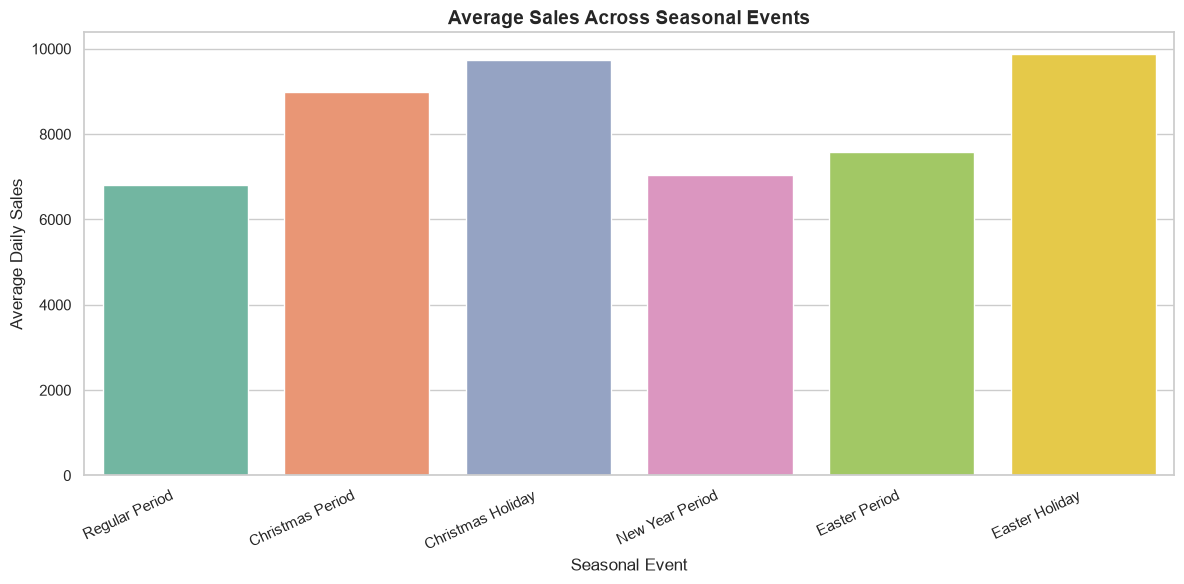

In [157]:
seasonal_plot_order = [
    'Regular Period',
    'Christmas Period',
    'Christmas Holiday',
    'New Year Period',
    'Easter Period',
    'Easter Holiday'
]

plot_summary = seasonal_summary.reindex(
    seasonal_plot_order
).dropna(subset=['AverageSales'])

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_summary.reset_index(),
    x='SeasonalEvent',
    y='AverageSales',
    hue='SeasonalEvent',
    legend=False,
    palette='Set2'
)

plt.title(
    'Average Sales Across Seasonal Events',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Seasonal Event')
plt.ylabel('Average Daily Sales')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

In [158]:
logger.info("=" * 70)
logger.info("Starting seasonal and holiday analysis")
logger.info("=" * 70)

try:
    for col in ["SeasonalEvent", "StateHoliday", "SchoolHoliday"]:
        if col in seasonal_df.columns:
            summary = seasonal_df[col].value_counts(dropna=False)

            logger.info(
                f"{col} distribution:\n{summary.to_string()}"
            )

    holiday_summary = (
        seasonal_df[train_df["Open"] == 1]
        .groupby("SeasonalEvent")
        .agg(
            AverageSales=("Sales", "mean"),
            AverageCustomers=("Customers", "mean"),
            TotalRecords=("Sales", "size")
        )
        .round(2)
    )

    logger.info(
        f"Seasonal sales and customer summary:\n"
        f"{holiday_summary.to_string()}"
    )

    logger.info("Seasonal and holiday analysis completed successfully")

except Exception:
    logger.exception("Error during seasonal and holiday analysis")


2026-11-10 11:23:11 | INFO | ======================================================================
2026-11-10 11:23:11 | INFO | Starting seasonal and holiday analysis
2026-11-10 11:23:11 | INFO | ======================================================================
2026-11-10 11:23:11 | INFO | SeasonalEvent distribution:
SeasonalEvent
Regular Period       870035
Easter Period         53520
Christmas Period      49200
New Year Period       33664
Easter Holiday         6690
Christmas Holiday      4100
2026-11-10 11:23:11 | INFO | StateHoliday distribution:
StateHoliday
None    986159
a        20260
b         6690
c         4100
2026-11-10 11:23:11 | INFO | SchoolHoliday distribution:
SchoolHoliday
0    835488
1    181721
2026-11-10 11:23:12 | INFO | Seasonal sales and customer summary:
                   AverageSales  AverageCustomers  TotalRecords
SeasonalEvent                                                  
Christmas Holiday       9743.75           1569.23            71
Christmas P

In [159]:
promo_df = train_df[train_df['Open'] == 1].copy()

promo_summary = (
    promo_df.groupby('Promo')
    .agg(
        AverageSales=('Sales', 'mean'),
        AverageCustomers=('Customers', 'mean'),
        MedianSales=('Sales', 'median'),
        Records=('Sales', 'size')
    )
)

promo_summary.index = promo_summary.index.map({
    0: 'No Promotion',
    1: 'Promotion'
})

print(promo_summary.round(2))

              AverageSales  AverageCustomers  MedianSales  Records
Promo                                                             
No Promotion       5929.41            696.86       5459.0   467496
Promotion          8228.28            844.43       7649.0   376896


In [160]:
no_promo = promo_summary.loc['No Promotion']
with_promo = promo_summary.loc['Promotion']

sales_change = (
    (with_promo['AverageSales'] - no_promo['AverageSales'])
    / no_promo['AverageSales'] * 100
)

customer_change = (
    (with_promo['AverageCustomers'] - no_promo['AverageCustomers'])
    / no_promo['AverageCustomers'] * 100
)

print(f"Sales change: {sales_change:.2f}%")
print(f"Customer traffic change: {customer_change:.2f}%")

Sales change: 38.77%
Customer traffic change: 21.18%


In [161]:
logger.info("=" * 70)
logger.info("Starting promotion effectiveness analysis")
logger.info("=" * 70)

try:
    promo_df = train_df[train_df["Open"] == 1]

    promo_summary = (
        promo_df.groupby("Promo")
        .agg(
            AverageSales=("Sales", "mean"),
            AverageCustomers=("Customers", "mean"),
            TotalRecords=("Sales", "size")
        )
        .round(2)
    )

    logger.info(
        f"Promotion performance summary:\n{promo_summary.to_string()}"
    )

    if 0 in promo_summary.index and 1 in promo_summary.index:
        sales_change = (
            (promo_summary.loc[1, "AverageSales"] -
             promo_summary.loc[0, "AverageSales"]) /
            promo_summary.loc[0, "AverageSales"] * 100
        )

        customer_change = (
            (promo_summary.loc[1, "AverageCustomers"] -
             promo_summary.loc[0, "AverageCustomers"]) /
            promo_summary.loc[0, "AverageCustomers"] * 100
        )

        logger.info(f"Sales change during promotions: {sales_change:.2f}%")
        logger.info(f"Customer change during promotions: {customer_change:.2f}%")

    logger.info("Promotion effectiveness analysis completed successfully")

except Exception:
    logger.exception("Error during promotion effectiveness analysis")


2026-11-10 11:23:13 | INFO | ======================================================================
2026-11-10 11:23:13 | INFO | Starting promotion effectiveness analysis
2026-11-10 11:23:13 | INFO | ======================================================================
2026-11-10 11:23:13 | INFO | Promotion performance summary:
       AverageSales  AverageCustomers  TotalRecords
Promo                                              
0           5929.41            696.86        467496
1           8228.28            844.43        376896
2026-11-10 11:23:13 | INFO | Sales change during promotions: 38.77%
2026-11-10 11:23:13 | INFO | Customer change during promotions: 21.18%
2026-11-10 11:23:13 | INFO | Promotion effectiveness analysis completed successfully


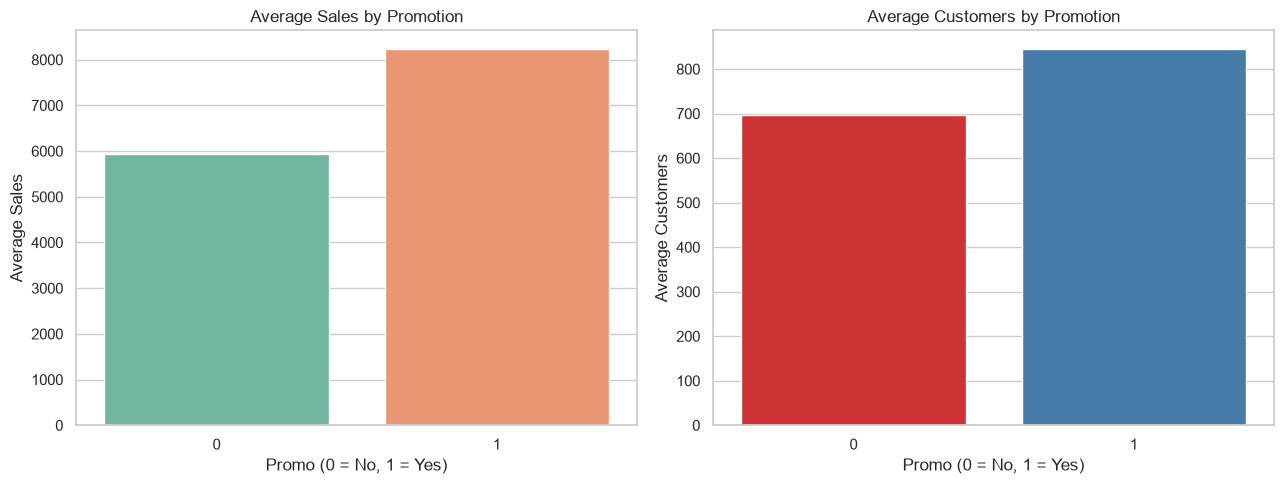

In [162]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=promo_df, x='Promo', y='Sales',
    hue='Promo', errorbar=None, legend=False,
    palette='Set2', ax=axes[0]
)
axes[0].set_title('Average Sales by Promotion')
axes[0].set_xlabel('Promo (0 = No, 1 = Yes)')
axes[0].set_ylabel('Average Sales')

sns.barplot(
    data=promo_df, x='Promo', y='Customers',
    hue='Promo', errorbar=None, legend=False,
    palette='Set1', ax=axes[1]
)
axes[1].set_title('Average Customers by Promotion')
axes[1].set_xlabel('Promo (0 = No, 1 = Yes)')
axes[1].set_ylabel('Average Customers')

plt.tight_layout()
plt.show()

In [163]:
spend_df = promo_df[promo_df['Customers'] > 0].copy()

spend_df['SalesPerCustomer'] = (
    spend_df['Sales'] / spend_df['Customers']
)

spend_summary = (
    spend_df.groupby('Promo')
    .agg(
        AverageSpendPerVisit=('SalesPerCustomer', 'mean'),
        TotalSales=('Sales', 'sum'),
        TotalCustomers=('Customers', 'sum')
    )
)

spend_summary.index = spend_summary.index.map({
    0: 'No Promotion',
    1: 'Promotion'
})

print(spend_summary.round(2))

              AverageSpendPerVisit  TotalSales  TotalCustomers
Promo                                                         
No Promotion                  8.94  2771974337       325777807
Promotion                    10.18  3101206286       318263948


In [164]:
spend_summary['WeightedSalesPerCustomer'] = (
    spend_summary['TotalSales'] /
    spend_summary['TotalCustomers']
)

print(spend_summary[['WeightedSalesPerCustomer']].round(2))

              WeightedSalesPerCustomer
Promo                                 
No Promotion                      8.51
Promotion                         9.74


> ❓ **Research Question:** *How do promotional activities influence sales performance, customer traffic, and spending behaviour, and to what extent do they attract additional customers or encourage existing customers to spend more?*
## 🦯Impact of Promotions on Sales and Customer Behaviour

| Performance Metric | No Promotion | Promotion | Change |
|:--|--:|--:|--:|
| Average Sales | 5,929.41 | 8,228.28 | **+38.77%** |
| Average Customers | 696.86 | 844.43 | **+21.18%** |
| Median Sales | 5,459.00 | 7,649.00 | **+40.12%** |
| Average Spend per Visit | 8.94 | 10.18 | **+13.87%** |
| Weighted Sales per Customer | 8.51 | 9.74 | **+14.45%** |
| Total Sales | 2,771,974,337 | 3,101,206,286 | **+11.88%** |
| Total Customers | 325,777,807 | 318,263,948 | **−2.31%** |

### 🔎Key Findings

#### 1️⃣ Promotions Increase Sales Performance
Average sales were **38.77% higher** on promotional days than on non-promotional days. Median sales also increased by approximately **40.12%**, indicating that the higher sales level is reflected in the typical store-day, rather than being driven solely by a few unusually high-sales observations.

#### 2️⃣ Promotions Are Associated with Higher Customer Traffic
Average customer traffic increased by **21.18%** during promotional periods. This suggests that promotions may encourage more customers to visit stores, although the observational data alone cannot establish that promotions caused the increase.

#### 3️⃣ Customers Spend More During Promotions
Average spend per visit increased from **8.94 to 10.18**, a rise of approximately **13.87%**. Weighted sales per customer also increased from **8.51 to 9.74**.

This suggests that promotional periods are associated not only with higher customer traffic but also with higher spending per customer. However, these figures do not prove that existing customers individually spent more, because the dataset does not identify and track the same customers across promotional and non-promotional days.

#### 4️⃣ Total Sales and Customer Counts Require Careful Interpretation
Despite higher average sales and customer traffic during promotions, total customer counts were approximately **2.31% lower** in the promotion group, while total sales were **11.88% higher**.

This difference may reflect variations in the number of records, stores, dates, or trading conditions represented in each group. Therefore, total figures should not be compared in isolation. Average and per-customer metrics provide a more useful view of promotional performance, provided the groups are comparable.

### 👥Business Implications

- **Customer acquisition:** Promotions are associated with higher average customer traffic and may help attract additional shoppers.
- **Revenue growth:** Higher average sales suggest that promotional periods can coincide with stronger store-level sales performance.
- **Customer spending:** Increased spending metrics indicate that promotions may encourage larger purchases or changes in purchasing patterns.
- **Further evaluation:** To establish whether promotions are profitable, their incremental revenue should be compared with discount costs, promotional expenses, and profit margins.

### Conclusion

Promotional periods are associated with **higher average sales (+38.77%), greater average customer traffic (+21.18%), and higher average spending per visit (+13.87%)**. These results suggest that promotions may support both customer attraction and increased spending.

However, the available data cannot confirm whether the additional visitors are new or returning customers, nor whether the same existing customers spend more during promotions. Customer-level tracking and a comparison of promotional costs against incremental profit would be needed to establish the full effectiveness of these campaigns.

In [165]:
promo_store_df = train_df[train_df['Open'] == 1].copy()

store_promo_summary = (
    promo_store_df.groupby(['Store', 'Promo'])
    .agg(
        AverageSales=('Sales', 'mean'),
        AverageCustomers=('Customers', 'mean'),
        NumberOfDays=('Sales', 'size')
    )
    .reset_index()
)

In [166]:
# Reshape the summary so each store has one row
sales_pivot = store_promo_summary.pivot(
    index='Store',
    columns='Promo',
    values='AverageSales'
)

customers_pivot = store_promo_summary.pivot(
    index='Store',
    columns='Promo',
    values='AverageCustomers'
)

days_pivot = store_promo_summary.pivot(
    index='Store',
    columns='Promo',
    values='NumberOfDays'
)

store_results = pd.DataFrame(index=sales_pivot.index)

store_results['Sales_NoPromo'] = sales_pivot.get(0)
store_results['Sales_Promo'] = sales_pivot.get(1)

store_results['Customers_NoPromo'] = customers_pivot.get(0)
store_results['Customers_Promo'] = customers_pivot.get(1)

store_results['Days_NoPromo'] = days_pivot.get(0)
store_results['Days_Promo'] = days_pivot.get(1)

# Require sufficient observations in both groups
store_results = store_results.dropna(
    subset=['Sales_NoPromo', 'Sales_Promo']
)

store_results = store_results[
    (store_results['Days_NoPromo'] >= 10) &
    (store_results['Days_Promo'] >= 10)
].copy()

store_results['SalesUpliftPct'] = (
    (store_results['Sales_Promo'] - store_results['Sales_NoPromo'])
    / store_results['Sales_NoPromo'].replace(0, np.nan)
) * 100

store_results['CustomerUpliftPct'] = (
    (store_results['Customers_Promo'] - store_results['Customers_NoPromo'])
    / store_results['Customers_NoPromo'].replace(0, np.nan)
) * 100

store_results = store_results.replace(
    [np.inf, -np.inf], np.nan
)

store_results = store_results.dropna(
    subset=['SalesUpliftPct']
)

store_results = store_results.sort_values(
    'SalesUpliftPct', ascending=False
)

print("Top 15 stores by observed sales uplift:")
print(
    store_results[
        [
            'Sales_NoPromo', 'Sales_Promo',
            'SalesUpliftPct', 'CustomerUpliftPct',
            'Days_NoPromo', 'Days_Promo'
        ]
    ].head(15).round(2)
)

Top 15 stores by observed sales uplift:
       Sales_NoPromo  Sales_Promo  SalesUpliftPct  CustomerUpliftPct  \
Store                                                                  
198          1753.46      4294.73          144.93              87.32   
607          2551.57      5542.97          117.24              73.87   
543          1868.13      3926.07          110.16              60.10   
575          3614.41      7586.11          109.89              68.57   
693          4577.87      9107.82           98.95              60.75   
271          5452.70     10746.49           97.09              63.85   
552          5412.45     10565.75           95.21              51.73   
96           3638.35      7047.62           93.70              60.44   
635          4159.05      8048.37           93.51              63.23   
489          5143.06      9950.41           93.47              57.26   
1108         4047.10      7813.76           93.07              62.05   
286          3475.24    

In [167]:
store_results['OpportunityScore'] = (
    store_results['SalesUpliftPct'].rank(pct=True) * 0.5
    + (
        1 - store_results['Sales_NoPromo'].rank(pct=True)
    ) * 0.5
)

promotion_candidates = store_results[
    (store_results['SalesUpliftPct'] > 0) &
    (store_results['CustomerUpliftPct'] > 0)
].sort_values('OpportunityScore', ascending=False)

print("Candidate stores for targeted promotion tests:")
print(
    promotion_candidates[
        [
            'Sales_NoPromo', 'Sales_Promo',
            'SalesUpliftPct', 'CustomerUpliftPct',
            'OpportunityScore'
        ]
    ].head(15).round(2)
)

Candidate stores for targeted promotion tests:
       Sales_NoPromo  Sales_Promo  SalesUpliftPct  CustomerUpliftPct  \
Store                                                                  
198          1753.46      4294.73          144.93              87.32   
543          1868.13      3926.07          110.16              60.10   
607          2551.57      5542.97          117.24              73.87   
972          2487.68      4544.97           82.70              51.92   
786          2598.96      4742.77           82.49              55.44   
307          1991.62      3569.16           79.21              48.93   
1030         2652.80      4781.40           80.24              56.12   
460          2739.63      4953.80           80.82              51.94   
72           3182.93      5985.52           88.05              52.80   
688          2691.96      4745.02           76.27              49.03   
649          2733.90      4844.77           77.21              49.17   
908          3096

## 🎯 Promotion Opportunity Score: Calculation Methodology

### 1. Sales Uplift (%)

Sales uplift measures the percentage change in a store's average sales on promotion days compared with non-promotion days.

$
\text{Sales Uplift (\%)} =
\frac{\text{Sales}_{Promo}-\text{Sales}_{NoPromo}}
{\text{Sales}_{NoPromo}}\times100
$

- **Positive uplift:** Average sales are higher during promotions.
- **Negative uplift:** Average sales are lower during promotions.
- **Zero uplift:** Average sales are equal in both periods.

### 2. Customer Uplift (%)

Customer uplift measures the percentage change in a store's average customer count on promotion days compared with non-promotion days.

$
\text{Customer Uplift (\%)} =
\frac{\text{Customers}_{Promo}-\text{Customers}_{NoPromo}}
{\text{Customers}_{NoPromo}}\times100
$

- **Positive uplift:** Average customer traffic is higher during promotions.
- **Negative uplift:** Average customer traffic is lower during promotions.
- **Zero uplift:** Average customer traffic is equal in both periods.

### 3. Opportunity Score Calculation

The **Opportunity Score** ranks stores by their relative sales uplift and their average sales on non-promotion days. Both factors receive equal weights of **50%**.

The calculation uses percentile ranks, allowing stores to be compared based on their relative positions within the dataset.

#### Formula

$
\begin{aligned}
\text{Opportunity Score} ={}&
0.5 \times \text{Sales Uplift Rank}\\
&+ 0.5 \times (1-\text{Non-Promo Sales Rank})
\end{aligned}
$

Where:

- **Sales Uplift Rank:** The percentile rank of `SalesUpliftPct`. A higher rank indicates stronger relative sales uplift.
- **Non-Promo Sales Rank:** The percentile rank of `Sales_NoPromo`. Its inverse is used so that stores with lower non-promotion sales receive higher scores.
- **Equal weighting:** Each factor contributes 50% to the final score.

### 4. Interpretation of the Opportunity Score

| Factor | Higher Score Favours |
|:--|:--|
| Sales Uplift Percentile | Stores with stronger relative promotional sales uplift |
| Inverse Non-Promo Sales Percentile | Stores with lower average sales without promotions |
| Combined Opportunity Score | Stores that perform well on both criteria |

A higher Opportunity Score indicates a more promising combination of promotional sales uplift and potential scope for improving non-promotion sales. It does **not** directly measure expected incremental revenue or profitability.

Customer uplift is calculated separately to help assess whether sales improvements coincide with higher customer traffic. It is not directly included in the current Opportunity Score formula.

> **Important:** This score is a relative prioritisation measure, not proof that additional promotions will be successful. Stores should be validated using customer uplift, comparable trading periods, promotional costs, and incremental profitability before a wider rollout.

In [168]:
promotion_candidates.shape

(1101, 9)

In [169]:
# Overall promotion performance across comparable stores
print("Number of comparable stores:", len(store_results))

print("\nOverall uplift summary:")
print(
    store_results[
        ['SalesUpliftPct', 'CustomerUpliftPct']
    ].describe().round(2)
)

# Count stores by observed sales uplift
print("\nSales uplift categories:")
print(
    pd.cut(
        store_results['SalesUpliftPct'],
        bins=[-float('inf'), 0, 10, 20, 50, float('inf')],
        labels=[
            'Negative uplift',
            '0–10%',
            '10–20%',
            '20–50%',
            'Above 50%'
        ]
    ).value_counts().sort_index()
)

Number of comparable stores: 1115

Overall uplift summary:
       SalesUpliftPct  CustomerUpliftPct
count         1115.00            1115.00
mean            41.43              23.84
std             18.10              12.65
min             -6.95              -7.26
25%             29.36              15.00
50%             40.56              22.66
75%             51.84              31.51
max            144.93              87.32

Sales uplift categories:
SalesUpliftPct
Negative uplift      1
0–10%               27
10–20%              85
20–50%             689
Above 50%          313
Name: count, dtype: int64


In [170]:
# Get one row of store characteristics per store
store_info = (
    train_df[
        ['Store', 'StoreType', 'Assortment',
         'CompetitionDistance', 'Promo2']
    ]
    .drop_duplicates(subset='Store')
)

# Combine store characteristics with promotion performance
store_analysis = (
    store_results.reset_index()
    .merge(store_info, on='Store', how='left')
)

# Compare uplift by store type
store_type_analysis = (
    store_analysis.groupby('StoreType', observed=True)
    .agg(
        NumberOfStores=('Store', 'nunique'),
        AverageSalesUplift=('SalesUpliftPct', 'mean'),
        MedianSalesUplift=('SalesUpliftPct', 'median'),
        AverageCustomerUplift=('CustomerUpliftPct', 'mean')
    )
    .sort_values('MedianSalesUplift', ascending=False)
)

print(store_type_analysis.round(2))

           NumberOfStores  AverageSalesUplift  MedianSalesUplift  \
StoreType                                                          
a                     602               45.82              43.96   
d                     348               37.48              36.50   
c                     148               35.46              34.02   
b                      17               19.09              10.25   

           AverageCustomerUplift  
StoreType                         
a                          27.90  
d                          19.85  
c                          18.01  
b                          12.42  


In [171]:
promotion_candidates.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Sales_NoPromo,1101.0,5865.25,2136.81,1753.46,4450.28,5537.36,6795.08,19549.99
Sales_Promo,1101.0,8185.26,2686.14,3242.84,6379.94,7840.12,9424.21,25168.96
Customers_NoPromo,1101.0,679.73,327.61,189.22,483.87,604.36,779.00,3322.53
Customers_Promo,1101.0,833.57,368.80,279.90,605.48,753.98,955.03,3534.29
Days_NoPromo,1101.0,418.82,37.18,329.00,428.00,429.00,431.00,582.00
Days_Promo,1101.0,337.91,28.57,263.00,348.00,350.00,352.00,360.00
SalesUpliftPct,1101.0,41.87,17.78,2.71,29.65,40.91,52.03,144.93
CustomerUpliftPct,1101.0,24.18,12.35,0.07,15.22,22.98,31.58,87.32
OpportunityScore,1101.0,0.51,0.24,0.02,0.34,0.49,0.69,1.00


In [172]:
selected_top_priority=promotion_candidates[
    (promotion_candidates['OpportunityScore'] > 0.70) & 
    (promotion_candidates['SalesUpliftPct'] > 50.00) & 
    (promotion_candidates['CustomerUpliftPct'] > 30.00)
]
selected_top_priority

,Sales_NoPromo,Sales_Promo,Customers_NoPromo,Customers_Promo,Days_NoPromo,Days_Promo,SalesUpliftPct,CustomerUpliftPct,OpportunityScore
Store,,,,,,,,,
198,1753.461538,4294.725212,242.778555,454.781870,429,353,144.928396,87.323740,0.999552
543,1868.129930,3926.065714,189.222738,302.937143,431,350,110.160206,60.095529,0.998206
607,2551.573427,5542.971671,310.526807,539.917847,429,353,117.237396,73.871574,0.996413
972,2487.678851,4544.971787,313.778068,476.680251,383,319,82.699298,51.916370,0.986099
786,2598.960373,4742.769231,442.596737,687.982906,429,351,82.487170,55.442381,0.983857
...,...,...,...,...,...,...,...,...,...
401,5463.429907,8927.122159,535.369159,782.389205,428,352,63.397761,46.140134,0.707175
138,5597.733645,9447.176136,582.317757,875.096591,428,352,68.767875,50.278191,0.707175
759,5461.244755,8908.637143,662.365967,911.828571,429,350,63.124664,37.662352,0.705830


In [173]:
# Select high-opportunity stores

selected_stores = selected_top_priority

print("=" * 65)
print("HIGH-OPPORTUNITY STORE SELECTION")
print("=" * 65)
print("Opportunity score threshold: 0.70")
print("Sales uplift threshold: 50%")
print("Customer uplift threshold: 30%")
print("Number of high-opportunity stores:", len(selected_stores))

# Reset index so Store becomes a regular column
selected_stores = selected_stores.reset_index()

# Ensure Store is a regular column
if 'Store' not in selected_stores.columns:
    selected_stores = selected_stores.rename(
        columns={selected_stores.columns[0]: 'Store'}
    )

print("\nSelected stores:")
print(
    selected_stores[
        ['Store', 'SalesUpliftPct',
         'CustomerUpliftPct', 'OpportunityScore']
    ]
    .sort_values('OpportunityScore', ascending=False)
    .round(2)
    .to_string(index=False)
)


HIGH-OPPORTUNITY STORE SELECTION
Opportunity score threshold: 0.70
Sales uplift threshold: 50%
Customer uplift threshold: 30%
Number of high-opportunity stores: 188

Selected stores:
 Store  SalesUpliftPct  CustomerUpliftPct  OpportunityScore
   198          144.93              87.32              1.00
   543          110.16              60.10              1.00
   607          117.24              73.87              1.00
   972           82.70              51.92              0.99
   786           82.49              55.44              0.98
   307           79.21              48.93              0.98
  1030           80.24              56.12              0.98
   460           80.82              51.94              0.98
    72           88.05              52.80              0.97
   688           76.27              49.03              0.97
   649           77.21              49.17              0.97
   908           82.06              46.96              0.97
   841           69.73              4

> ❓ **Research Question :** *Which stores should promos be deployed in?*
## 🎯 Promotion Opportunity Identification

### Objective
Identify stores with strong potential for improving sales through targeted promotional campaigns.

### Methodology
A store-level promotion analysis was conducted to identify potential promotional opportunities. An **Opportunity Score** was developed by combining two equally weighted factors:

- **Sales Uplift Ranking:** Evaluates stores based on their relative sales improvement during promotional periods.
- **Non-Promotion Sales Ranking (Inverse):** Prioritizes stores with comparatively lower average sales on non-promotion days, indicating potential scope for improvement.

Stores with an **Opportunity Score ≥ 0.70** were shortlisted for further evaluation.

### Key Finding

| Metric | Result |
|:--|--:|
| Opportunity Score Threshold | ≥ 0.70 |
| Selected Stores | **188** |
| Ranking Factor Weights | 50% each |

### Business Insights
The 188 shortlisted stores represent potential candidates for targeted promotional campaigns. Their scores indicate a combination of promising promotional sales uplift and opportunities to improve performance on non-promotion days.

However, a high Opportunity Score does not guarantee that additional promotions will generate higher profits. The shortlisted stores require further assessment of:

- **Sales and Customer Uplift:** Measure changes in revenue and customer traffic during promotions.
- **Comparable Trading Periods:** Account for differences in weekdays, seasonality, holidays, and store operating conditions.
- **Promotional Costs and Profitability:** Evaluate discount expenses, incremental revenue, and profit margins.
- **Campaign Effectiveness:** Determine whether promotional gains are sustained beyond the campaign period.

### Recommendation
Conduct a **controlled pilot campaign** across selected stores before expanding promotional activities to the entire shortlist. Compare pilot stores with similar control stores that do not receive the additional promotion.

The final rollout decision should be based on measurable incremental sales, customer response, and profitability rather than the Opportunity Score alone.

> **Conclusion:** The analysis identifies 188 stores for further promotional evaluation. A controlled pilot will help validate whether targeted promotions deliver sustainable and profitable sales improvements.

In [174]:
logger.info("=" * 70)
logger.info("Starting store-level promotion deployment analysis")
logger.info("=" * 70)

try:
    logger.info(f"Stores evaluated: {len(store_results)}")

    logger.info(
        f"Sales uplift statistics:\n"
        f"{store_results['SalesUpliftPct'].describe().round(2).to_string()}"
    )

    logger.info(
        f"Customer uplift statistics:\n"
        f"{store_results['CustomerUpliftPct'].describe().round(2).to_string()}"
    )

    logger.info(
        f"Opportunity score statistics:\n"
        f"{store_results['OpportunityScore'].describe().round(2).to_string()}"
    )

    high_opportunity = store_results[
        store_results["OpportunityScore"] >= 0.70
    ]

    logger.info(
        f"High-opportunity stores (score >= 0.70): "
        f"{len(high_opportunity)}"
    )

    logger.info(
        f"Top 10 opportunity stores:\n"
        f"{store_results.sort_values('OpportunityScore', ascending=False).head(10).to_string()}"
    )

    logger.info("Store-level promotion deployment analysis completed successfully")

except Exception:
    logger.exception("Error during store-level promotion deployment analysis")

2026-11-10 11:23:20 | INFO | ======================================================================
2026-11-10 11:23:20 | INFO | Starting store-level promotion deployment analysis
2026-11-10 11:23:20 | INFO | ======================================================================
2026-11-10 11:23:20 | INFO | Stores evaluated: 1115
2026-11-10 11:23:20 | INFO | Sales uplift statistics:
count    1115.00
mean       41.43
std        18.10
min        -6.95
25%        29.36
50%        40.56
75%        51.84
max       144.93
2026-11-10 11:23:20 | INFO | Customer uplift statistics:
count    1115.00
mean       23.84
std        12.65
min        -7.26
25%        15.00
50%        22.66
75%        31.51
max        87.32
2026-11-10 11:23:20 | INFO | Opportunity score statistics:
count    1115.00
mean        0.50
std         0.24
min         0.00
25%         0.33
50%         0.49
75%         0.69
max         1.00
2026-11-10 11:23:20 | INFO | High-opportunity stores (score >= 0.70): 263
2026-11-10 11:23

In [175]:
# Extract one record per store

store_info = (
    train_df[
        [
            'Store',
            'StoreType',
            'Assortment',
            'CompetitionDistance',
            'Promo2'
        ]
    ]
    .drop_duplicates(subset='Store')
    .copy()
)

# Merge store-level characteristics with promotion metrics
selected_store_analysis = selected_stores.merge(
    store_info,
    on='Store',
    how='left',
    validate='one_to_one'
)

print("\nSelected stores after merging characteristics:",
      selected_store_analysis['Store'].nunique())

print("\nSelected store details:")
print(
    selected_store_analysis[
        [
            'Store', 'StoreType', 'Assortment',
            'CompetitionDistance', 'Promo2',
            'Sales_NoPromo', 'Sales_Promo',
            'SalesUpliftPct', 'CustomerUpliftPct',
            'OpportunityScore'
        ]
    ]
    .sort_values('OpportunityScore', ascending=False)
    .round(2)
    .to_string(index=False)
)


Selected stores after merging characteristics: 188

Selected store details:
 Store StoreType Assortment  CompetitionDistance  Promo2  Sales_NoPromo  Sales_Promo  SalesUpliftPct  CustomerUpliftPct  OpportunityScore
   198         a          a                290.0       1        1753.46      4294.73          144.93              87.32              1.00
   543         c          a               1080.0       0        1868.13      3926.07          110.16              60.10              1.00
   607         a          a                350.0       1        2551.57      5542.97          117.24              73.87              1.00
   972         a          a              14960.0       0        2487.68      4544.97           82.70              51.92              0.99
   786         a          a                290.0       1        2598.96      4742.77           82.49              55.44              0.98
   307         a          a              16107.5       0        1991.62      3569.16           

In [176]:
# Build the comparison dataset

store_analysis = store_results.reset_index().copy()

# Handle the case where Store is still the index
if 'Store' not in store_analysis.columns:
    store_analysis = store_analysis.rename(
        columns={store_analysis.columns[0]: 'Store'}
    )

store_analysis = store_analysis.merge(
    store_info,
    on='Store',
    how='left',
    validate='one_to_one'
)

store_analysis['StoreGroup'] = np.where(
    ((store_analysis['OpportunityScore'] >= 0.70) & (store_analysis['CustomerUpliftPct'] >= 30.00) & (store_analysis['SalesUpliftPct'] >= 50.00)),
    'High Opportunity',
    'Other Stores'
)

print("\nStore group counts:")
print(store_analysis['StoreGroup'].value_counts())

# Compare uplift metrics between groups
group_summary = (
    store_analysis.groupby('StoreGroup')
    .agg(
        NumberOfStores=('Store', 'nunique'),
        AverageSalesUplift=('SalesUpliftPct', 'mean'),
        MedianSalesUplift=('SalesUpliftPct', 'median'),
        AverageCustomerUplift=('CustomerUpliftPct', 'mean'),
        MedianCustomerUplift=('CustomerUpliftPct', 'median'),
        AverageOpportunityScore=('OpportunityScore', 'mean')
    )
)

print("\nHigh-opportunity vs other-store comparison:")
print(group_summary.round(2).to_string())



Store group counts:
StoreGroup
Other Stores        927
High Opportunity    188
Name: count, dtype: int64

High-opportunity vs other-store comparison:
                  NumberOfStores  AverageSalesUplift  MedianSalesUplift  AverageCustomerUplift  MedianCustomerUplift  AverageOpportunityScore
StoreGroup                                                                                                                                   
High Opportunity             188               68.08              64.67                  42.40                 40.58                     0.85
Other Stores                 927               36.03              36.27                  20.07                 20.03                     0.43


## 📊 High-Opportunity Stores vs. Other Stores

Compare high-opportunity stores with other stores to assess differences in promotional sales uplift, customer uplift, and Opportunity Scores.

### 1. Store Group Distribution

| Store Group | Number of Stores | Share of Stores |
|:--|--:|--:|
| High Opportunity | **188** | 16.86% |
| Other Stores | 927 | 83.14% |
| **Total** | **1,115** | **100%** |

### 🔎 Key Findings

**Stronger promotional sales uplift:** High-opportunity stores achieved an average sales uplift of **68.08%**, compared with 36.03% for other stores. Their median uplift was also higher at 64.67%, indicating a stronger typical promotional response.

**Greater customer uplift:** Average customer uplift reached **42.40%** in high-opportunity stores, compared with 20.07% in other stores. This suggests that promotional periods are associated with a stronger increase in customer traffic among the selected stores.

### 🛃 Business Implications

- **Prioritise targeted promotions:** The 188 selected stores are promising candidates for a promotional pilot.
- **Evaluate customer response:** Higher customer uplift suggests potential to increase store traffic, though the data cannot distinguish new customers from returning customers.
- **Measure profitability:** Assess incremental revenue against discount costs and other campaign expenses.
- **Validate through controlled testing:** Compare pilot stores with similar control stores to estimate the incremental effect of promotions.

### Conclusion

The analysis identifies **188 high-opportunity stores (16.86% of all stores)** with stronger sales and customer uplift than the remaining 927 stores. Their average sales uplift of 68.08% and average customer uplift of 42.40% make them promising candidates for targeted promotional testing.

A controlled pilot is recommended before a wider rollout to determine whether these differences translate into sustainable incremental sales and improved profitability.

> **Analytical note:** Sales uplift contributes directly to the Opportunity Score, so the higher score in the selected group is expected. Customer uplift provides an additional comparison, but these observational results alone do not prove that promotions caused the increases.


Store type comparison:
      StoreGroup StoreType  NumberOfStores  MedianSalesUplift  MedianCustomerUplift  AverageOpportunityScore
High Opportunity         a             148              66.69                 41.91                     0.85
High Opportunity         b               1              61.36                 41.52                     0.77
High Opportunity         c              15              61.80                 36.34                     0.83
High Opportunity         d              24              63.90                 37.15                     0.83
    Other Stores         a             454              39.68                 23.35                     0.45
    Other Stores         b              16               9.82                  8.02                     0.17
    Other Stores         c             133              32.51                 16.41                     0.39
    Other Stores         d             324              35.19                 17.62                     

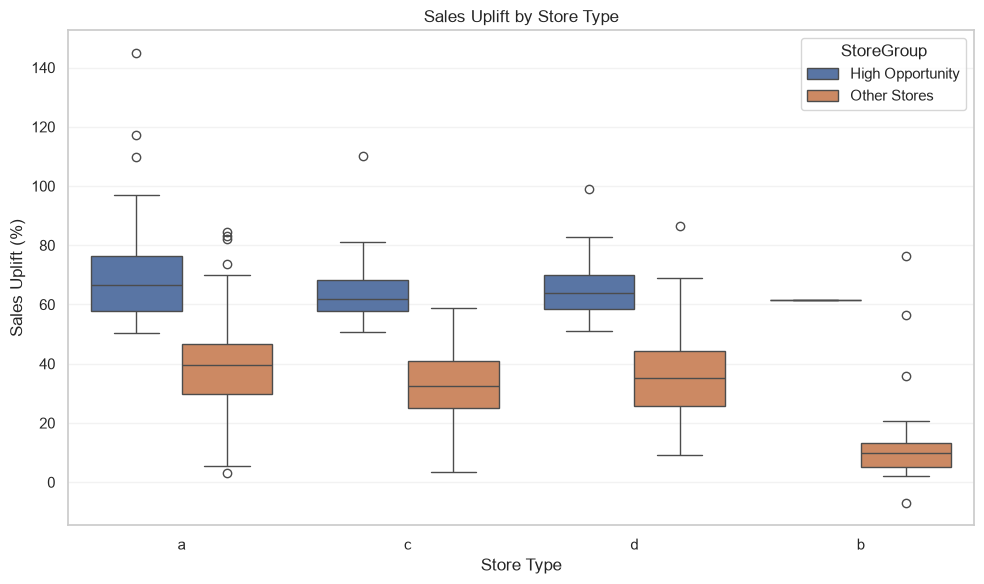

In [177]:
# Store type analysis

store_type_analysis = (
    store_analysis.groupby(
        ['StoreGroup', 'StoreType'],
        observed=True
    )
    .agg(
        NumberOfStores=('Store', 'nunique'),
        MedianSalesUplift=('SalesUpliftPct', 'median'),
        MedianCustomerUplift=('CustomerUpliftPct', 'median'),
        AverageOpportunityScore=('OpportunityScore', 'mean')
    )
    .reset_index()
)

print("\nStore type comparison:")
print(store_type_analysis.round(2).to_string(index=False))

# Visualize sales uplift by store type and group
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=store_analysis,
    x='StoreType',
    y='SalesUpliftPct',
    hue='StoreGroup'
)

plt.title('Sales Uplift by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Sales Uplift (%)')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


> ❓ **Research Question :** *Could the promos be deployed in more effective ways?*
## 🔍 Key Findings

- **Store Type A offers the greatest deployment potential:** With 148 high-opportunity stores, Type A represents the largest selected group. Its median sales uplift is **66.69%**, accompanied by a median customer uplift of **41.91%**.
- **Store Type D demonstrates strong sales uplift:** High-opportunity Type D stores record a median sales uplift of **63.90%** and a median customer uplift of **37.15%**, making them promising candidates for targeted campaigns.
- **Store Type C also shows promising results:** High-opportunity Type C stores achieve a median sales uplift of **61.80%** and customer uplift of **36.34%**.
- **High-opportunity stores outperform other stores within every store type:** Each category shows higher median sales and customer uplift in the high-opportunity group than in its corresponding other-store group.
- **Store Type B requires further investigation:** Only one Type B store is classified as high opportunity. Its results are insufficient to support category-wide conclusions, while other Type B stores show comparatively low median sales uplift of **9.82%**.

## 💼 Business Recommendations: More Effective Promotional Deployment

- **Prioritise Store Type A:** Begin with selected high-opportunity Type A stores because they offer the largest pool of candidates and strong observed sales and customer uplift.
- **Include Store Types D and C in pilot campaigns:** Test targeted promotions in these stores to determine whether their promising uplift translates into incremental profit.
- **Customise promotional strategies:** Experiment with different discount levels, product bundles, and complementary-product offers to increase sales while protecting profit margins.
- **Optimise campaign timing:** Align promotions with store-specific demand patterns, seasonal periods, and relevant holidays. Compare similar trading days to avoid misleading performance comparisons.
- **Measure business outcomes:** Track incremental sales, customer traffic, average basket value, discount costs, and gross profit to assess the true effectiveness of each campaign.
- **Scale based on controlled testing:** Compare participating stores with similar control stores that do not receive the additional promotion. Expand only campaigns that demonstrate measurable incremental benefits.

> **Recommendation:** Prioritise Type A stores for initial testing, followed by selected Type D and Type C stores. Validate profitability through controlled pilots before scaling campaigns. Treat Type B as a separate investigation rather than making decisions based on its limited high-opportunity sample.


Assortment comparison:
      StoreGroup Assortment  NumberOfStores  MedianSalesUplift  MedianCustomerUplift  AverageOpportunityScore
High Opportunity          a             152              67.96                 42.00                     0.86
High Opportunity          c              36              60.21                 37.48                     0.81
    Other Stores          a             441              37.98                 21.75                     0.46
    Other Stores          b               9               7.66                  7.24                     0.14
    Other Stores          c             477              35.03                 19.03                     0.41


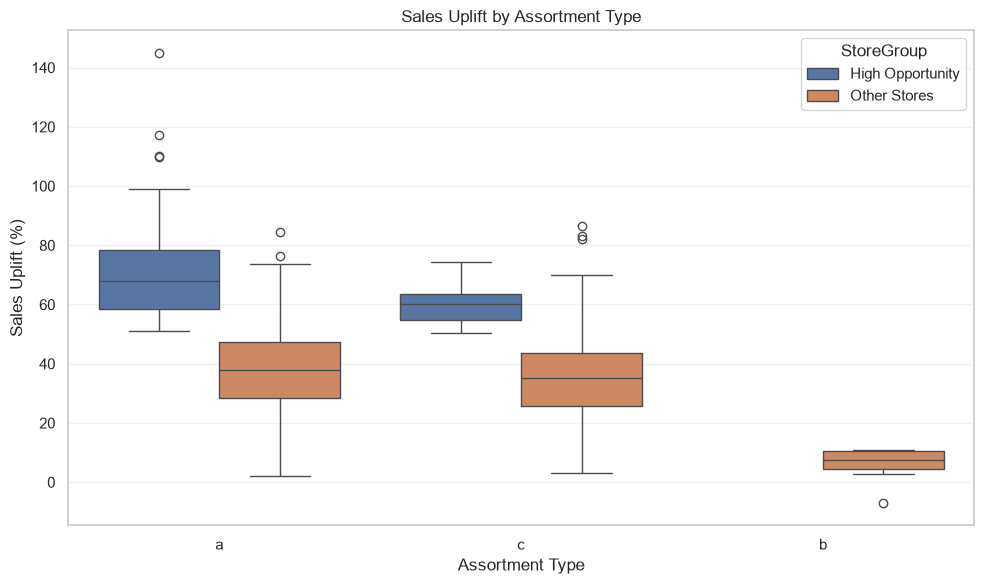

In [178]:
# Assortment analysis

assortment_analysis = (
    store_analysis.groupby(
        ['StoreGroup', 'Assortment'],
        observed=True
    )
    .agg(
        NumberOfStores=('Store', 'nunique'),
        MedianSalesUplift=('SalesUpliftPct', 'median'),
        MedianCustomerUplift=('CustomerUpliftPct', 'median'),
        AverageOpportunityScore=('OpportunityScore', 'mean')
    )
    .reset_index()
)

print("\nAssortment comparison:")
print(assortment_analysis.round(2).to_string(index=False))

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=store_analysis,
    x='Assortment',
    y='SalesUpliftPct',
    hue='StoreGroup'
)

plt.title('Sales Uplift by Assortment Type')
plt.xlabel('Assortment Type')
plt.ylabel('Sales Uplift (%)')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


> ❓ **Research Question :** *Could the promos be deployed in more effective ways?*
## 🔍 Key Findings

- **Assortment A shows the strongest promotional potential:** Among high-opportunity stores, Assortment A has 152 stores, with a median sales uplift of **67.96%** and median customer uplift of **42.00%**.
- **Assortment C offers additional opportunities:** The 36 high-opportunity stores with Assortment C achieve a median sales uplift of **60.21%** and customer uplift of **37.48%**.
- **High-opportunity stores outperform other stores:** Both Assortments A and C show higher median sales and customer uplift in the high-opportunity group than in their respective other-store groups.
- **Assortment B needs further investigation:** Only nine stores with Assortment B appear in the other-store group, with median sales uplift of 7.66% and customer uplift of 7.24%. No Assortment B stores were classified as high opportunity, so further analysis is needed before drawing broader conclusions.

## 💼 Business Recommendations: More Effective Promotional Deployment

- **Prioritise Assortment A stores:** Begin promotional pilot campaigns with selected high-opportunity Assortment A stores, given their stronger observed sales and customer uplift.
- **Expand testing to Assortment C:** Include selected high-opportunity Assortment C stores to evaluate whether targeted promotions can deliver profitable growth across different product assortment types.
- **Customise offers by assortment:** Test product bundles, complementary-product discounts, and different promotional levels based on each store's product mix and customer purchasing patterns.
- **Optimise promotional timing:** Align campaigns with seasonal demand, holidays, and store-specific trading patterns to improve promotional effectiveness.
- **Measure incremental profitability:** Track sales uplift, customer traffic, average basket value, discount costs, and gross profit to distinguish revenue growth from genuine profit improvement.
- **Validate before scaling:** Use controlled pilot campaigns with comparable control stores, and expand only when the results demonstrate measurable incremental benefits.

> **Recommendation:** Prioritise Assortment A for initial promotional testing, followed by selected Assortment C stores. Investigate Assortment B separately before allocating significant promotional resources.


Promo2 comparison (0 = no Promo2, 1 = Promo2):
      StoreGroup  Promo2  NumberOfStores  MedianSalesUplift  MedianCustomerUplift  AverageOpportunityScore
High Opportunity       0              75              63.62                 40.58                     0.84
High Opportunity       1             113              65.57                 40.48                     0.85
    Other Stores       0             469              35.18                 20.51                     0.40
    Other Stores       1             458              37.70                 19.75                     0.46


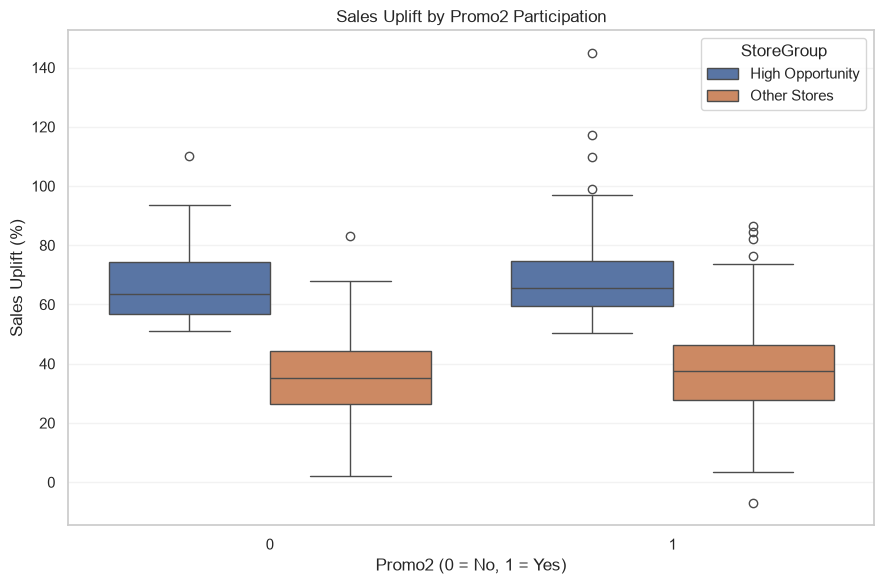

In [179]:
# Promo2 analysis

promo2_analysis = (
    store_analysis.groupby(
        ['StoreGroup', 'Promo2'],
        observed=True
    )
    .agg(
        NumberOfStores=('Store', 'nunique'),
        MedianSalesUplift=('SalesUpliftPct', 'median'),
        MedianCustomerUplift=('CustomerUpliftPct', 'median'),
        AverageOpportunityScore=('OpportunityScore', 'mean')
    )
    .reset_index()
)

print("\nPromo2 comparison (0 = no Promo2, 1 = Promo2):")
print(promo2_analysis.round(2).to_string(index=False))

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=store_analysis,
    x='Promo2',
    y='SalesUpliftPct',
    hue='StoreGroup'
)

plt.title('Sales Uplift by Promo2 Participation')
plt.xlabel('Promo2 (0 = No, 1 = Yes)')
plt.ylabel('Sales Uplift (%)')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


> ❓ **Research Question :** *Could the promos be deployed in more effective ways?*
## 🔍 Key Findings

- **Promo2 stores show slightly higher sales uplift:** Among high-opportunity stores, Promo2 stores record a median sales uplift of **65.57%**, compared with 63.62% for stores without Promo2.
- **Customer uplift remains similar:** Median customer uplift is nearly identical across high-opportunity stores with and without Promo2 (40.48% vs. 40.58%). This suggests that the difference in sales uplift is not accompanied by a higher median customer uplift.
- **High-opportunity stores outperform other stores:** Both Promo2 groups demonstrate substantially higher median sales and customer uplift than their corresponding other-store groups.
- **Promo2 alone does not guarantee better results:** The differences are relatively small, indicating that store-specific characteristics and campaign execution may also influence promotional performance.

## 💼 Business Recommendations: More Effective Promotion Deployment

- **Prioritise high-opportunity stores:** Focus initial campaigns on selected stores with strong sales uplift, regardless of Promo2 status.
- **Optimise existing Promo2 campaigns:** Review campaign timing, participating products, discount levels, and promotional intervals to identify opportunities for improvement.
- **Test targeted offers:** Experiment with product bundles, complementary-product discounts, and different offer levels to increase basket value while protecting margins.
- **Use customer response to refine campaigns:** Since median customer uplift is similar across the two high-opportunity Promo2 groups, test strategies designed to increase both store traffic and spending per visit.
- **Measure incremental profitability:** Compare sales, customer traffic, average basket value, discount costs, and gross profit against comparable control stores before expanding campaigns.

> **Recommendation:** Use Promo2 status as a supporting factor rather than the sole basis for promotional decisions. Prioritise high-opportunity stores and validate campaign effectiveness through controlled testing before scaling investment.


Competition distance comparison:
      StoreGroup CompetitionBand  NumberOfStores  MedianSalesUplift  MedianCustomerUplift
High Opportunity     Within 1 km              63              63.12                 39.08
High Opportunity          1–5 km              63              61.99                 38.37
High Opportunity         5–10 km              18              65.34                 42.45
High Opportunity      Over 10 km              44              73.45                 47.91
    Other Stores     Within 1 km             267              35.68                 20.42
    Other Stores          1–5 km             373              37.35                 20.89
    Other Stores         5–10 km             144              33.04                 16.86
    Other Stores      Over 10 km             143              36.47                 20.64


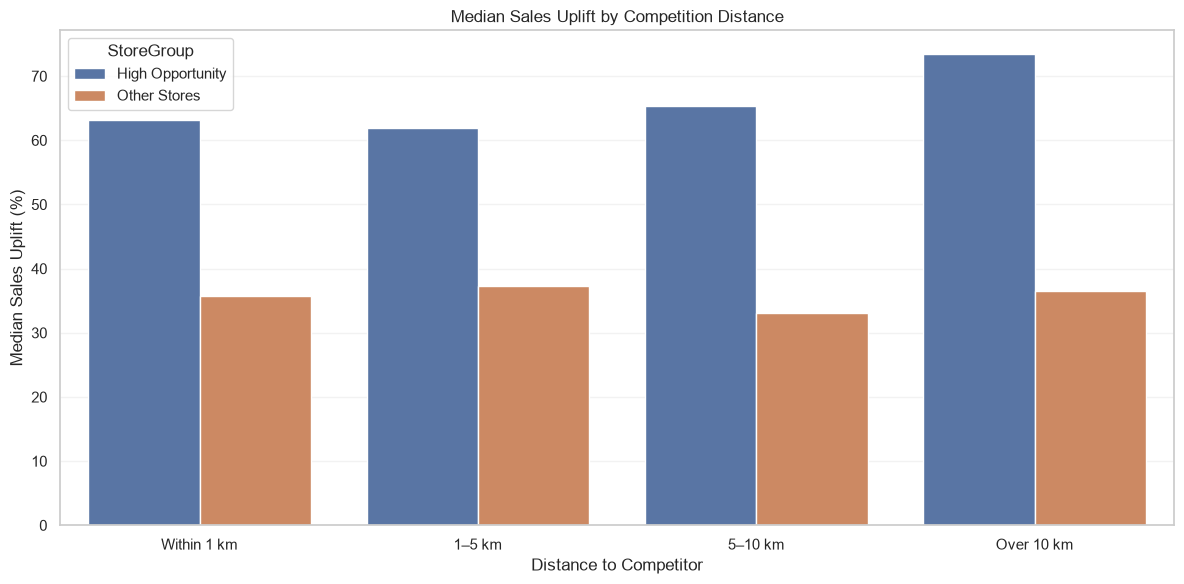

In [180]:
# Competition distance analysis

# Create distance categories; missing values remain missing
store_analysis['CompetitionBand'] = pd.cut(
    store_analysis['CompetitionDistance'],
    bins=[-np.inf, 1000, 5000, 10000, np.inf],
    labels=[
        'Within 1 km',
        '1–5 km',
        '5–10 km',
        'Over 10 km'
    ]
)

competition_analysis = (
    store_analysis.dropna(subset=['CompetitionBand'])
    .groupby(
        ['StoreGroup', 'CompetitionBand'],
        observed=True
    )
    .agg(
        NumberOfStores=('Store', 'nunique'),
        MedianSalesUplift=('SalesUpliftPct', 'median'),
        MedianCustomerUplift=('CustomerUpliftPct', 'median')
    )
    .reset_index()
)

print("\nCompetition distance comparison:")
print(competition_analysis.round(2).to_string(index=False))

plt.figure(figsize=(12, 6))

sns.barplot(
    data=competition_analysis,
    x='CompetitionBand',
    y='MedianSalesUplift',
    hue='StoreGroup'
)

plt.title('Median Sales Uplift by Competition Distance')
plt.xlabel('Distance to Competitor')
plt.ylabel('Median Sales Uplift (%)')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


> ❓ **Research Question :** *Could the promos be deployed in more effective ways?*
## 🔍 Key Findings

- **Stores over 10 km from competitors show the strongest uplift:** High-opportunity stores in this band achieve a median sales uplift of **73.45%** and customer uplift of **47.91%**.
- **Promotional potential exists across all distance bands:** High-opportunity stores outperform other stores in both median sales uplift and customer uplift, regardless of competitor proximity.
- **Nearby competitors do not eliminate promotional opportunities:** High-opportunity stores within 1 km of a competitor still achieve a median sales uplift of **63.12%**.
- **Competition distance alone is not a reliable selection criterion:** Uplift varies across distance bands, suggesting that other factors, such as store characteristics, customer behaviour, and campaign design, may also influence performance.

## 💼 Business Recommendations: More Effective Promotion Deployment

- **Prioritise stores over 10 km from competitors:** Test targeted campaigns in these high-opportunity stores, as they show the strongest observed sales and customer uplift.
- **Maintain targeted promotions near competitors:** Use differentiated offers, product bundles, and loyalty incentives to help nearby stores compete effectively.
- **Customise campaigns by location:** Test promotion types and discount levels across competition-distance bands rather than applying a uniform strategy.
- **Validate with controlled pilots:** Compare promotional and control stores within similar distance bands to assess incremental impact.
- **Measure profitability, not just uplift:** Evaluate incremental sales, customer traffic, discount costs, and profit margins before scaling campaigns.

> **Recommendation:** Use competition distance to refine promotional targeting, not as the sole decision factor. Prioritise high-opportunity stores with promising uplift and validate results through controlled testing before wider deployment.


Promotion performance by weekday:
 DayOfWeek  Promo  AverageSales  AverageCustomers  StoreDayRecords
         1      0       6222.52            742.78            60317
         1      1       9772.78            943.42            77243
         2      0       5716.24            687.53            66843
         2      1       8277.20            841.46            77118
         3      0       5617.04            672.55            65679
         3      1       7685.08            799.20            76257
         4      0       5749.84            688.75            60521
         4      1       7598.07            810.13            74123
         5      0       6344.03            735.19            66485
         5      1       7744.07            824.69            72155
         6      0       5874.84            660.18           144058
         7      0       8224.72           1441.53             3593

Promotion performance by month:
 Month  Promo  AverageSales  AverageCustomers  StoreDayRecord

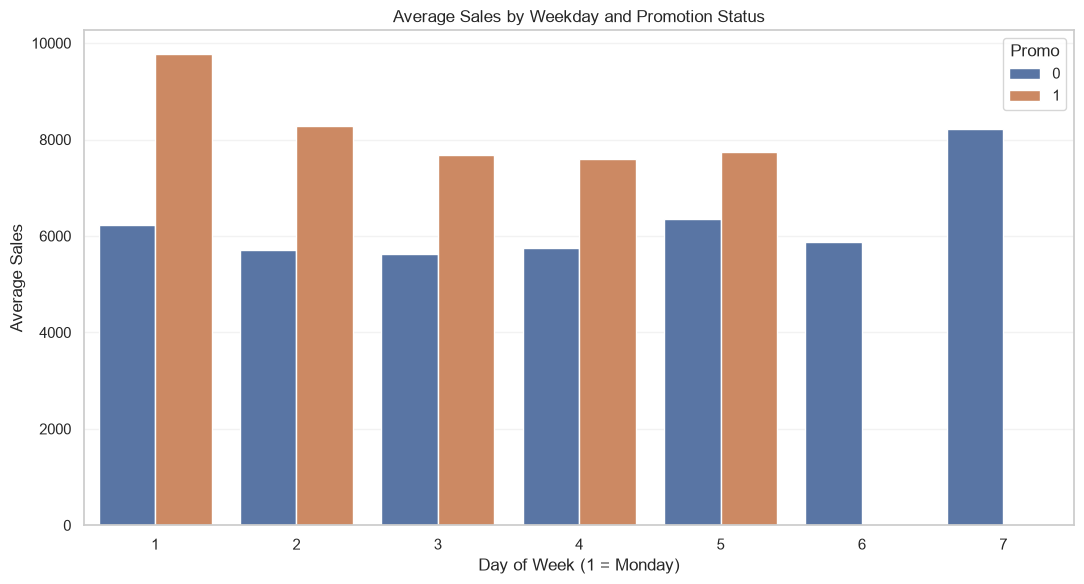

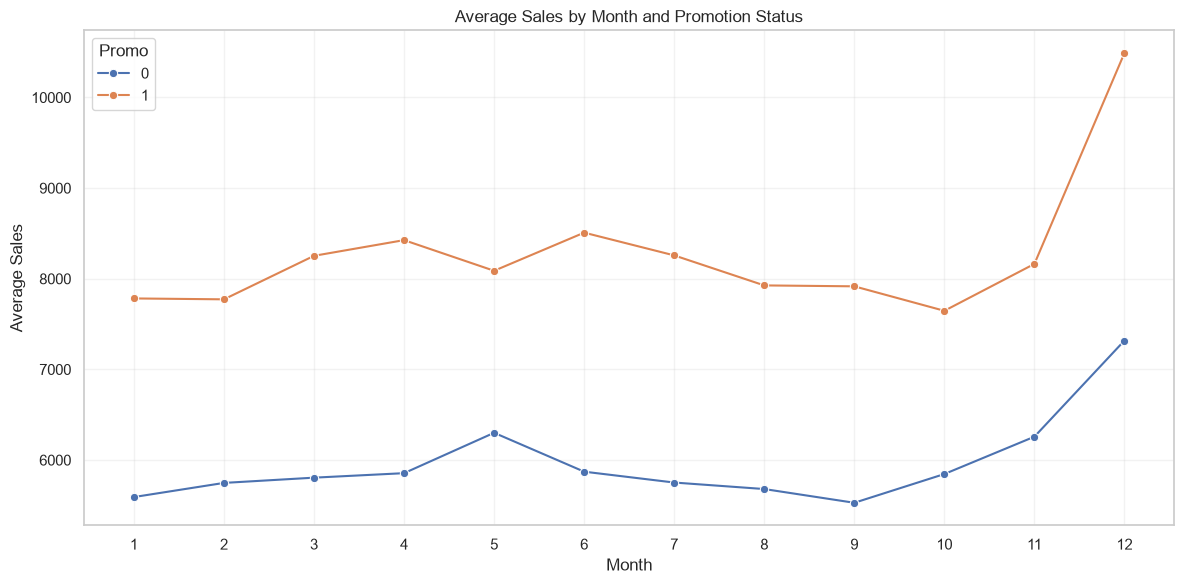

In [181]:

# Promotion performance by weekday and month

open_df = train_df.loc[train_df['Open'] == 1].copy()

# Ensure Date is datetime
open_df['Date'] = pd.to_datetime(open_df['Date'])

# Extract calendar features if not already present
if 'Month' not in open_df.columns:
    open_df['Month'] = open_df['Date'].dt.month

if 'DayOfWeek' not in open_df.columns:
    open_df['DayOfWeek'] = open_df['Date'].dt.dayofweek + 1

# Weekday comparison
weekday_analysis = (
    open_df.groupby(['DayOfWeek', 'Promo'])
    .agg(
        AverageSales=('Sales', 'mean'),
        AverageCustomers=('Customers', 'mean'),
        StoreDayRecords=('Sales', 'size')
    )
    .reset_index()
)

print("\nPromotion performance by weekday:")
print(weekday_analysis.round(2).to_string(index=False))

# Monthly comparison
monthly_analysis = (
    open_df.groupby(['Month', 'Promo'])
    .agg(
        AverageSales=('Sales', 'mean'),
        AverageCustomers=('Customers', 'mean'),
        StoreDayRecords=('Sales', 'size')
    )
    .reset_index()
)

print("\nPromotion performance by month:")
print(monthly_analysis.round(2).to_string(index=False))

# Visualize average sales by weekday and promotion status
plt.figure(figsize=(11, 6))

sns.barplot(
    data=weekday_analysis,
    x='DayOfWeek',
    y='AverageSales',
    hue='Promo'
)

plt.title('Average Sales by Weekday and Promotion Status')
plt.xlabel('Day of Week (1 = Monday)')
plt.ylabel('Average Sales')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

# Visualize average sales by month and promotion status
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_analysis,
    x='Month',
    y='AverageSales',
    hue='Promo',
    marker='o'
)

plt.title('Average Sales by Month and Promotion Status')
plt.xlabel('Month')
plt.ylabel('Average Sales')
plt.xticks(range(1, 13))
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


> ❓ **Research Question :** *Could the promos be deployed in more effective ways?*
## 🔍 Key Findings 

- **Monday delivers the strongest promotional performance:** Average sales increase from 6,222.52 without promotions to **9,772.78 with promotions**, accompanied by higher average customer traffic (943.42 vs. 742.78).
- **Promotions are associated with higher sales and customer traffic across weekdays:** From Monday to Friday, average sales and average customers are higher on promotional days than on non-promotional days. Saturday and Sunday have no promotional records in the supplied data.
- **December records the highest average promotional sales:** Average sales reach **10,490.79**, with average customer traffic of 998.24, suggesting a strong seasonal opportunity.
- **Promotional performance varies by month:** June records average promotional sales of 8,508.68, while April reaches 8,426.03. October has the lowest average promotional sales among the months shown (7,646.40).
- **Customer traffic generally increases during promotional periods:** Across the reported weekday and monthly comparisons, promotional records show higher average customer counts. However, differences in store mix, holidays, and trading conditions may contribute to these patterns.

## 💼 Business Recommendations: More Effective Promotion Deployment

- **Prioritise Monday campaigns:** Test targeted promotions on Mondays, when the supplied data shows the strongest average promotional sales and customer traffic.
- **Plan seasonal campaigns:** Prepare December promotions early and test complementary offers around high-demand periods to capture seasonal spending.
- **Optimise weaker-performing months:** Review October campaigns and test targeted offers, product bundles, or adjusted discount levels to improve sales response.
- **Customise promotions by weekday:** Compare campaign types and discount levels across Monday–Friday to identify the most effective combinations for each trading day.
- **Use controlled experiments:** Compare promotional stores with similar control stores operating under comparable conditions to estimate the incremental impact of campaigns.
- **Monitor profitability:** Evaluate incremental sales, customer traffic, basket value, discount costs, and gross profit before increasing promotional investment.

> **Recommendation:** Begin by testing Monday promotions and preparing targeted December campaigns, then optimise other months using store-level performance data. Validate results through controlled pilots before scaling.



In [182]:
# Separate open and closed store-day records
opening_summary = (
    train_df.groupby('Open')
    .agg(
        StoreDayRecords=('Store', 'size'),
        AverageCustomers=('Customers', 'mean'),
        MedianCustomers=('Customers', 'median'),
        AverageSales=('Sales', 'mean'),
        TotalCustomers=('Customers', 'sum'),
        TotalSales=('Sales', 'sum')
    )
    .reset_index()
)

opening_summary['StoreStatus'] = opening_summary['Open'].map({
    0: 'Closed',
    1: 'Open'
})

print(opening_summary.round(2).to_string(index=False))

 Open  StoreDayRecords  AverageCustomers  MedianCustomers  AverageSales  TotalCustomers  TotalSales StoreStatus
    0           172817              0.00              0.0          0.00               0           0      Closed
    1           844392            762.73            676.0       6955.51       644041755  5873180623        Open


> ❓ **Research Question :** *Trends of customer behavior during store open and closing times ?*
## 🔍 Store Opening Status and Sales Performance

- **Most store-day records are open:** Stores were open for 844,392 records and closed for 172,817 records, indicating that approximately **83.0%** of the records represent open stores.
- **Sales occur during open periods:** Open stores recorded average sales of **6,955.51** and average customer traffic of **762.73**. Closed stores recorded zero sales and zero customers.
- **Closed-day records are consistent with store operations:** The absence of sales and customers on closed days suggests that these records reflect operating status rather than missing sales activity.
- **Opening status is essential for forecasting:** Store operating status should be considered when predicting sales because closed stores have no recorded sales in this dataset.

## 💼 Business Recommendations

- **Focus promotions on open trading days:** Schedule promotional campaigns only when stores are operating, ensuring that campaign performance is evaluated against relevant trading periods.
- **Improve sales forecasting:** Incorporate the `Open` indicator into forecasting models so that closed days can be handled appropriately.
- **Compare like-for-like periods:** Evaluate promotional performance using comparable open store-days, accounting for weekdays, holidays, and seasonal differences.

In [183]:
# Copy the training data
df = train_df.copy()

df['Date'] = pd.to_datetime(df['Date'])

# Weekday mapping: 1 = Monday, 7 = Sunday
weekday_names = {
    1: 'Monday',
    2: 'Tuesday',
    3: 'Wednesday',
    4: 'Thursday',
    5: 'Friday',
    6: 'Saturday',
    7: 'Sunday'
}

# Checking store operating status for each weekday

store_weekday_status = (
    df.groupby(['Store', 'DayOfWeek'])
    .agg(
        TotalDays=('Open', 'size'),
        OpenDays=('Open', 'sum'),
        MinimumOpenStatus=('Open', 'min')
    )
    .reset_index()
)

# Count how many distinct weekdays each store has records for
weekday_coverage = (
    store_weekday_status.groupby('Store')['DayOfWeek']
    .nunique()
)

# A store must:
# 1. Have records for all 7 weekdays
# 2. Have Open = 1 on every recorded day

always_open_stores = store_weekday_status.groupby('Store').agg(
    WeekdaysCovered=('DayOfWeek', 'nunique'),
    AllDaysOpen=('MinimumOpenStatus', 'min')
)

always_open_stores = always_open_stores[
    (always_open_stores['WeekdaysCovered'] == 7) &
    (always_open_stores['AllDaysOpen'] == 1)
]

always_open_store_ids = always_open_stores.index.tolist()

print("Number of stores open on all seven weekdays:",
      len(always_open_store_ids))

print("\nStore IDs:")
print(always_open_store_ids)

Number of stores open on all seven weekdays: 10

Store IDs:
[85, 262, 335, 423, 494, 562, 682, 733, 769, 1097]


> ❓ **Research Question :** *Which stores are opened on all weekdays?*
### Stores Operating All Seven Days

A total of **10 stores** were identified as operating throughout all seven days of the week.

**Store IDs:**

`85, 262, 335, 423, 494, 562, 682, 733, 769, 1097`

These stores were analysed separately to compare weekday and weekend sales performance without the influence of stores that remain closed on Sundays or other days.

**Analytical Note:** This group represents a small subset of the 1,115 stores. Its performance should therefore be interpreted separately and not generalised to all stores.

In [184]:

# Creating weekday/weekend categories

df['DayCategory'] = np.where(
    df['DayOfWeek'].isin([6, 7]),
    'Weekend',
    'Weekday'
)

# Consider only open stores
open_df = df[df['Open'] == 1].copy()

# Separate stores that are open all seven days
open_df['StoreGroup'] = np.where(
    open_df['Store'].isin(always_open_store_ids),
    'Open All 7 Days',
    'Other Stores'
)

# Calculating sales and customer performance

weekend_analysis = (
    open_df.groupby(['StoreGroup', 'DayCategory'])
    .agg(
        NumberOfStores=('Store', 'nunique'),
        AverageSales=('Sales', 'mean'),
        MedianSales=('Sales', 'median'),
        AverageCustomers=('Customers', 'mean'),
        MedianCustomers=('Customers', 'median'),
        TotalSales=('Sales', 'sum'),
        TotalCustomers=('Customers', 'sum'),
        StoreDayRecords=('Sales', 'size')
    )
    .reset_index()
)

print("\nWEEKDAY VS WEEKEND PERFORMANCE")
print(weekend_analysis.round(2).to_string(index=False))


WEEKDAY VS WEEKEND PERFORMANCE
     StoreGroup DayCategory  NumberOfStores  AverageSales  MedianSales  AverageCustomers  MedianCustomers  TotalSales  TotalCustomers  StoreDayRecords
Open All 7 Days     Weekday              10      12772.08      11801.5           2408.83           2539.0    86083827        16235521             6740
Open All 7 Days     Weekend              10      11627.11      10223.0           2215.32           2058.0    31160663         5937048             2680
   Other Stores     Weekday            1105       7117.71       6532.0            764.52            691.0  4911227628       527522954           690001
   Other Stores     Weekend            1105       5826.74       5392.0            650.79            570.0   844708505        94346232           144971


> ❓ **Research Question :** *How does that affect their sales on weekends?*
## 🔍 Key Findings

- **Weekdays generate higher average sales:** Stores open all seven days record average weekday sales of **12,772.08**, compared with 11,627.11 on weekends. Other stores show a similar pattern, with 7,117.71 on weekdays versus 5,826.74 on weekends.
- **Customer traffic is higher on weekdays:** Average customer counts are higher during weekdays across both store groups. For stores open all seven days, weekday traffic averages 2,408.83 compared with 2,215.32 on weekends.
- **The weekday advantage is more pronounced among other stores:** Average sales are approximately **22.2% higher** on weekdays, while average customer traffic is around **17.5% higher**.
- **Seven-day stores maintain stronger performance:** Stores operating throughout the week record substantially higher average sales and customer traffic than other stores on both weekdays and weekends.

## 💼 Business Recommendations: More Effective Promotional Deployment

- **Prioritise weekday campaigns:** Focus promotional activities on weekdays, when both store groups demonstrate higher average sales and customer traffic.
- **Use targeted weekend offers:** Introduce weekend-specific discounts, product bundles, and family-oriented offers to improve comparatively lower weekend performance.
- **Customise strategies by store group:** Develop separate promotional plans for stores operating all seven days and other stores, considering their different sales and customer traffic patterns.
- **Optimise staffing and inventory:** Align staffing levels and stock availability with higher weekday demand while using targeted campaigns to improve weekend utilisation.
- **Measure promotional effectiveness:** Compare weekday and weekend campaigns using average sales, customer traffic, basket value, and incremental profit.

> **Recommendation:** Prioritise weekdays for revenue-focused promotions while using targeted weekend campaigns to improve customer traffic and sales. Evaluate both strategies separately to identify the most profitable promotional opportunities.

In [185]:
logger.info("=" * 70)
logger.info("Starting store operating and closure analysis")
logger.info("=" * 70)

try:
    operating_summary = (
        train_df.groupby("Store")
        .agg(
            TotalDays=("Open", "size"),
            OpenDays=("Open", "sum"),
            AverageSales=("Sales", "mean"),
            AverageCustomers=("Customers", "mean")
        )
    )

    operating_summary["ClosedDays"] = (
        operating_summary["TotalDays"] -
        operating_summary["OpenDays"]
    )

    logger.info(
        f"Store operating summary:\n"
        f"{operating_summary.describe().round(2).to_string()}"
    )

    closure_summary = (
        train_df.groupby("Open")
        .agg(
            Records=("Store", "size"),
            AverageSales=("Sales", "mean"),
            AverageCustomers=("Customers", "mean")
        )
        .round(2)
    )

    logger.info(
        f"Open and closed day summary:\n{closure_summary.to_string()}"
    )

    all_weekdays_open = (
        train_df.groupby("Store")["DayOfWeek"]
        .apply(lambda x: set(x.unique()) == set(range(1, 8)))
    )

    logger.info(
        f"Stores with records across all seven weekdays: "
        f"{all_weekdays_open.sum()}"
    )

    logger.info("Store operating and closure analysis completed successfully")

except Exception:
    logger.exception("Error during store operating and closure analysis")


2026-11-10 11:23:27 | INFO | ======================================================================
2026-11-10 11:23:27 | INFO | Starting store operating and closure analysis
2026-11-10 11:23:27 | INFO | ======================================================================
2026-11-10 11:23:27 | INFO | Store operating summary:
       TotalDays  OpenDays  AverageSales  AverageCustomers  ClosedDays
count    1115.00   1115.00       1115.00           1115.00     1115.00
mean      912.30    757.30       5763.32            629.50      154.99
std        67.73     63.86       2046.45            318.59       24.90
min       758.00    592.00       2244.50            199.13        0.00
25%       942.00    776.00       4412.42            449.19      158.00
50%       942.00    779.00       5459.19            562.70      161.00
75%       942.00    782.00       6633.87            718.18      163.00
max       942.00    942.00      20718.52           3403.46      311.00
2026-11-10 11:23:28 | INFO | Ope

In [186]:
# Select only open stores
assortment_df = train_df[train_df['Open'] == 1].copy()

# Map assortment codes to descriptive names
assortment_mapping = {
    'a': 'Basic',
    'b': 'Extra',
    'c': 'Extended'
}

assortment_df['AssortmentType'] = (
    assortment_df['Assortment'].map(assortment_mapping)
)

# Check the distribution
print(assortment_df['AssortmentType'].value_counts())

# Calculate sales per customer
assortment_df['SalesPerCustomer'] = (
    assortment_df['Sales'] /
    assortment_df['Customers'].replace(0, np.nan)
)

# Group by assortment type
assortment_summary = (
    assortment_df.groupby('AssortmentType')
    .agg(
        NumberOfStores=('Store', 'nunique'),
        AverageSales=('Sales', 'mean'),
        MedianSales=('Sales', 'median'),
        AverageCustomers=('Customers', 'mean'),
        MedianCustomers=('Customers', 'median'),
        AverageSalesPerCustomer=('SalesPerCustomer', 'mean'),
        TotalSales=('Sales', 'sum')
    )
    .round(2)
)

print(assortment_summary)

AssortmentType
Basic       444909
Extended    391271
Extra         8212
Name: count, dtype: int64
                NumberOfStores  AverageSales  MedianSales  AverageCustomers  \
AssortmentType                                                                
Basic                      593       6621.02       6082.0            747.94   
Extended                   513       7300.53       6675.0            752.17   
Extra                        9       8639.35       8081.0           2066.80   

                MedianCustomers  AverageSalesPerCustomer  TotalSales  
AssortmentType                                                        
Basic                     673.0                     9.13  2945750070  
Extended                  672.0                    10.02  2856484241  
Extra                    1894.0                     4.16    70946312  


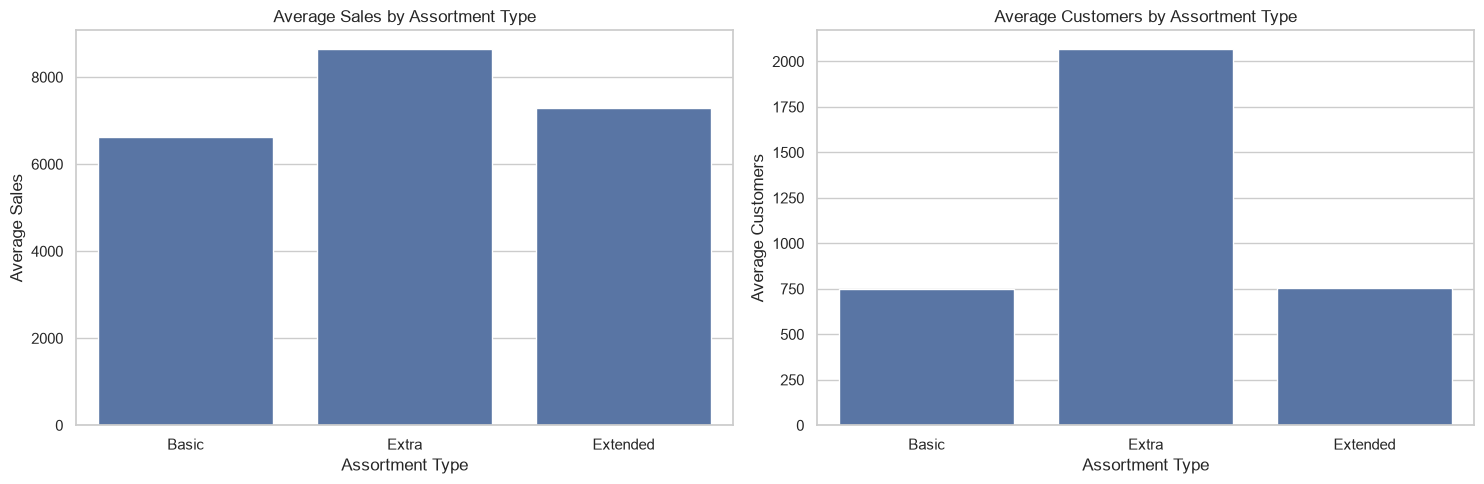

In [187]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Average sales by assortment
sns.barplot(
    data=assortment_df,
    x='AssortmentType',
    y='Sales',
    order=['Basic', 'Extra', 'Extended'],
    estimator='mean',
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title('Average Sales by Assortment Type')
axes[0].set_xlabel('Assortment Type')
axes[0].set_ylabel('Average Sales')

# Average customers by assortment
sns.barplot(
    data=assortment_df,
    x='AssortmentType',
    y='Customers',
    order=['Basic', 'Extra', 'Extended'],
    estimator='mean',
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title('Average Customers by Assortment Type')
axes[1].set_xlabel('Assortment Type')
axes[1].set_ylabel('Average Customers')

plt.tight_layout()
plt.show()

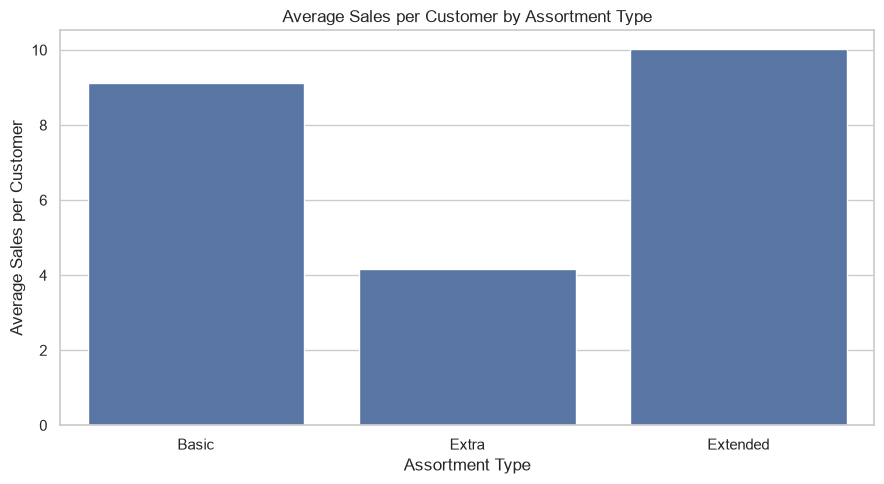

In [188]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=assortment_df,
    x='AssortmentType',
    y='SalesPerCustomer',
    order=['Basic', 'Extra', 'Extended'],
    estimator='mean',
    errorbar=None
)

plt.title('Average Sales per Customer by Assortment Type')
plt.xlabel('Assortment Type')
plt.ylabel('Average Sales per Customer')

plt.tight_layout()
plt.show()

> ❓ **Research Question:** *How does store assortment type (Basic, Extra, and Extended) influence sales performance and customer purchasing behaviour across stores?*

## 🔍 Impact of Assortment Type on Sales Performance

- **Extra assortment generates the highest average sales:** Stores with Extra assortment record approximately 8,600 in average sales, outperforming Extended and Basic assortment stores.
- **Extra assortment attracts significantly higher customer traffic:** Average customer count is approximately 2,060, considerably higher than Basic and Extended assortment stores (around 750 each).
- **Extended assortment leads in average sales per customer:** Customers in Extended assortment stores generate approximately 10.0 in sales per customer, followed by Basic at 9.1 and Extra at 4.1.
- **Higher customer traffic does not necessarily mean higher spending per customer:** Although Extra assortment stores generate the highest overall sales, their average sales per customer are the lowest.
- **Basic assortment shows moderate performance:** It records lower average sales and customer traffic than Extra assortment, but higher sales per customer than Extra assortment.

## 💼 Business Recommendations: Improving Sales Through Assortment Strategies

- **Optimise Extra assortment:** Focus on converting its high customer traffic into higher-value purchases through product bundles, cross-selling, and complementary-product recommendations.
- **Strengthen Extended assortment:** Leverage its higher sales per customer by promoting premium products and complementary items to increase overall revenue.
- **Improve Basic assortment performance:** Identify high-demand products and introduce targeted offers to increase customer visits and basket value.
- **Customise promotional strategies:** Avoid applying identical promotions across all assortment types. Design offers according to customer traffic and spending behaviour.
- **Monitor key performance indicators:** Track average sales, customer traffic, average sales per customer, and gross profit to evaluate assortment-level performance.

> **Recommendation:** Extra assortment offers the strongest opportunity for sales volume due to its high customer traffic, while Extended assortment demonstrates stronger spending per customer. A differentiated strategy should focus on increasing basket value in Extra stores and sustaining customer spending in Extended stores.

In [189]:
# Create store-level summary
competition_analysis = (
    open_df.groupby('Store')
    .agg(
        AverageSales=('Sales', 'mean'),
        AverageCustomers=('Customers', 'mean'),
        CompetitionDistance=('CompetitionDistance', 'first'),
        StoreType=('StoreType', 'first'),
        Assortment=('Assortment', 'first')
    )
    .reset_index()
)

print(competition_analysis.head())

# Pearson correlation: linear relationship
pearson_corr = competition_analysis[
    ['CompetitionDistance', 'AverageSales']
].corr(method='pearson').iloc[0, 1]

# Spearman correlation: monotonic relationship
spearman_corr = competition_analysis[
    ['CompetitionDistance', 'AverageSales']
].corr(method='spearman').iloc[0, 1]

print("Pearson Correlation:", round(pearson_corr, 3))
print("Spearman Correlation:", round(spearman_corr, 3))

   Store  AverageSales  AverageCustomers  CompetitionDistance StoreType  \
0      1   4759.096031        564.049936               1270.0         c   
1      2   4953.900510        583.998724                570.0         a   
2      3   6942.568678        750.077022              14130.0         a   
3      4   9638.401786       1321.752551                620.0         c   
4      5   4676.274711        537.340180              16107.5         a   

  Assortment  
0          a  
1          a  
2          a  
3          c  
4          a  
Pearson Correlation: -0.045
Spearman Correlation: -0.027


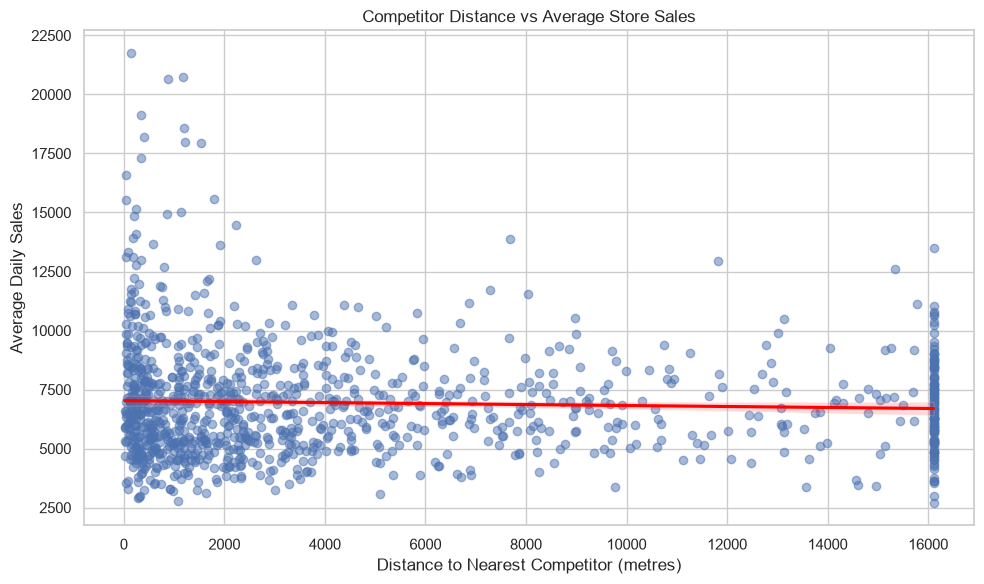

In [190]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=competition_analysis,
    x='CompetitionDistance',
    y='AverageSales',
    scatter_kws={'alpha': 0.5},
    line_kws={'color': 'red'}
)

plt.title('Competitor Distance vs Average Store Sales')
plt.xlabel('Distance to Nearest Competitor (metres)')
plt.ylabel('Average Daily Sales')

plt.tight_layout()
plt.show()

## 🔍 Key Findings

- **Very weak negative relationship:** The trend line indicates a slight decline in average sales as the distance to the nearest competitor increases. This suggests that competitor distance has little linear association with store sales.
- **Higher sales variation near competitors:** Stores located closer to competitors show a wider range of sales performance, including several high-performing stores.
- **Sales remain relatively distributed across distance ranges:** Stores located farther from competitors also achieve strong sales, indicating that greater competitor distance does not necessarily guarantee higher revenue.
- **High concentration of stores near competitors:** Most observations are concentrated within approximately 2,000 metres, while relatively few stores operate at greater distances.

## 💼 Business Recommendations: Improving Sales Performance

- **Prioritise store-level analysis:** Avoid using competitor distance as the sole factor for sales or promotional decisions. Consider customer traffic, assortment, store type, and promotional performance together.
- **Strengthen nearby stores:** Use differentiated pricing, loyalty offers, and targeted promotions to help stores compete in areas with nearby competitors.
- **Leverage distant-store opportunities:** Evaluate stores with limited nearby competition for opportunities to expand product offerings and improve customer retention.
- **Investigate high-performing locations:** Examine the characteristics of stores achieving high sales despite intense competition to identify successful business practices.
- **Use additional performance indicators:** Combine competitor distance with customer density, local demand, purchasing behaviour, and store accessibility for more reliable business decisions.

> **Conclusion:** Competitor distance has only a weak apparent relationship with average store sales. Therefore, promotional and operational strategies should be based on a combination of store-level and market-level factors rather than competitor proximity alone.

                  NumberOfStores  AverageSales  AverageCustomers  MedianSales
CompetitionGroup                                                             
0–500 m                      220       7581.49            960.33      7016.61
500–1000 m                   110       6642.81            815.64      5910.00
1000–3000 m                  299       6840.71            737.10      6391.01
3000–5000 m                  137       6720.48            696.97      6577.14
Above 5000 m                 349       6782.03            643.00      6629.75


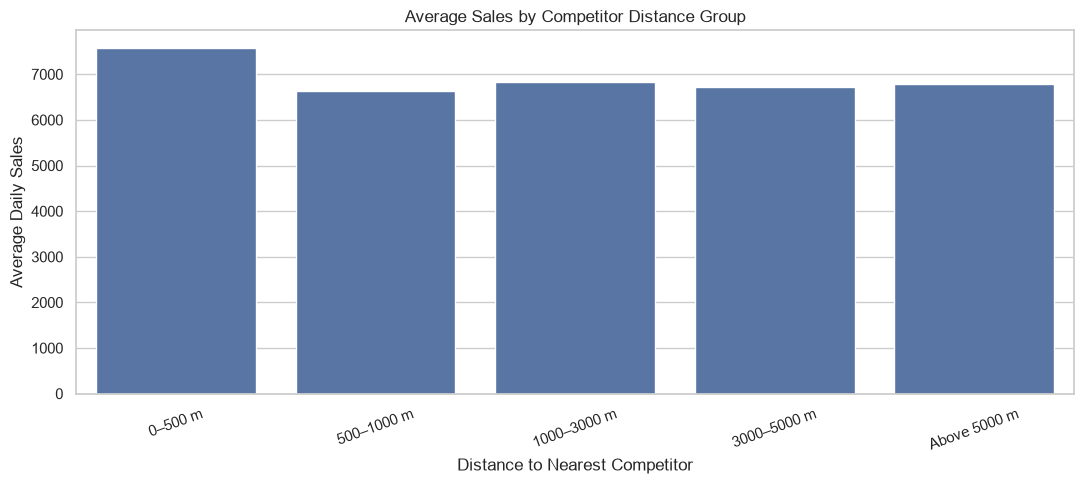

In [191]:
# Create distance categories
bins = [0, 500, 1000, 3000, 5000, float('inf')]

labels = [
    '0–500 m',
    '500–1000 m',
    '1000–3000 m',
    '3000–5000 m',
    'Above 5000 m'
]

competition_analysis['CompetitionGroup'] = pd.cut(
    competition_analysis['CompetitionDistance'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate sales and customer averages
distance_summary = (
    competition_analysis.groupby(
        'CompetitionGroup',
        observed=False
    )
    .agg(
        NumberOfStores=('Store', 'nunique'),
        AverageSales=('AverageSales', 'mean'),
        AverageCustomers=('AverageCustomers', 'mean'),
        MedianSales=('AverageSales', 'median')
    )
    .round(2)
)

print(distance_summary)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=competition_analysis,
    x='CompetitionGroup',
    y='AverageSales',
    order=labels,
    estimator='mean',
    errorbar=None
)

plt.title('Average Sales by Competitor Distance Group')
plt.xlabel('Distance to Nearest Competitor')
plt.ylabel('Average Daily Sales')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [192]:
customer_corr = competition_analysis[
    ['CompetitionDistance', 'AverageCustomers']
].corr(method='spearman').iloc[0, 1]

print(
    "Spearman correlation between competitor distance "
    "and average customers:",
    round(customer_corr, 3)
)

Spearman correlation between competitor distance and average customers: -0.279


> ❓ **Research Question :** *How does the distance to the next competitor affect sales?*
## 🔍 Key Findings

- **Stores within 500 metres record the highest average sales:** These stores achieve average sales of **7,581.49** and median sales of **7,016.61**, indicating comparatively strong sales performance.
- **Sales decline with increasing competitor distance initially:** Average sales decrease from 7,581.49 in the 0–500 m group to 6,642.81 in the 500–1,000 m group.
- **Customer traffic decreases as competitor distance increases:** Average customers decline from **960.33** in the closest group to **643.00** among stores located more than 5,000 metres away.
- **Sales remain relatively stable beyond 500 metres:** Average sales across the remaining distance groups range from approximately 6,643 to 6,841, suggesting no consistent increase in sales with greater competitor distance.
- **Competitor proximity does not necessarily reduce sales:** Stores located close to competitors demonstrate the strongest average sales and customer traffic in this comparison.

## 💼 Business Recommendations: Improving Sales Performance

- **Strengthen stores in competitive areas:** Use loyalty programmes, targeted discounts, and differentiated product offerings to retain customers and maintain sales performance.
- **Investigate high-performing nearby stores:** Identify successful pricing, assortment, and promotional strategies that may explain their stronger performance.
- **Improve customer acquisition in distant locations:** Explore local marketing, loyalty incentives, and targeted campaigns to improve customer traffic in stores located farther from competitors.
- **Customise strategies by distance group:** Develop location-specific promotional plans instead of applying a uniform strategy across all stores.
- **Consider additional market factors:** Combine competitor distance with customer density, store type, assortment, accessibility, and local demand when evaluating store performance.

> **Conclusion:** Stores within 500 metres of competitors demonstrate the highest average sales and customer traffic. However, beyond this distance, sales remain relatively stable. Competitor proximity should therefore be considered alongside other store and market characteristics rather than treated as a direct indicator of sales performance.

> ❓**Research Question :** *What if the store and its competitors all happen to be in city centres, does the distance matter in that case?*

Competitor distance should be evaluated alongside customer density, local demand, competitor concentration, accessibility, and store characteristics.

For a more reliable analysis, stores should be compared within similar geographical settings, such as city centres, suburban areas, and rural locations.

> **Conclusion:** Even when stores and competitors are located in city centres, competitor distance can influence sales, but it may not be the dominant factor. High customer demand and commercial activity can allow nearby competitors to achieve strong sales simultaneously. Therefore, understanding the overall competitive environment is more important than considering distance in isolation

In [193]:
logger.info("=" * 70)
logger.info("Starting competitor impact analysis")
logger.info("=" * 70)

try:
    # Competitor distance summary
    distance_summary = (
        train_df.groupby("Store")
        .agg(
            CompetitionDistance=("CompetitionDistance", "first"),
            AverageSales=("Sales", "mean"),
            AverageCustomers=("Customers", "mean")
        )
    )

    logger.info(
        f"Competitor distance statistics:\n"
        f"{distance_summary['CompetitionDistance'].describe().round(2).to_string()}"
    )

    # Correlation analysis
    distance_correlation = distance_summary[
        ["CompetitionDistance", "AverageSales", "AverageCustomers"]
    ].corr()

    logger.info(
        f"Competitor distance correlation:\n"
        f"{distance_correlation.round(4).to_string()}"
    )

    # Competitor opening date analysis
    competitor_columns = [
        "CompetitionOpenSinceMonth",
        "CompetitionOpenSinceYear"
    ]

    competitor_stores = train_df[
        ["Store"] + competitor_columns
    ].drop_duplicates("Store")

    valid_competitors = competitor_stores[
        competitor_stores["CompetitionOpenSinceMonth"].between(1, 12) &
        competitor_stores["CompetitionOpenSinceYear"].between(1900, 2015)
    ]

    logger.info(
        f"Stores with valid competitor opening information: "
        f"{len(valid_competitors)}"
    )

    logger.info("Competitor impact analysis completed successfully")

except Exception:
    logger.exception("Error during competitor impact analysis")


2026-11-10 11:23:35 | INFO | ======================================================================
2026-11-10 11:23:35 | INFO | Starting competitor impact analysis
2026-11-10 11:23:35 | INFO | ======================================================================
2026-11-10 11:23:35 | INFO | Competitor distance statistics:
count     1115.00
mean      4635.27
std       5181.46
min         20.00
25%        720.00
50%       2325.00
75%       6875.00
max      16107.50
2026-11-10 11:23:35 | INFO | Competitor distance correlation:
                     CompetitionDistance  AverageSales  AverageCustomers
CompetitionDistance               1.0000       -0.0446           -0.2017
AverageSales                     -0.0446        1.0000            0.8380
AverageCustomers                 -0.2017        0.8380            1.0000
2026-11-10 11:23:35 | INFO | Stores with valid competitor opening information: 761
2026-11-10 11:23:35 | INFO | Competitor impact analysis completed successfully


In [194]:
# Keep one competitor record per store
competitor_df = train_df[
    ['Store', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear']
].drop_duplicates('Store').copy()

# Keep only valid competitor opening information
competitor_df = competitor_df[
    competitor_df['CompetitionOpenSinceMonth'].between(1, 12) &
    competitor_df['CompetitionOpenSinceYear'].between(1900, 2015)
].copy()

# Create approximate competitor opening date (first day of the month)
competitor_df['CompetitorOpenDate'] = pd.to_datetime(
    dict(
        year=competitor_df['CompetitionOpenSinceYear'],
        month=competitor_df['CompetitionOpenSinceMonth'],
        day=1
    ),
    errors='coerce'
)

# Ensure Date is datetime
train_df['Date'] = pd.to_datetime(train_df['Date'])

print("Stores with valid competitor opening information:",
      competitor_df['Store'].nunique())

print(competitor_df.head())

Stores with valid competitor opening information: 761
   Store  CompetitionOpenSinceMonth  CompetitionOpenSinceYear  \
0      1                        9.0                    2008.0   
1      2                       11.0                    2007.0   
2      3                       12.0                    2006.0   
3      4                        9.0                    2009.0   
4      5                        4.0                    2015.0   

  CompetitorOpenDate  
0         2008-09-01  
1         2007-11-01  
2         2006-12-01  
3         2009-09-01  
4         2015-04-01  


In [195]:
# Merge competitor opening dates with daily store data
event_df = train_df.merge(
    competitor_df[['Store', 'CompetitorOpenDate']],
    on='Store',
    how='inner'
)

# Calculate days relative to competitor opening
event_df['DaysFromOpening'] = (
    event_df['Date'] - event_df['CompetitorOpenDate']
).dt.days

# Keep events with a complete 90-day before/after window
event_df = event_df[
    event_df['CompetitorOpenDate'].between(
        train_df['Date'].min() + pd.Timedelta(days=90),
        train_df['Date'].max() - pd.Timedelta(days=90)
    )
]

# Consider only open store days
event_df = event_df[event_df['Open'] == 1].copy()

# Before and after periods
event_df['Period'] = np.where(
    event_df['DaysFromOpening'] < 0,
    'Before Competitor Opening',
    'After Competitor Opening'
)

print("Eligible stores:", event_df['Store'].nunique())
print("Eligible daily records:", len(event_df))

Eligible stores: 162
Eligible daily records: 123088


>**Research Question :** *How does the opening or reopening of new competitors affect stores?*
## 🏙️ Event-Based Analysis: Impact of Competitor Openings on Store Performance

### Objective
Evaluate whether the opening of a nearby competitor influences the sales performance of existing stores by comparing their performance before and after the competitor's opening date.

### Methodology

1. **Merge competitor opening dates:** Combine the daily store sales dataset with competitor opening-date information using the `Store` identifier.
2. **Calculate event timelines:** Calculate the number of days between each sales observation and the competitor's opening date.
3. **Select eligible stores:** Retain stores whose competitor opening dates fall within the dataset's date range, allowing a complete 90-day observation window before and after the event.
4. **Consider operational days:** Include only records where stores were open (`Open = 1`) to ensure meaningful sales comparisons.
5. **Classify observation periods:** Divide daily records into two categories:
   - **Before Competitor Opening:** Observations preceding the competitor's opening date.
   - **After Competitor Opening:** Observations on or following the competitor's opening date.

### Dataset Coverage

| Metric | Result |
|:--|--:|
| Eligible Stores | **162** |
| Eligible Daily Records | **123,088** |
| Pre-Opening Observation Window | 90 Days |
| Post-Opening Observation Window | 90 Days |
| Store Operating Status | Open Days Only |

### Analytical Significance

This approach enables a comparison of store sales and customer traffic around competitor-opening events. It provides a more informative perspective than static competitor-distance analysis because it examines changes associated with a specific competitive event.

**Next Step:** Compare average sales, median sales, and customer traffic before and after competitor openings to identify potential changes in store performance.

> **Important:** This comparison identifies associations, not necessarily causal effects. Seasonal trends, holidays, promotions, and other market conditions should be considered before attributing performance changes to competitor openings.

In [196]:
before_after_summary = (
    event_df.groupby('Period')
    .agg(
        AverageSales=('Sales', 'mean'),
        MedianSales=('Sales', 'median'),
        AverageCustomers=('Customers', 'mean'),
        MedianCustomers=('Customers', 'median'),
        StoreDays=('Sales', 'size'),
        Stores=('Store', 'nunique')
    )
    .round(2)
)

print(before_after_summary)

                           AverageSales  MedianSales  AverageCustomers  \
Period                                                                   
After Competitor Opening        7429.99       6648.5            807.25   
Before Competitor Opening       7103.15       6471.0            759.37   

                           MedianCustomers  StoreDays  Stores  
Period                                                         
After Competitor Opening             699.0      65154     162  
Before Competitor Opening            681.0      57934     162  


In [197]:
before = before_after_summary.loc['Before Competitor Opening']
after = before_after_summary.loc['After Competitor Opening']

comparison = pd.DataFrame({
    'Before': [
        before['AverageSales'],
        before['AverageCustomers']
    ],
    'After': [
        after['AverageSales'],
        after['AverageCustomers']
    ]
}, index=['Average Sales', 'Average Customers'])

comparison['Change (%)'] = (
    (comparison['After'] - comparison['Before']) /
    comparison['Before'] * 100
).round(2)

print(comparison)

                    Before    After  Change (%)
Average Sales      7103.15  7429.99        4.60
Average Customers   759.37   807.25        6.31


# 🏢 Competitor Opening Impact on Store Performance

## 🔍 Key Findings

- **Positive sales trend:** Average sales increased by 4.60% after competitor openings.
- **Higher customer traffic:** Average customer count increased by 6.31%.
- **Improved typical performance:** Median sales and customers also increased.
- **Growth opportunity:** Customer growth exceeded sales growth, creating an opportunity to increase average basket value through effective promotions.

## 🧑‍🏭 Business Recommendations

- **High-performing stores:** Focus on loyalty rewards, product bundles, and cross-selling to retain customers and increase basket value.
- **Low-performing stores:** Introduce targeted discounts on popular products and limited-period offers to recover sales.
- **Customer retention:** Use personalised offers and repeat-purchase incentives to strengthen customer loyalty.
- **Smart promotion timing:** Prioritise high-potential weekdays and seasonal periods based on historical sales trends.
- **Protect profit margins:** Prefer bundle offers and product-specific discounts over excessive store-wide price reductions.
- **Measure campaign performance:** Track sales uplift, customer traffic, average basket value, and incremental profit before expanding promotions.

## 🕎 Overall Conclusion

Stores demonstrated positive sales and customer growth after competitor openings. Rather than applying uniform discounts, the business should adopt a **store-level promotional strategy** that retains customers in strong-performing stores and supports sales recovery in weaker ones.

**Strategic Priority:** Convert increased customer traffic into higher-value purchases while protecting profitability through targeted, measurable promotional campaigns.

*Note: The observed growth does not establish that competitor openings caused the improvement. Seasonality, promotions, and differences in store-day records should be considered in further analysis.*

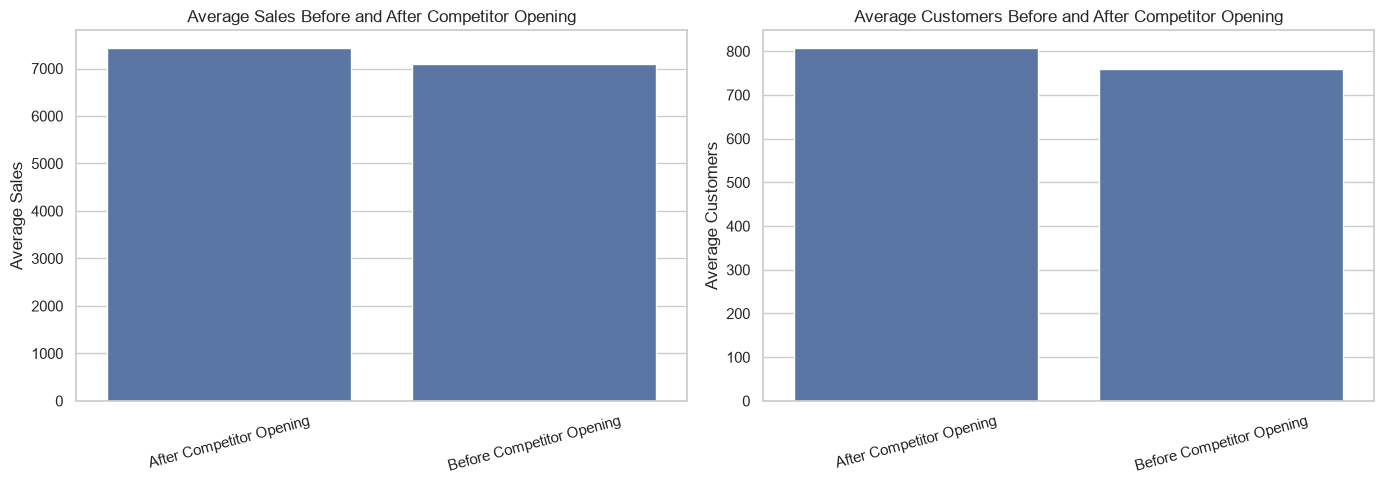

In [198]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=event_df,
    x='Period',
    y='Sales',
    estimator='mean',
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title('Average Sales Before and After Competitor Opening')
axes[0].set_xlabel('')
axes[0].set_ylabel('Average Sales')
axes[0].tick_params(axis='x', rotation=15)

sns.barplot(
    data=event_df,
    x='Period',
    y='Customers',
    estimator='mean',
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Average Customers Before and After Competitor Opening')
axes[1].set_xlabel('')
axes[1].set_ylabel('Average Customers')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

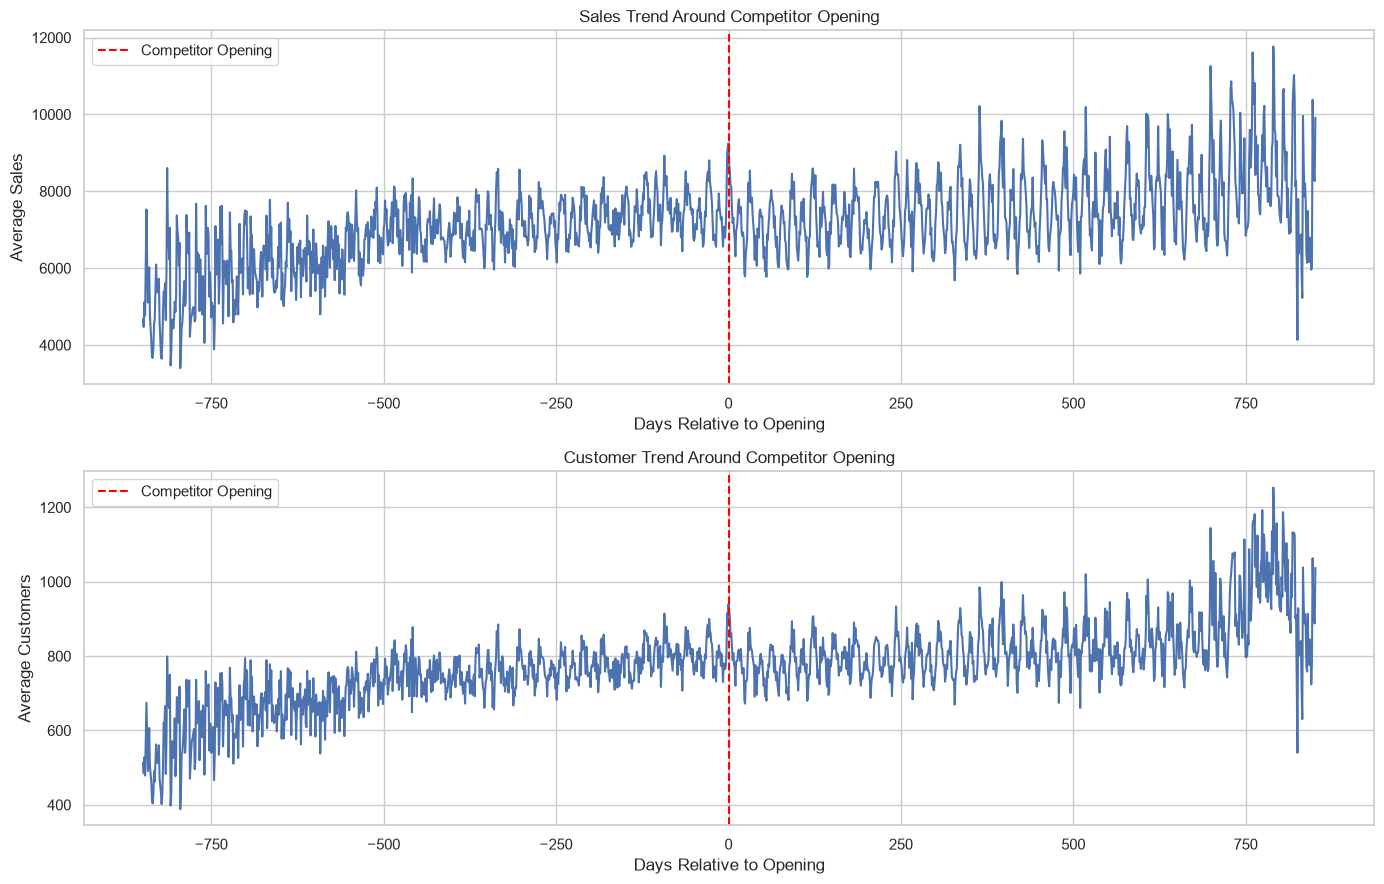

In [199]:
daily_trend = (
    event_df.groupby('DaysFromOpening')
    .agg(
        AverageSales=('Sales', 'mean'),
        AverageCustomers=('Customers', 'mean')
    )
    .reset_index()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

sns.lineplot(
    data=daily_trend,
    x='DaysFromOpening',
    y='AverageSales',
    ax=axes[0]
)
axes[0].axvline(0, color='red', linestyle='--',
                label='Competitor Opening')
axes[0].set_title('Sales Trend Around Competitor Opening')
axes[0].set_xlabel('Days Relative to Opening')
axes[0].set_ylabel('Average Sales')
axes[0].legend()

sns.lineplot(
    data=daily_trend,
    x='DaysFromOpening',
    y='AverageCustomers',
    ax=axes[1]
)
axes[1].axvline(0, color='red', linestyle='--',
                label='Competitor Opening')
axes[1].set_title('Customer Trend Around Competitor Opening')
axes[1].set_xlabel('Days Relative to Opening')
axes[1].set_ylabel('Average Customers')
axes[1].legend()

plt.tight_layout()
plt.show()

# Competitor Opening Impact on Store Performance

## 🔍 Key Findings

- **Positive sales trend:** Average sales increased by 4.60% after competitor openings.
- **Higher customer traffic:** Average customer count increased by 6.31%.
- **Improved typical performance:** Median sales and customers also increased.
- **Growth opportunity:** Customer growth exceeded sales growth, creating an opportunity to increase average basket value through effective promotions.

## 🕴️Business Recommendations

- **High-performing stores:** Focus on loyalty rewards, product bundles, and cross-selling to retain customers and increase basket value.
- **Low-performing stores:** Introduce targeted discounts on popular products and limited-period offers to recover sales.
- **Customer retention:** Use personalised offers and repeat-purchase incentives to strengthen customer loyalty.
- **Smart promotion timing:** Prioritise high-potential weekdays and seasonal periods based on historical sales trends.
- **Protect profit margins:** Prefer bundle offers and product-specific discounts over excessive store-wide price reductions.
- **Measure campaign performance:** Track sales uplift, customer traffic, average basket value, and incremental profit before expanding promotions.

## 🧲 Overall Conclusion

Stores demonstrated positive sales and customer growth after competitor openings. Rather than applying uniform discounts, the business should adopt a **store-level promotional strategy** that retains customers in strong-performing stores and supports sales recovery in weaker ones.

**Strategic Priority:** Convert increased customer traffic into higher-value purchases while protecting profitability through targeted, measurable promotional campaigns.

*Note: The observed growth does not establish that competitor openings caused the improvement. Seasonality, promotions, and differences in store-day records should be considered in further analysis.*

In [200]:
store_impact = (
    event_df[event_df['DaysFromOpening'] != 0]
    .assign(
        Period=np.where(
            event_df.loc[event_df['DaysFromOpening'] != 0,
                         'DaysFromOpening'] < 0,
            'Before',
            'After'
        )
    )
    .pivot_table(
        index='Store',
        columns='Period',
        values=['Sales', 'Customers'],
        aggfunc='mean'
    )
)

store_impact.columns = [
    f'{metric}_{period}'
    for metric, period in store_impact.columns
]

store_impact = store_impact.dropna(
    subset=['Sales_Before', 'Sales_After',
            'Customers_Before', 'Customers_After']
)

store_impact['SalesChangePct'] = (
    (store_impact['Sales_After'] - store_impact['Sales_Before']) /
    store_impact['Sales_Before'] * 100
)

store_impact['CustomerChangePct'] = (
    (store_impact['Customers_After'] -
     store_impact['Customers_Before']) /
    store_impact['Customers_Before'] * 100
)

store_impact = store_impact.round(2)

print("Stores with the largest sales decreases:")
print(store_impact.sort_values('SalesChangePct').head(10))

print("\nStores with the largest sales increases:")
print(store_impact.sort_values('SalesChangePct', ascending=False).head(10))

Stores with the largest sales decreases:
       Customers_After  Customers_Before  Sales_After  Sales_Before  \
Store                                                                 
882             809.72           1144.16      6316.05       9302.91   
905            1059.05           1439.25      7001.04       9790.86   
1086            765.33            992.11      6822.48       9453.20   
685             555.44            730.98      5898.04       8153.47   
983            1185.85           1616.79      8923.27      11891.98   
839             531.02            680.65      4096.03       5425.64   
629             546.02            730.15      6228.28       8205.99   
770             555.42            758.62      5124.43       6667.44   
523            1634.81           2090.85     14180.74      18337.82   
986             675.98            900.53      5232.57       6688.49   

       SalesChangePct  CustomerChangePct  
Store                                     
882            -32.1

In [201]:
logger.info("=" * 70)
logger.info("Starting competitor opening before-and-after analysis")
logger.info("=" * 70)

try:
    logger.info(f"Eligible stores: {event_df['Store'].nunique()}")
    logger.info(f"Eligible store-day records: {len(event_df)}")

    logger.info(
        f"Before-and-after performance:\n"
        f"{before_after_summary.to_string()}"
    )

    logger.info(
        f"Sales and customer percentage changes:\n"
        f"{comparison.to_string()}"
    )

    logger.info(
        f"Store-level impact summary:\n"
        f"{store_impact.describe().round(2).to_string()}"
    )

    logger.info("Competitor opening before-and-after analysis completed successfully")

except Exception:
    logger.exception("Error during competitor opening before-and-after analysis")


2026-11-10 11:23:38 | INFO | ======================================================================
2026-11-10 11:23:38 | INFO | Starting competitor opening before-and-after analysis
2026-11-10 11:23:38 | INFO | ======================================================================
2026-11-10 11:23:38 | INFO | Eligible stores: 162
2026-11-10 11:23:38 | INFO | Eligible store-day records: 123088
2026-11-10 11:23:38 | INFO | Before-and-after performance:
                           AverageSales  MedianSales  AverageCustomers  MedianCustomers  StoreDays  Stores
Period                                                                                                    
After Competitor Opening        7429.99       6648.5            807.25            699.0      65154     162
Before Competitor Opening       7103.15       6471.0            759.37            681.0      57934     162
2026-11-10 11:23:38 | INFO | Sales and customer percentage changes:
                    Before    After  Change (%)


In [202]:
logger.info("=" * 70)
logger.info("TRAIN STORE SALES - EDA COMPLETED")
logger.info("=" * 70)
logger.info("All planned EDA activities have been executed for training set. Now we move forward with test dataset")

2026-11-10 11:23:38 | INFO | ======================================================================
2026-11-10 11:23:38 | INFO | TRAIN STORE SALES - EDA COMPLETED
2026-11-10 11:23:38 | INFO | ======================================================================
2026-11-10 11:23:38 | INFO | All planned EDA activities have been executed for training set. Now we move forward with test dataset


## **2) Testing Data**

### **Veryfing the Datasets for Nulls and Outliers**

In [203]:
logger.info("=" * 70)
logger.info("TEST STORE SALES - EDA LOGGING STARTED")
logger.info("=" * 70)


2026-11-10 11:23:38 | INFO | ======================================================================
2026-11-10 11:23:38 | INFO | TEST STORE SALES - EDA LOGGING STARTED
2026-11-10 11:23:38 | INFO | ======================================================================


In [204]:
logger.info("=" * 70)
logger.info("Loading preprocessed test dataset")
logger.info("=" * 70)

try:
    test_df = pd.read_csv("./data/test_merged.csv")

    logger.info("Test dataset loaded successfully")
    logger.info(f"Dataset shape: {test_df.shape}")
    logger.info(f"Number of rows: {test_df.shape[0]}")
    logger.info(f"Number of columns: {test_df.shape[1]}")

    print("Dataset loaded successfully")
    print("Shape:", test_df.shape)
    display(test_df.head())

except Exception:
    logger.exception("Failed to load test_merged.csv")
    raise


2026-11-10 11:23:38 | INFO | ======================================================================
2026-11-10 11:23:38 | INFO | Loading preprocessed test dataset
2026-11-10 11:23:38 | INFO | ======================================================================
C:\Users\ASUS\AppData\Local\Temp\ipykernel_8172\2654159387.py:6: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  test_df = pd.read_csv("./data/test_merged.csv")
2026-11-10 11:23:38 | INFO | Test dataset loaded successfully
2026-11-10 11:23:38 | INFO | Dataset shape: (41088, 23)
2026-11-10 11:23:38 | INFO | Number of rows: 41088
2026-11-10 11:23:38 | INFO | Number of columns: 23


Dataset loaded successfully
Shape: (41088, 23)


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,Year,Month,...,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDateMissing
0,1,1,4,2015-09-17,1.0,1,0,0,2015,9,...,c,a,1270.0,9.0,2008.0,0,0.0,0.0,NoPromo2,0
1,2,3,4,2015-09-17,1.0,1,0,0,2015,9,...,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",0
2,3,7,4,2015-09-17,1.0,1,0,0,2015,9,...,a,c,16107.5,4.0,2013.0,0,0.0,0.0,NoPromo2,0
3,4,8,4,2015-09-17,1.0,1,0,0,2015,9,...,a,a,7520.0,10.0,2014.0,0,0.0,0.0,NoPromo2,0
4,5,9,4,2015-09-17,1.0,1,0,0,2015,9,...,a,c,2030.0,8.0,2000.0,0,0.0,0.0,NoPromo2,0


In [205]:
test_df.shape

(41088, 23)

## 🎯Test Dataset Overview

The merged test dataset is prepared for the final sales prediction stage.

| **Dataset Attribute** | **Details** |
|:--|--:|
| Total Records | 41,088 |
| Total Features | 23 |
| Target Variable | `Sales` |
| Target Availability | Not Available |

- Contains **41,088 store-day records** with 23 predictive features.
- The target variable `Sales` is excluded from the test dataset.
- Store-level metadata has been merged to provide additional information for prediction.

### 🏃Next Step

Use the trained forecasting model to predict sales for all 41,088 records.

In [206]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Id                         41088 non-null  int64  
 1   Store                      41088 non-null  int64  
 2   DayOfWeek                  41088 non-null  int64  
 3   Date                       41088 non-null  str    
 4   Open                       41088 non-null  float64
 5   Promo                      41088 non-null  int64  
 6   StateHoliday               41088 non-null  object 
 7   SchoolHoliday              41088 non-null  int64  
 8   Year                       41088 non-null  int64  
 9   Month                      41088 non-null  int64  
 10  Day                        41088 non-null  int64  
 11  WeekOfYear                 41088 non-null  int64  
 12  IsWeekend                  41088 non-null  int64  
 13  StoreType                  41088 non-null  str    
 14  A

In [207]:
logger.info("=" * 70)
logger.info("Starting basic dataset inspection")
logger.info("=" * 70)

try:
    logger.info(f"Dataset shape: {test_df.shape}")
    logger.info(f"Column names: {test_df.columns.tolist()}")

    logger.info(
        f"Data types:\n{test_df.dtypes.to_string()}"
    )

    logger.info(
        f"Dataset information:\n{test_df.info()}"
    )

    logger.info(
        f"Duplicate rows: {test_df.duplicated().sum()}"
    )

    logger.info(
        f"Duplicate Store-Date combinations: "
        f"{test_df.duplicated(['Store', 'Date']).sum()}"
        if {'Store', 'Date'}.issubset(test_df.columns)
        else "Store-Date columns unavailable"
    )

    logger.info("Basic dataset inspection completed")

except Exception:
    logger.exception("Error during basic dataset inspection")


2026-11-10 11:23:38 | INFO | ======================================================================
2026-11-10 11:23:38 | INFO | Starting basic dataset inspection
2026-11-10 11:23:38 | INFO | ======================================================================
2026-11-10 11:23:38 | INFO | Dataset shape: (41088, 23)
2026-11-10 11:23:38 | INFO | Column names: ['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDateMissing']
2026-11-10 11:23:38 | INFO | Data types:
Id                             int64
Store                          int64
DayOfWeek                      int64
Date                             str
Open                         float64
Promo                          int64
StateHoliday                  object
Sc

<class 'pandas.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Id                         41088 non-null  int64  
 1   Store                      41088 non-null  int64  
 2   DayOfWeek                  41088 non-null  int64  
 3   Date                       41088 non-null  str    
 4   Open                       41088 non-null  float64
 5   Promo                      41088 non-null  int64  
 6   StateHoliday               41088 non-null  object 
 7   SchoolHoliday              41088 non-null  int64  
 8   Year                       41088 non-null  int64  
 9   Month                      41088 non-null  int64  
 10  Day                        41088 non-null  int64  
 11  WeekOfYear                 41088 non-null  int64  
 12  IsWeekend                  41088 non-null  int64  
 13  StoreType                  41088 non-null  str    
 14  A

2026-11-10 11:23:39 | INFO | Dataset information:
None
2026-11-10 11:23:39 | INFO | Duplicate rows: 0
2026-11-10 11:23:39 | INFO | Duplicate Store-Date combinations: 0
2026-11-10 11:23:39 | INFO | Basic dataset inspection completed


In [208]:
print(f"Duplicated records present in the dataset : {train_df.duplicated().sum()}")

Duplicated records present in the dataset : 0


In [209]:
train_df.isnull().sum()

Store                        0
DayOfWeek                    0
Date                         0
Sales                        0
Customers                    0
Open                         0
Promo                        0
StateHoliday                 0
SchoolHoliday                0
Year                         0
Month                        0
Day                          0
WeekOfYear                   0
IsWeekend                    0
StoreType                    0
Assortment                   0
CompetitionDistance          0
CompetitionOpenSinceMonth    0
CompetitionOpenSinceYear     0
Promo2                       0
Promo2SinceWeek              0
Promo2SinceYear              0
PromoInterval                0
CompetitionDateMissing       0
dtype: int64

In [210]:
logger.info("=" * 70)
logger.info("Starting missing-value analysis")
logger.info("=" * 70)

try:
    missing_count = test_df.isnull().sum()

    missing_percentage = (
        test_df.isnull().mean() * 100
    )

    missing_summary = pd.DataFrame({
        "MissingCount": missing_count,
        "MissingPercentage": missing_percentage
    })

    missing_summary = missing_summary[
        missing_summary["MissingCount"] > 0
    ].sort_values(
        by="MissingCount",
        ascending=False
    )

    if missing_summary.empty:
        logger.info("No missing values found in the test dataset")
        print("No missing values found.")

    else:
        logger.warning(
            f"Missing values detected:\n"
            f"{missing_summary.to_string()}"
        )
        display(missing_summary)

    logger.info(
        f"Total missing values: {test_df.isnull().sum().sum()}"
    )

    logger.info("Missing-value analysis completed")

except Exception:
    logger.exception("Error during missing-value analysis")


2026-11-10 11:23:41 | INFO | ======================================================================
2026-11-10 11:23:41 | INFO | Starting missing-value analysis
2026-11-10 11:23:41 | INFO | ======================================================================
2026-11-10 11:23:41 | INFO | No missing values found in the test dataset
2026-11-10 11:23:41 | INFO | Total missing values: 0
2026-11-10 11:23:41 | INFO | Missing-value analysis completed


No missing values found.


In [211]:
test_df.describe().round(2)

,Id,Store,DayOfWeek,Open,Promo,SchoolHoliday,Year,Month,Day,WeekOfYear,IsWeekend,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,CompetitionDateMissing
count,41088.00,41088.00,41088.00,41088.00,41088.00,41088.00,41088.0,41088.00,41088.00,41088.00,41088.00,41088.00,41088.00,41088.00,41088.00,41088.00,41088.00,41088.00
mean,20544.50,555.90,3.98,0.85,0.40,0.44,2015.0,8.35,13.52,34.65,0.29,4456.90,4.43,1264.79,0.58,14.18,1168.08,0.37
std,11861.23,320.27,2.02,0.35,0.49,0.50,0.0,0.48,8.45,2.02,0.45,4910.28,4.21,969.98,0.49,16.18,992.77,0.48
min,1.00,1.00,1.00,0.00,0.00,0.00,2015.0,8.00,1.00,31.00,0.00,20.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,10272.75,279.75,2.00,1.00,0.00,0.00,2015.0,8.00,6.75,33.00,0.00,720.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,20544.50,553.50,4.00,1.00,0.00,0.00,2015.0,8.00,12.50,35.00,0.00,2410.00,4.00,2005.00,1.00,9.00,2010.00,0.00
75%,30816.25,832.25,6.00,1.00,1.00,1.00,2015.0,9.00,19.25,36.00,1.00,6435.00,9.00,2011.00,1.00,31.00,2012.00,1.00
max,41088.00,1115.00,7.00,1.00,1.00,1.00,2015.0,9.00,31.00,38.00,1.00,16107.50,12.00,2015.00,1.00,49.00,2015.00,1.00


In [212]:
logger.info("=" * 70)
logger.info("Starting descriptive statistical analysis")
logger.info("=" * 70)

try:
    numeric_summary = test_df.describe(
        include=[np.number]
    ).T

    logger.info(
        f"Numerical descriptive statistics:\n"
        f"{numeric_summary.to_string()}"
    )

    print(numeric_summary)

    categorical_summary = test_df.describe(
        include=["object", "category"]
    ).T

    logger.info(
        f"Categorical descriptive statistics:\n"
        f"{categorical_summary.to_string()}"
    )

    print(categorical_summary)

    logger.info("Descriptive statistical analysis completed")

except Exception:
    logger.exception("Error during descriptive statistical analysis")


2026-11-10 11:23:41 | INFO | ======================================================================
2026-11-10 11:23:41 | INFO | Starting descriptive statistical analysis
2026-11-10 11:23:41 | INFO | ======================================================================
2026-11-10 11:23:41 | INFO | Numerical descriptive statistics:
                             count          mean           std     min       25%      50%       75%      max
Id                         41088.0  20544.500000  11861.228267     1.0  10272.75  20544.5  30816.25  41088.0
Store                      41088.0    555.899533    320.274496     1.0    279.75    553.5    832.25   1115.0
DayOfWeek                  41088.0      3.979167      2.015481     1.0      2.00      4.0      6.00      7.0
Open                       41088.0      0.854361      0.352748     0.0      1.00      1.0      1.00      1.0
Promo                      41088.0      0.395833      0.489035     0.0      0.00      0.0      1.00      1.0
SchoolHolida

                             count          mean           std     min  \
Id                         41088.0  20544.500000  11861.228267     1.0   
Store                      41088.0    555.899533    320.274496     1.0   
DayOfWeek                  41088.0      3.979167      2.015481     1.0   
Open                       41088.0      0.854361      0.352748     0.0   
Promo                      41088.0      0.395833      0.489035     0.0   
SchoolHoliday              41088.0      0.443487      0.496802     0.0   
Year                       41088.0   2015.000000      0.000000  2015.0   
Month                      41088.0      8.354167      0.478266     8.0   
Day                        41088.0     13.520833      8.448450     1.0   
WeekOfYear                 41088.0     34.645833      2.015481    31.0   
IsWeekend                  41088.0      0.291667      0.454535     0.0   
CompetitionDistance        41088.0   4456.901285   4910.278536    20.0   
CompetitionOpenSinceMonth  41088.0    

In [213]:
# Identify numerical columns
numerical_columns = test_df.select_dtypes(
    include=np.number
).columns.tolist()

# Columns excluded from outlier analysis
excluded_columns = [
    'Id',
    'Store',
    'DayOfWeek',
    'Year',
    'Month',
    'Day',
    'WeekOfYear',
    'Open',
    'Promo',
    'Promo2',
    'SchoolHoliday',
    'CompetitionOpenSinceMonth',
    'CompetitionOpenSinceYear',
    'Promo2SinceWeek',
    'Promo2SinceYear'
]

# Select continuous numerical features
outlier_columns = [
    col for col in numerical_columns
    if col not in excluded_columns
    and test_df[col].nunique(dropna=True) > 2
]

outlier_results = []

for col in outlier_columns:

    data = test_df[col].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) |
        (data > upper_bound)
    ]

    outlier_count = len(outliers)

    outlier_percentage = (
        outlier_count / len(data) * 100
        if len(data) > 0 else 0
    )

    outlier_results.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'LowerBound': lower_bound,
        'UpperBound': upper_bound,
        'OutlierCount': outlier_count,
        'OutlierPercentage': round(outlier_percentage, 2)
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary = outlier_summary.sort_values(
    by='OutlierCount',
    ascending=False
)

print("\nOutlier Analysis Summary:")
display(outlier_summary)


Outlier Analysis Summary:


,Feature,Q1,Q3,IQR,LowerBound,UpperBound,OutlierCount,OutlierPercentage
0,CompetitionDistance,720.0,6435.0,5715.0,-7852.5,15007.5,3792,9.23


## 📤Outlier Analysis – Competition Distance

### Statistical Summary

| Metric | Value |
|:--|--:|
| First Quartile (Q1) | 720 |
| Third Quartile (Q3) | 6,435 |
| Interquartile Range (IQR) | 5,715 |
| Lower Bound | -7,852.5 |
| Upper Bound | 15,007.5 |
| Outlier Count | 3,792 |
| Outlier Percentage | 9.23% |

### Key Findings & Treatment

- The IQR method identifies **3,792 observations (9.23%)** as potential outliers.
- Competition distance is a geographical feature, so higher values may represent legitimate distances rather than data errors.
- Removing or capping these observations could result in the loss of meaningful geographical information.
- Therefore, extreme values will be **retained without IQR-based capping**, provided they are valid and within a reasonable geographical range.

**Final Decision:** No outlier treatment will be applied to `CompetitionDistance` at this stage, as the flagged observations may represent genuine differences in competitor proximity.

In [214]:
logger.info("=" * 70)
logger.info("Starting IQR-based outlier analysis")
logger.info("=" * 70)

try:
    excluded_columns = [
        "Store",
        "Id",
        "DayOfWeek",
        "Year",
        "Month",
        "Day",
        "WeekOfYear",
        "Open",
        "Promo",
        "Promo2",
        "SchoolHoliday",
        "CompetitionOpenSinceMonth",
        "CompetitionOpenSinceYear",
        "Promo2SinceWeek",
        "Promo2SinceYear"
    ]

    # Select numerical columns
    numeric_cols = test_df.select_dtypes(
        include=np.number
    ).columns.tolist()

    # Exclude identifiers and calendar/binary features
    outlier_columns = [
        col for col in numeric_cols
        if col not in excluded_columns
        and test_df[col].nunique(dropna=True) > 2
    ]

    outlier_results = []

    for col in outlier_columns:

        series = test_df[col].dropna()

        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outlier_count = (
            (series < lower_bound) |
            (series > upper_bound)
        ).sum()

        outlier_percentage = (
            outlier_count / len(series) * 100
            if len(series) > 0 else 0
        )

        outlier_results.append({
            "Feature": col,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "LowerBound": lower_bound,
            "UpperBound": upper_bound,
            "OutlierCount": outlier_count,
            "OutlierPercentage": round(
                outlier_percentage, 2
            )
        })

    outlier_summary = pd.DataFrame(outlier_results)

    if not outlier_summary.empty:
        outlier_summary = outlier_summary.sort_values(
            "OutlierCount",
            ascending=False
        )

        logger.info(
            f"Outlier summary:\n"
            f"{outlier_summary.to_string(index=False)}"
        )

        display(outlier_summary)

    else:
        logger.info("No eligible continuous numerical columns found")

    logger.info("IQR-based outlier analysis completed")

except Exception:
    logger.exception("Error during IQR-based outlier analysis")


2026-11-10 11:23:41 | INFO | ======================================================================
2026-11-10 11:23:41 | INFO | Starting IQR-based outlier analysis
2026-11-10 11:23:41 | INFO | ======================================================================
2026-11-10 11:23:41 | INFO | Outlier summary:
            Feature    Q1     Q3    IQR  LowerBound  UpperBound  OutlierCount  OutlierPercentage
CompetitionDistance 720.0 6435.0 5715.0     -7852.5     15007.5          3792               9.23


,Feature,Q1,Q3,IQR,LowerBound,UpperBound,OutlierCount,OutlierPercentage
0,CompetitionDistance,720.0,6435.0,5715.0,-7852.5,15007.5,3792,9.23


2026-11-10 11:23:41 | INFO | IQR-based outlier analysis completed


2026-11-10 11:23:41 | INFO | ======================================================================
2026-11-10 11:23:41 | INFO | Starting numerical univariate analysis
2026-11-10 11:23:41 | INFO | ======================================================================


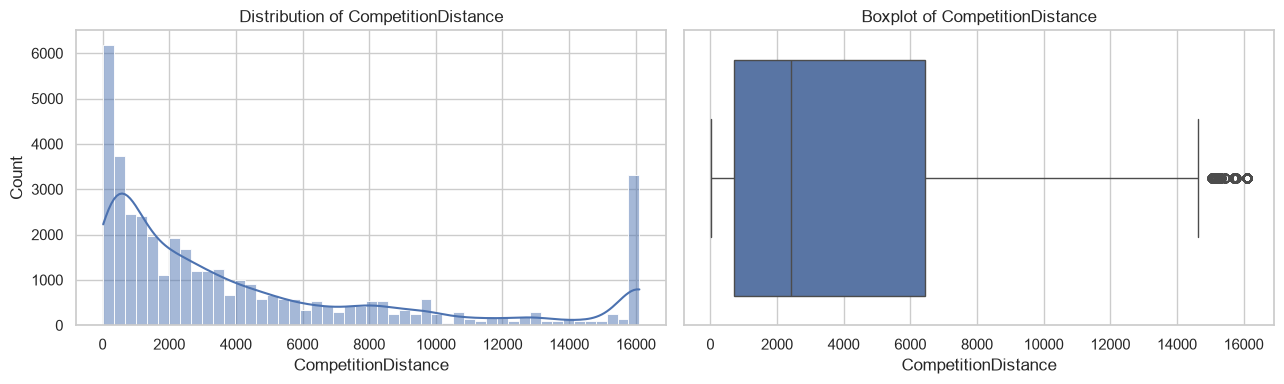

2026-11-10 11:23:42 | INFO | Numerical distribution analyzed: CompetitionDistance
2026-11-10 11:23:42 | INFO | Numerical univariate analysis completed


In [215]:
logger.info("=" * 70)
logger.info("Starting numerical univariate analysis")
logger.info("=" * 70)

try:
    for col in outlier_columns:

        fig, axes = plt.subplots(
            1, 2,
            figsize=(13, 4)
        )

        sns.histplot(
            data=test_df,
            x=col,
            kde=True,
            ax=axes[0]
        )

        axes[0].set_title(f"Distribution of {col}")
        axes[0].set_xlabel(col)

        sns.boxplot(
            data=test_df,
            x=col,
            ax=axes[1]
        )

        axes[1].set_title(f"Boxplot of {col}")
        axes[1].set_xlabel(col)

        plt.tight_layout()

        plt.show()
        plt.close()

        logger.info(
            f"Numerical distribution analyzed: {col}"
        )

    logger.info("Numerical univariate analysis completed")

except Exception:
    logger.exception("Error during numerical univariate analysis")


In [216]:
logger.info("=" * 70)
logger.info("Starting Categorical univariate analysis")
logger.info("=" * 70)

# Identify categorical columns
categorical_columns = test_df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Exclude identifiers if they are categorical
excluded_columns = ['Id']

categorical_columns = [
    col for col in categorical_columns
    if col not in excluded_columns
]

print("Categorical Features:")
print(categorical_columns)

# Numeric columns that represent categories
numeric_categorical_columns = [
    'DayOfWeek',
    'Open',
    'Promo',
    'SchoolHoliday',
    'Promo2',
    'CompetitionOpenSinceMonth',
    'CompetitionOpenSinceYear',
    'Promo2SinceWeek',
    'Promo2SinceYear'
]

# Include only columns that actually exist
numeric_categorical_columns = [
    col for col in numeric_categorical_columns
    if col in test_df.columns
]

# Combine categorical columns
categorical_columns = list(dict.fromkeys(
    categorical_columns + numeric_categorical_columns
))

logger.info(
    "Final categorical features for univariate analysis: %s",
    categorical_columns
)

print("Total categorical features:", len(categorical_columns))
print(categorical_columns)

2026-11-10 11:23:42 | INFO | ======================================================================
2026-11-10 11:23:42 | INFO | Starting Categorical univariate analysis
2026-11-10 11:23:42 | INFO | ======================================================================
C:\Users\ASUS\AppData\Local\Temp\ipykernel_8172\2128955477.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = test_df.select_dtypes(
2026-11-10 11:23:42 | INFO | Final categorical features for univariate analysis: ['Date', 'StateHoliday', 'StoreType', 'Assortment', 'PromoInterval', 'Da

Categorical Features:
['Date', 'StateHoliday', 'StoreType', 'Assortment', 'PromoInterval']
Total categorical features: 14
['Date', 'StateHoliday', 'StoreType', 'Assortment', 'PromoInterval', 'DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'Promo2', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2SinceWeek', 'Promo2SinceYear']


2026-11-10 11:23:42 | INFO | Starting categorical univariate analysis.
2026-11-10 11:23:42 | INFO | Analyzing categorical feature: Date
2026-11-10 11:23:42 | INFO | Category distribution for Date:
Date
2015-09-17    856
2015-09-16    856
2015-09-15    856
2015-09-14    856
2015-09-13    856
2015-09-12    856
2015-09-11    856
2015-09-10    856
2015-09-09    856
2015-09-08    856
2015-09-07    856
2015-09-06    856
2015-09-05    856
2015-09-04    856
2015-09-03    856
2015-09-02    856
2015-09-01    856
2015-08-31    856
2015-08-30    856
2015-08-29    856
2015-08-28    856
2015-08-27    856
2015-08-26    856
2015-08-25    856
2015-08-24    856
2015-08-23    856
2015-08-22    856
2015-08-21    856
2015-08-20    856
2015-08-19    856
2015-08-18    856
2015-08-17    856
2015-08-16    856
2015-08-15    856
2015-08-14    856
2015-08-13    856
2015-08-12    856
2015-08-11    856
2015-08-10    856
2015-08-09    856
2015-08-08    856
2015-08-07    856
2015-08-06    856
2015-08-05    856
2015-0

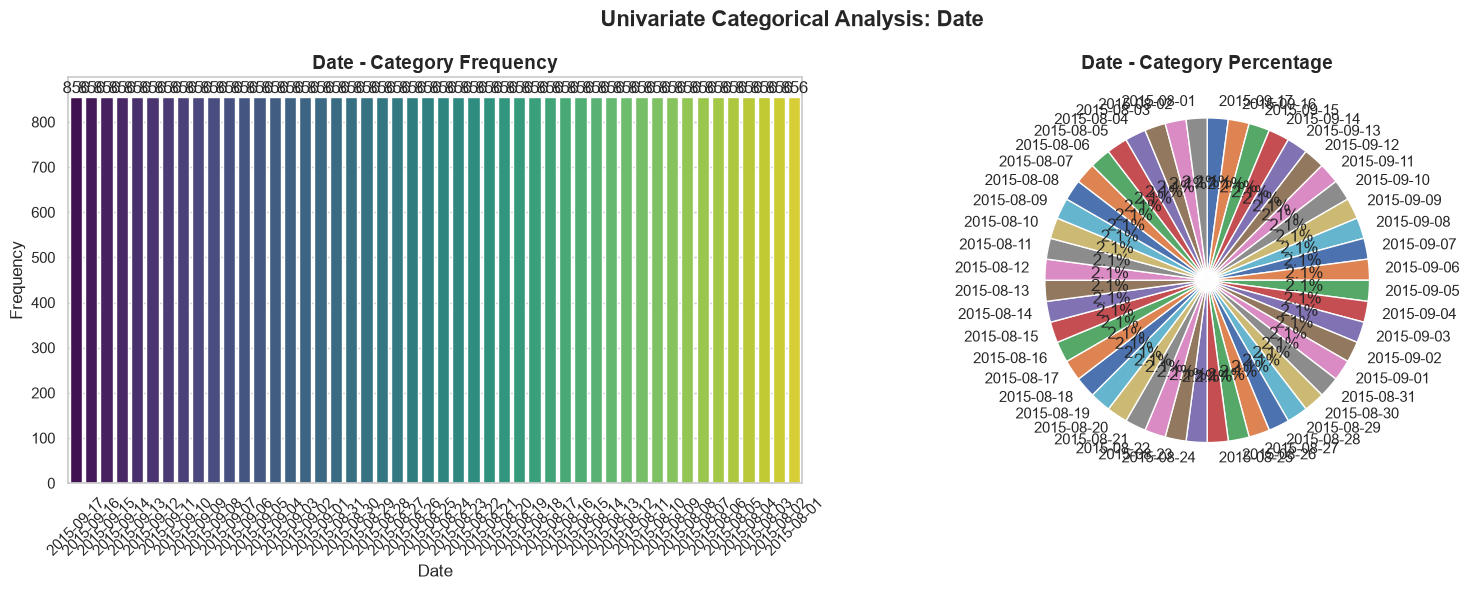

2026-11-10 11:23:46 | INFO | Successfully completed categorical analysis for Date
2026-11-10 11:23:46 | INFO | Analyzing categorical feature: StateHoliday
2026-11-10 11:23:46 | INFO | Category distribution for StateHoliday:
StateHoliday
0    40908
a      180


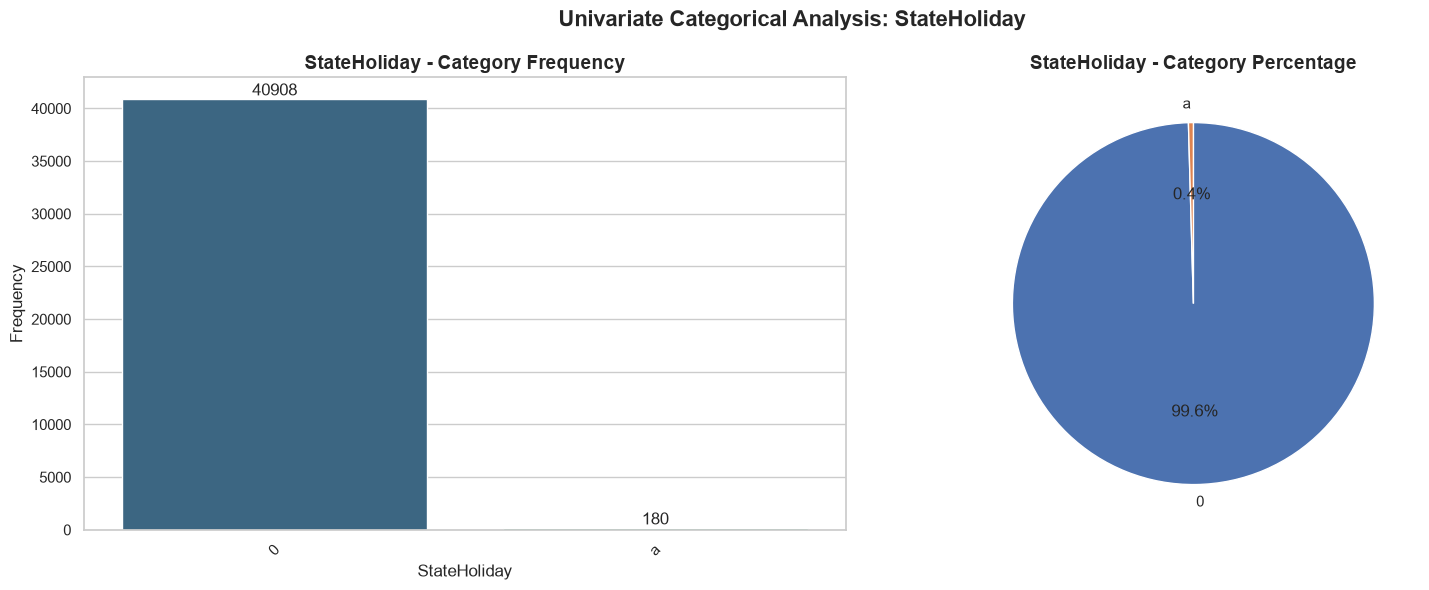

2026-11-10 11:23:47 | INFO | Successfully completed categorical analysis for StateHoliday
2026-11-10 11:23:47 | INFO | Analyzing categorical feature: StoreType
2026-11-10 11:23:47 | INFO | Category distribution for StoreType:
StoreType
a    22128
d    14112
c     4272
b      576


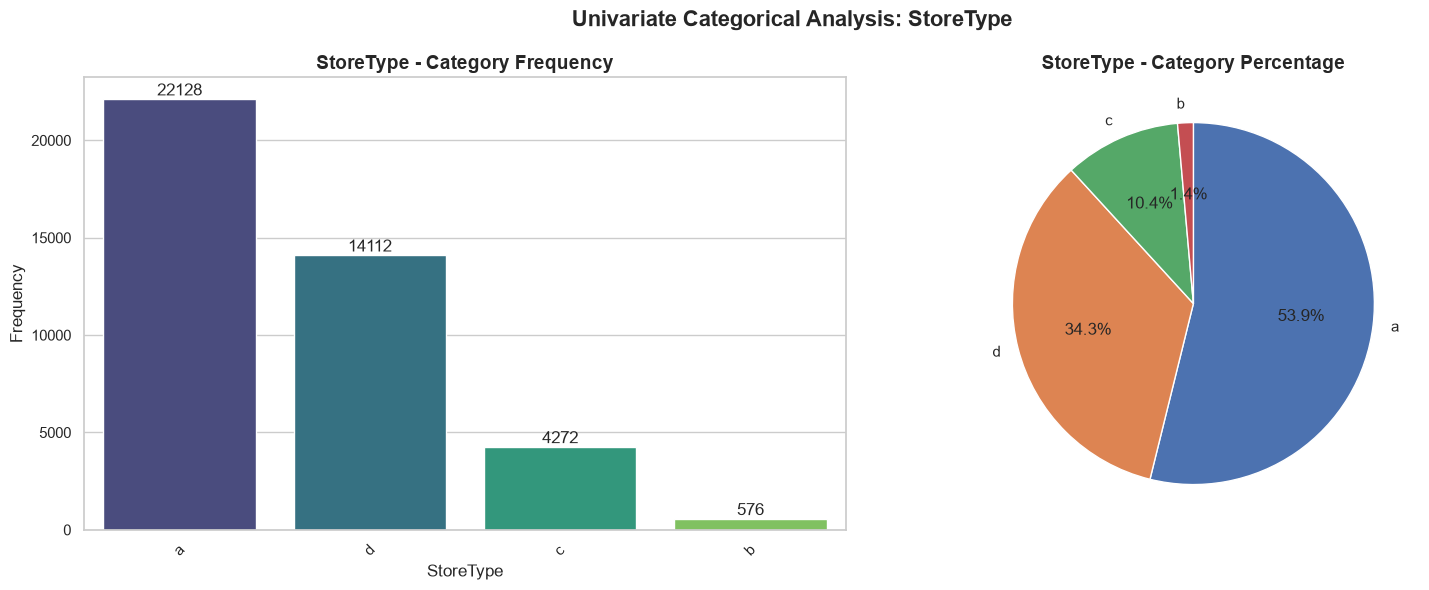

2026-11-10 11:23:47 | INFO | Successfully completed categorical analysis for StoreType
2026-11-10 11:23:47 | INFO | Analyzing categorical feature: Assortment
2026-11-10 11:23:47 | INFO | Category distribution for Assortment:
Assortment
c    20352
a    20304
b      432


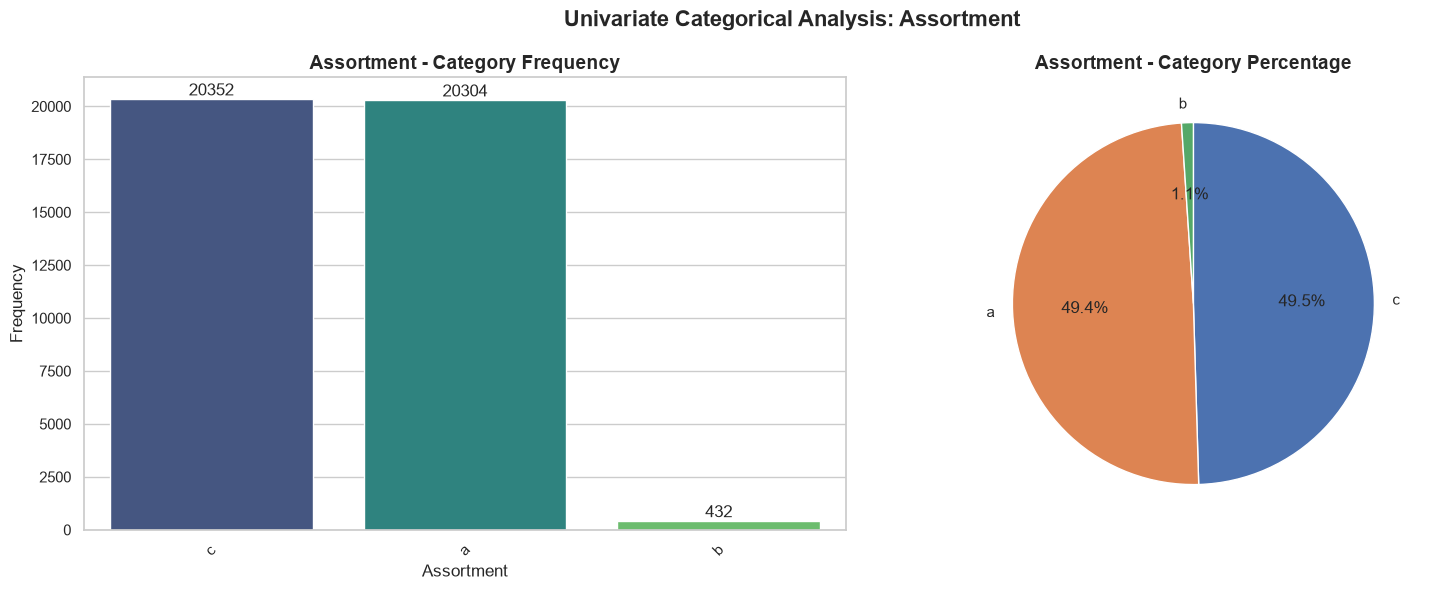

2026-11-10 11:23:48 | INFO | Successfully completed categorical analysis for Assortment
2026-11-10 11:23:48 | INFO | Analyzing categorical feature: PromoInterval
2026-11-10 11:23:48 | INFO | Category distribution for PromoInterval:
PromoInterval
NoPromo2            17232
Jan,Apr,Jul,Oct     13776
Feb,May,Aug,Nov      5712
Mar,Jun,Sept,Dec     4368


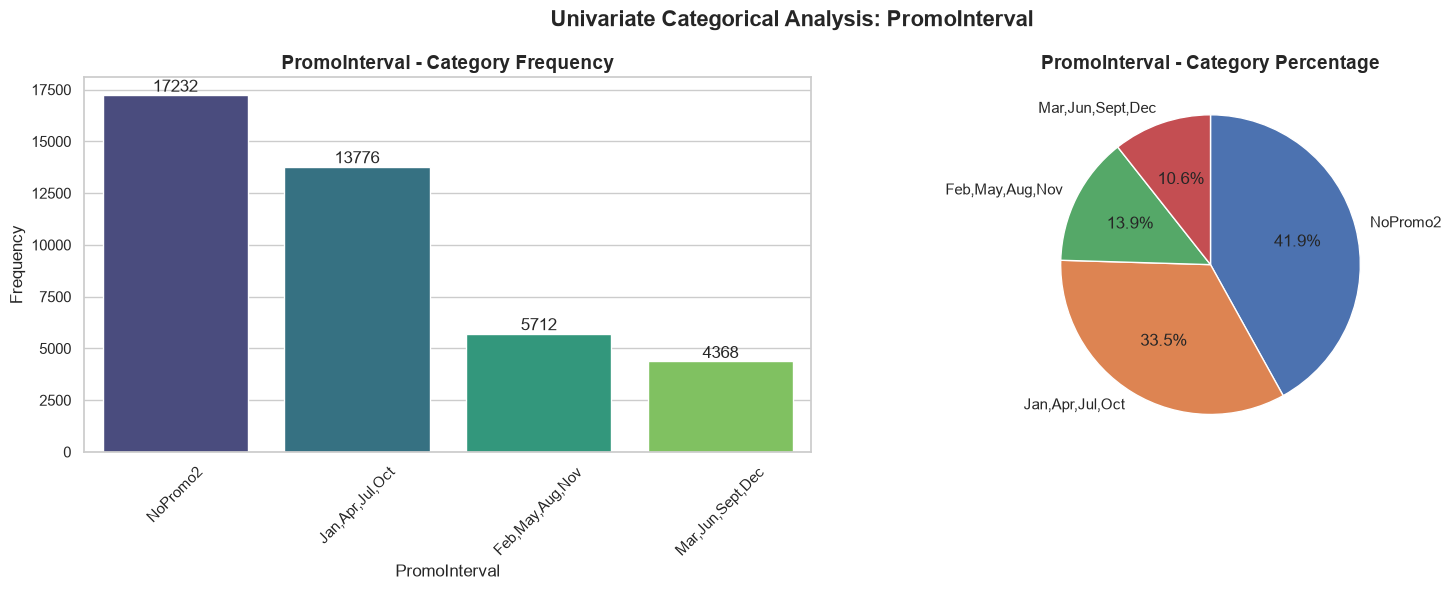

2026-11-10 11:23:49 | INFO | Successfully completed categorical analysis for PromoInterval
2026-11-10 11:23:49 | INFO | Analyzing categorical feature: DayOfWeek
2026-11-10 11:23:49 | INFO | Category distribution for DayOfWeek:
DayOfWeek
4    5992
3    5992
2    5992
1    5992
7    5992
6    5992
5    5136


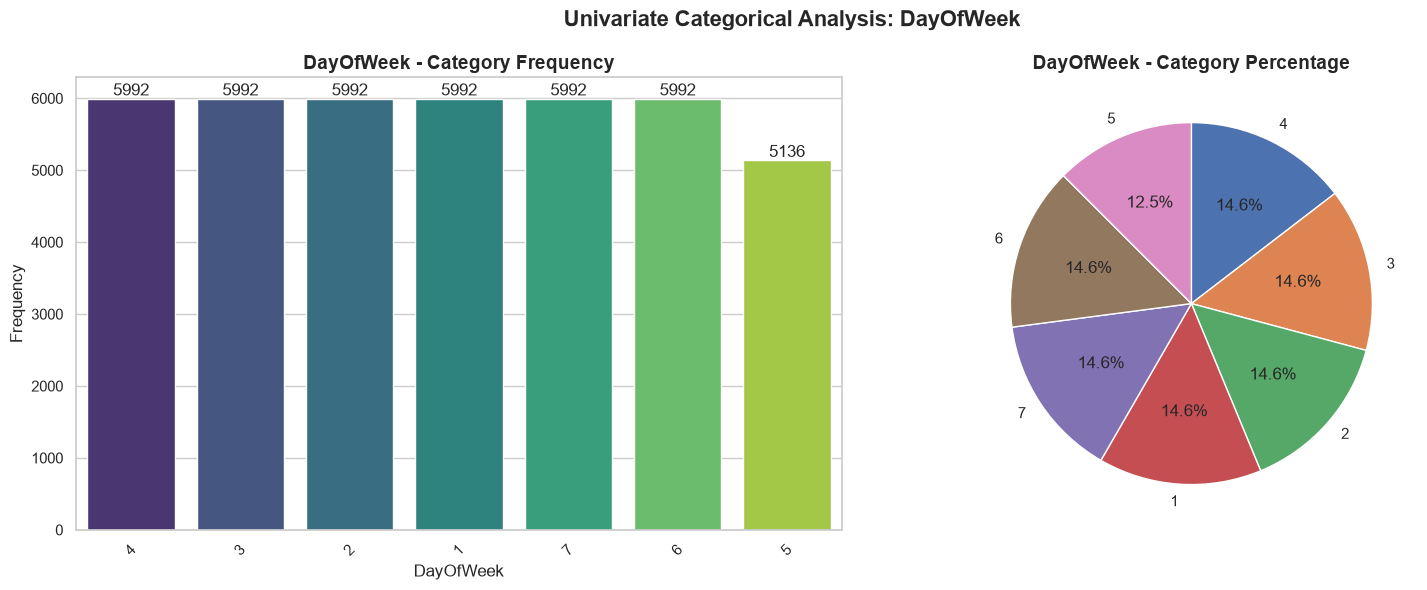

2026-11-10 11:23:50 | INFO | Successfully completed categorical analysis for DayOfWeek
2026-11-10 11:23:50 | INFO | Analyzing categorical feature: Open
2026-11-10 11:23:50 | INFO | Category distribution for Open:
Open
1.0    35104
0.0     5984


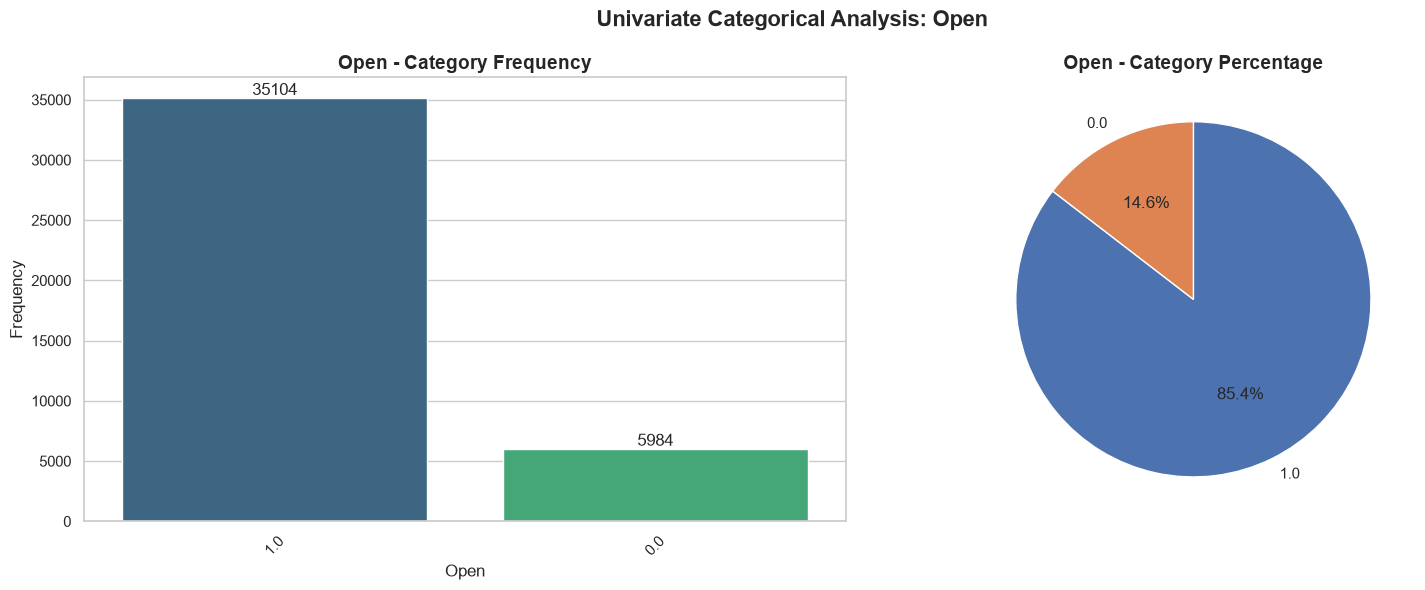

2026-11-10 11:23:51 | INFO | Successfully completed categorical analysis for Open
2026-11-10 11:23:51 | INFO | Analyzing categorical feature: Promo
2026-11-10 11:23:51 | INFO | Category distribution for Promo:
Promo
0    24824
1    16264


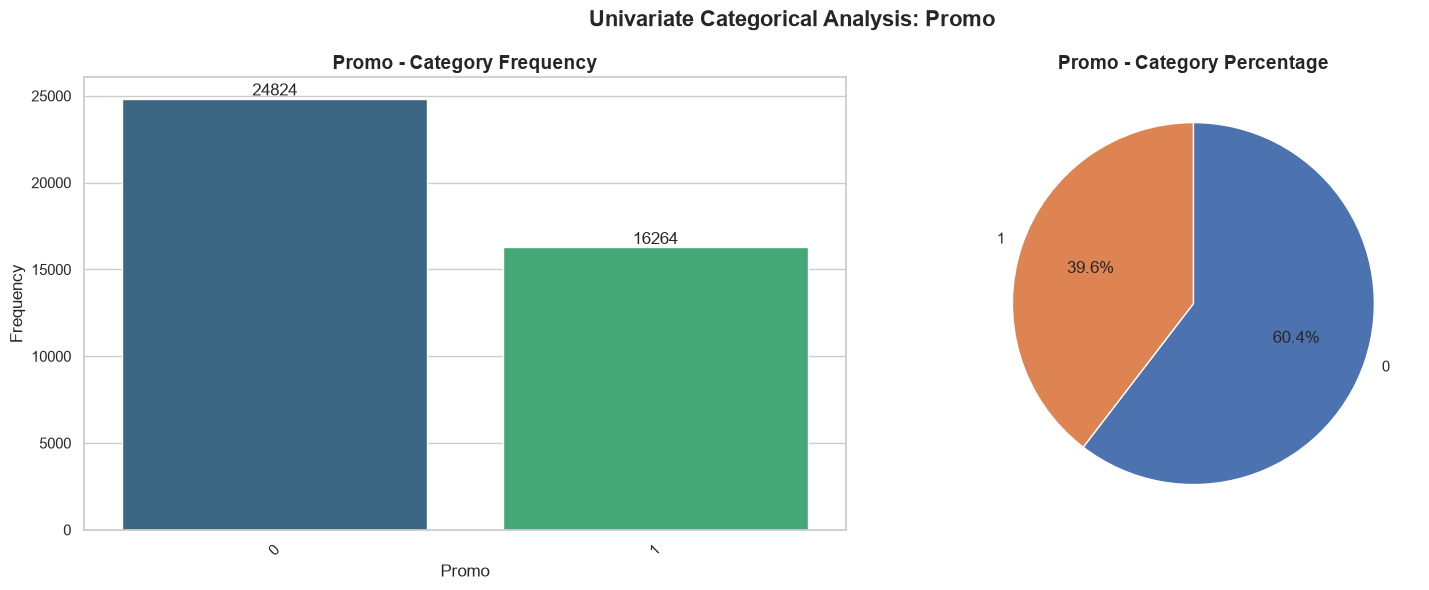

2026-11-10 11:23:51 | INFO | Successfully completed categorical analysis for Promo
2026-11-10 11:23:51 | INFO | Analyzing categorical feature: SchoolHoliday
2026-11-10 11:23:51 | INFO | Category distribution for SchoolHoliday:
SchoolHoliday
0    22866
1    18222


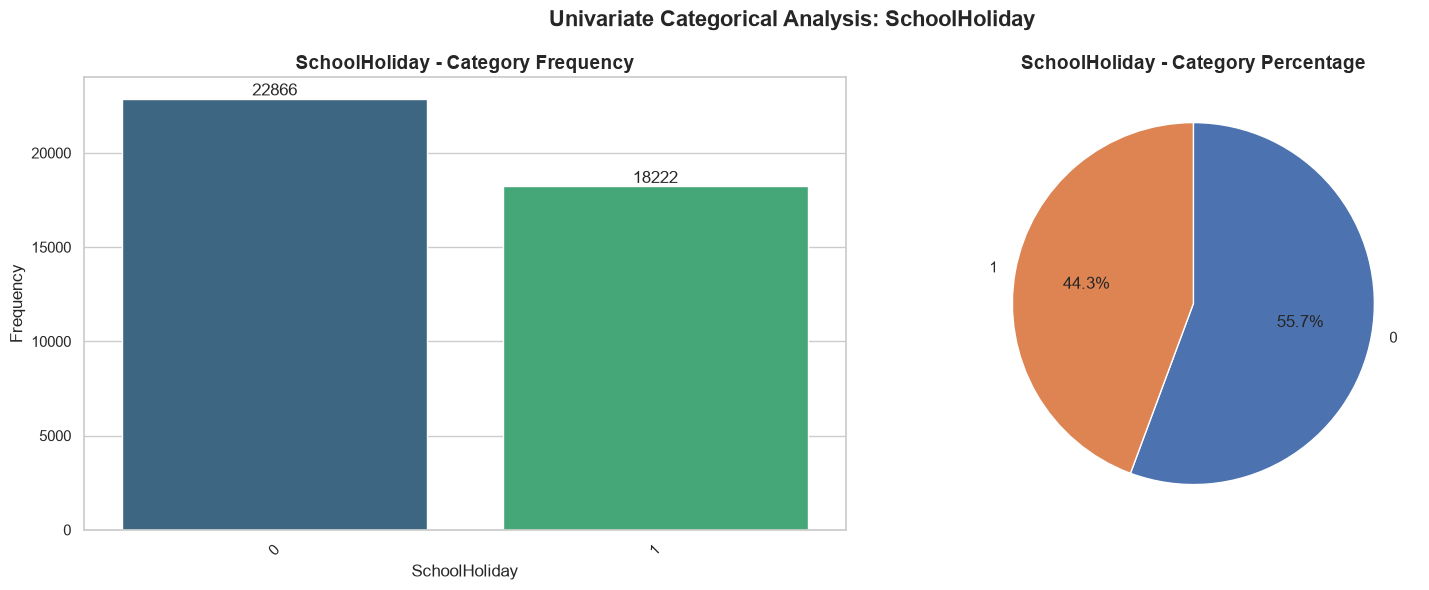

2026-11-10 11:23:52 | INFO | Successfully completed categorical analysis for SchoolHoliday
2026-11-10 11:23:52 | INFO | Analyzing categorical feature: Promo2
2026-11-10 11:23:52 | INFO | Category distribution for Promo2:
Promo2
1    23856
0    17232


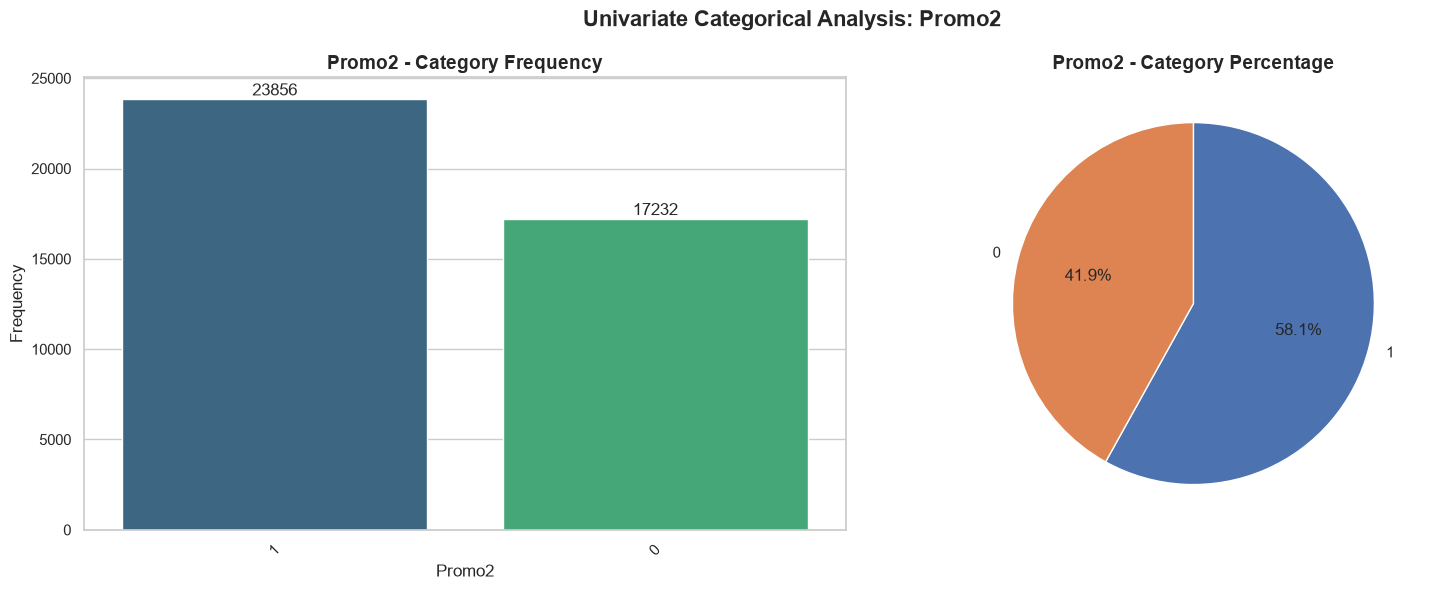

2026-11-10 11:23:52 | INFO | Successfully completed categorical analysis for Promo2
2026-11-10 11:23:52 | INFO | Categorical univariate analysis completed.


In [217]:
# Create output directory
categorical_output_dir = "outputs/test_eda/categorical_univariate"

os.makedirs(categorical_output_dir, exist_ok=True)

logger.info("Starting categorical univariate analysis.")

# Features to exclude from categorical plots
excluded_columns = [
    'Id',
    'CompetitionOpenSinceMonth',
    'CompetitionOpenSinceYear',
    'Promo2SinceWeek',
    'Promo2SinceYear'
]

categorical_columns = [
    col for col in categorical_columns
    if col not in excluded_columns
]

for col in categorical_columns:

    try:

        # Calculate category frequencies
        category_counts = test_df[col].fillna('Missing').astype(str).value_counts()

        # Calculate percentages
        category_percentages = (
            category_counts / category_counts.sum()
        ) * 100

        # Log category distribution
        logger.info("Analyzing categorical feature: %s", col)
        logger.info(
            "Category distribution for %s:\n%s",
            col,
            category_counts.to_string()
        )

        # Create side-by-side plots
        fig, axes = plt.subplots(
            1, 2,
            figsize=(16, 6)
        )

        # -------------------------
        # Bar Plot
        # -------------------------
        sns.barplot(
            x=category_counts.index,
            y=category_counts.values,
            hue=category_counts.index,
            palette='viridis',
            legend=False,
            ax=axes[0]
        )

        axes[0].set_title(
            f'{col} - Category Frequency',
            fontsize=14,
            fontweight='bold'
        )

        axes[0].set_xlabel(col)
        axes[0].set_ylabel('Frequency')
        axes[0].tick_params(axis='x', rotation=45)

        # Add count labels
        for container in axes[0].containers:
            axes[0].bar_label(container, fmt='%.0f')

        # -------------------------
        # Pie Chart
        # -------------------------
        axes[1].pie(
            category_counts.values,
            labels=category_counts.index,
            autopct='%1.1f%%',
            startangle=90,
            counterclock=False
        )

        axes[1].set_title(
            f'{col} - Category Percentage',
            fontsize=14,
            fontweight='bold'
        )

        # Main title
        fig.suptitle(
            f'Univariate Categorical Analysis: {col}',
            fontsize=16,
            fontweight='bold'
        )

        plt.tight_layout()

        plt.show()
        plt.close(fig)

        logger.info(
            "Successfully completed categorical analysis for %s",
            col
        )

    except Exception as e:

        logger.exception(
            "Error during categorical analysis for %s: %s",
            col,
            e
        )

logger.info("Categorical univariate analysis completed.")

## 📨 Key Insights

- The test dataset covers **48 days**, from **1 August 2015 to 17 September 2015**.
- Each date contains exactly **856 store records**, representing approximately **2.1%** of the total dataset.
- Weekly records are distributed almost equally, with each week contributing approximately **15%** of the observations.

### 🏬 Store Characteristics

| Feature | Distribution | Key Observation |
|:--|:--|:--|
| **Store Type** | A: 54%, D: 34%, C: 10%, B: 1% | Store Type A dominates the dataset. |
| **Assortment** | A: 49%, C: 49%, B: 1.1% | Basic and Extended assortments contribute almost equally. |
| **Promo2** | Active: 58%, Inactive: 41% | More stores participate in continuing promotional programmes. |

### 🔬 Operational & Promotional Characteristics

| Feature | Distribution | Key Observation |
|:--|:--|:--|
| **Open Status** | Open: 85%, Closed: 15% | Most records represent active trading days. |
| **Promo** | Active: 40%, Inactive: 60% | A larger share of records has no active daily promotion. |
| **School Holiday** | Yes: 44%, No: 55% | Records are relatively balanced across school-holiday conditions. |
| **State Holiday** | Yes: 0.4% | Only a small proportion of records fall on state holidays. |

## Overall Observations

- **Balanced temporal coverage:** Equal daily record counts provide consistent representation across the test period.
- **Store-type concentration:** Store Types A and D account for approximately 88% of all records.
- **Assortment distribution:** Basic and Extended assortments dominate, while Extra assortment has limited representation.
- **Operational coverage:** Approximately 85% of records correspond to open stores.
- **Promotional coverage:** Daily promotions are less frequent than non-promotional observations, whereas continuing promotions (Promo2) cover a larger proportion of stores.
- **Holiday representation:** State-holiday observations are very limited compared with school-holiday observations.

> **Overall Insight:** The test dataset provides consistent daily coverage but has an uneven distribution across store types and promotional characteristics. These patterns should be considered during model evaluation and final sales prediction.

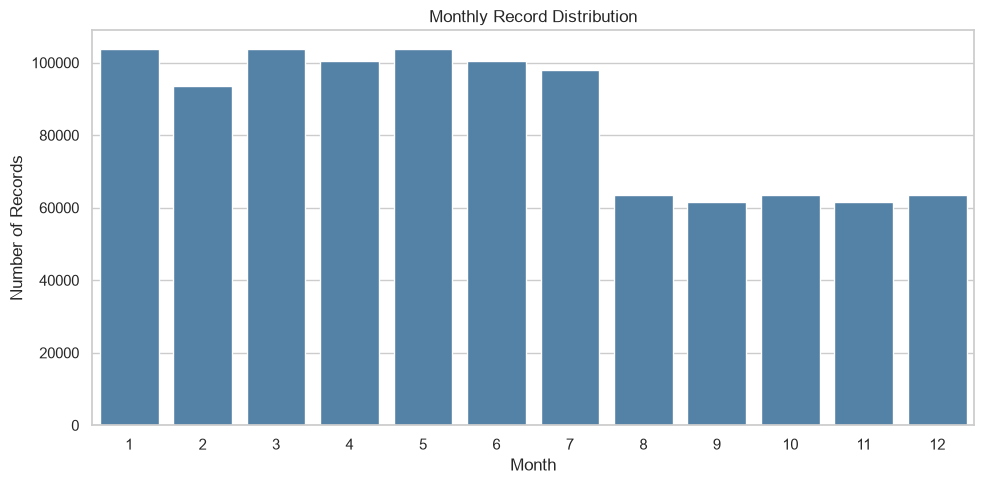

In [218]:
monthly_records = (
    train_df.groupby('Month')
    .size()
    .reset_index(name='RecordCount')
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=monthly_records,
    x='Month',
    y='RecordCount',
    color='steelblue'
)

plt.title('Monthly Record Distribution')
plt.xlabel('Month')
plt.ylabel('Number of Records')

plt.tight_layout()

plt.show()
plt.close()

### 📆 Monthly Record Distribution

- **Higher representation:** January, March, and May contain the highest number of recorded observations.
- **Lower representation:** September to December show comparatively fewer records.
- **Uneven monthly coverage:** The variation in monthly record counts indicates differences in data availability across the year.

**Analytical Consideration:** Account for unequal monthly representation when analysing seasonal patterns and training forecasting models. Use month-wise comparisons and ensure that lower-frequency months are adequately evaluated to avoid biased conclusions.

In [219]:
logger.info("=" * 70)
logger.info("Starting date-based analysis")
logger.info("=" * 70)

try:
    test_df["Date"] = pd.to_datetime(
        test_df["Date"],
        errors="coerce"
    )

    logger.info(
        f"Date range: {test_df['Date'].min()} to "
        f"{test_df['Date'].max()}"
    )

    logger.info(
        f"Invalid or missing dates: {test_df['Date'].isna().sum()}"
    )

    logger.info(
        f"Unique dates: {test_df['Date'].nunique()}"
    )

    logger.info(
        f"Unique stores: {test_df['Store'].nunique()}"
    )

    logger.info("Date-based dataset inspection completed")

except Exception:
    logger.exception("Error during date-based inspection")


2026-11-10 11:23:53 | INFO | ======================================================================
2026-11-10 11:23:53 | INFO | Starting date-based analysis
2026-11-10 11:23:53 | INFO | ======================================================================
2026-11-10 11:23:53 | INFO | Date range: 2015-08-01 00:00:00 to 2015-09-17 00:00:00
2026-11-10 11:23:53 | INFO | Invalid or missing dates: 0
2026-11-10 11:23:53 | INFO | Unique dates: 48
2026-11-10 11:23:53 | INFO | Unique stores: 856
2026-11-10 11:23:53 | INFO | Date-based dataset inspection completed


Assortment       a     b       c
StoreType                       
a           346389     0  205238
b             6594  8294     942
c            70878     0   65962
d           113584     0  199328


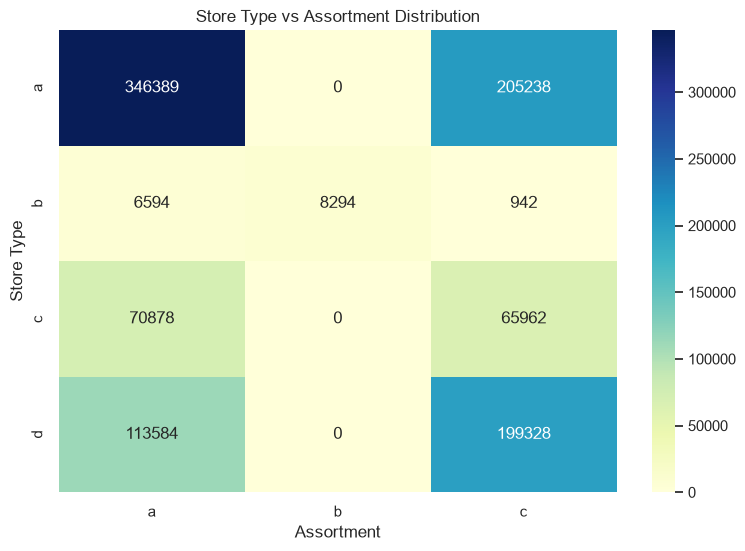

2026-11-10 11:23:53 | INFO | ======================================================================
2026-11-10 11:23:53 | INFO | Store Type vs Assortment Distribution
2026-11-10 11:23:53 | INFO | ======================================================================
2026-11-10 11:23:53 | INFO | 
Assortment       a     b       c
StoreType                       
a           346389     0  205238
b             6594  8294     942
c            70878     0   65962
d           113584     0  199328


In [220]:
store_assortment = pd.crosstab(
    train_df['StoreType'],
    train_df['Assortment']
)

print(store_assortment)

plt.figure(figsize=(9, 6))

sns.heatmap(
    store_assortment,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title('Store Type vs Assortment Distribution')
plt.xlabel('Assortment')
plt.ylabel('Store Type')

plt.show()
plt.close()

logger.info("=" * 70)
logger.info("Store Type vs Assortment Distribution")
logger.info("=" * 70)
logger.info(
     "\n%s",
    store_assortment.to_string()
)

## 🏪 Store Type vs. Assortment Distribution

### Distribution Overview

The cross-tabulation below shows how assortment types are distributed across different store types.

| **Store Type** | **Basic (A)** | **Extra (B)** | **Extended (C)** |
|:--|--:|--:|--:|
| **A** | 346,389 | 0 | 205,238 |
| **B** | 6,594 | 8,294 | 942 |
| **C** | 70,878 | 0 | 65,962 |
| **D** | 113,584 | 0 | 199,328 |

### 🥢Key Findings

- **Store Type A:** Predominantly operates with Basic assortment (346,389 records), followed by Extended assortment (205,238).
- **Store Type B:** Has the only records with Extra assortment (8,294), making it distinct from other store types.
- **Store Type C:** Shows a relatively balanced distribution between Basic and Extended assortments.
- **Store Type D:** Has a strong preference for Extended assortment (199,328 records), compared with Basic assortment (113,584).
- **Assortment concentration:** Extra assortment is highly limited and appears exclusively in Store Type B.

### 🛻 Business Insights

- Prioritise Basic assortment strategies for Store Types A and C.
- Focus on Extended assortment for Store Type D, where it has greater representation.
- Evaluate the performance of Extra assortment in Store Type B before considering expansion.
- Develop assortment-specific inventory and promotional strategies rather than applying a uniform approach across all store types.

>**Overall Insight:** Store Types A and C are concentrated around Basic and Extended assortments, while Store Type D has a stronger Extended assortment presence. Extra assortment is exclusive to Store Type B, indicating a distinct product-mix strategy.

   DayOfWeek   OpenRate
0          1  95.045948
1          2  98.830871
2          3  97.440016
3          4  92.319929
4          5  95.059824
5          6  99.535687
6          7   2.482554


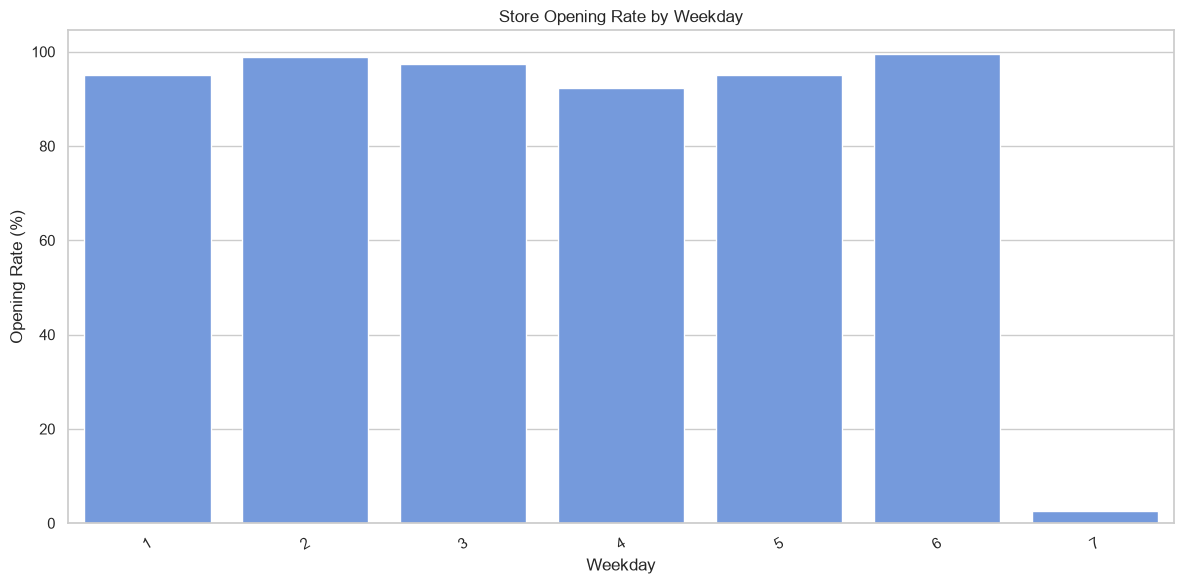

2026-11-10 11:23:53 | INFO | ======================================================================
2026-11-10 11:23:53 | INFO | Opening rate by weekday
2026-11-10 11:23:53 | INFO | ======================================================================
2026-11-10 11:23:53 | INFO | 
 DayOfWeek  OpenRate
         1 95.045948
         2 98.830871
         3 97.440016
         4 92.319929
         5 95.059824
         6 99.535687
         7  2.482554


In [221]:
weekday_open_rate = (
    train_df.groupby('DayOfWeek', observed=True)['Open']
    .mean()
    .mul(100)
    .reset_index(name='OpenRate')
)

print(weekday_open_rate)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=weekday_open_rate,
    x='DayOfWeek',
    y='OpenRate',
    color='cornflowerblue'
)

plt.title('Store Opening Rate by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Opening Rate (%)')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()
plt.close()

logger.info("=" * 70)
logger.info("Opening rate by weekday")
logger.info("=" * 70)

logger.info(
    "\n%s",
    weekday_open_rate.to_string(index=False)
)

## 🖥️ Store Opening Rate by Day of the Week

| **Day of Week** | **Open Rate (%)** |
|:--|--:|
| Monday (1) | 95.05% |
| Tuesday (2) | 98.83% |
| Wednesday (3) | 97.44% |
| Thursday (4) | 92.32% |
| Friday (5) | 95.06% |
| Saturday (6) | **99.54%** |
| Sunday (7) | **2.48%** |

### ⏳ Key Findings

- **Saturday:** Records the highest opening rate at 99.54%, indicating that almost all stores operate on Saturdays.
- **Sunday:** Shows a significantly lower opening rate of 2.48%, suggesting that most stores remain closed.
- **Tuesday and Wednesday:** Maintain high opening rates above 97%.
- **Thursday:** Has the lowest opening rate among regular weekdays at 92.32%.
- **Overall Pattern:** Store operations are concentrated from Monday to Saturday, with Sunday being predominantly a non-operational day.

### 🎢 Business Recommendations

- **Promotional Planning:** Prioritise Monday–Saturday campaigns when most stores are operational.
- **Sunday Strategy:** Avoid scheduling regular promotions across all stores on Sundays. Target only stores that are open.
- **Inventory & Staffing:** Align stock replenishment and workforce allocation with higher operating activity, particularly on Saturdays.
- **Forecasting:** Use `DayOfWeek` and `Open` as important predictive features to capture weekly operating patterns.

>**Overall Insight:** Saturday represents the strongest operating day, while Sunday has minimal store activity. Promotional planning, staffing, and sales forecasting should account for these differences in store operating patterns.

  StoreType   OpenRate
0         a  82.859795
1         b  98.313329
2         c  82.562116
3         d  82.698650


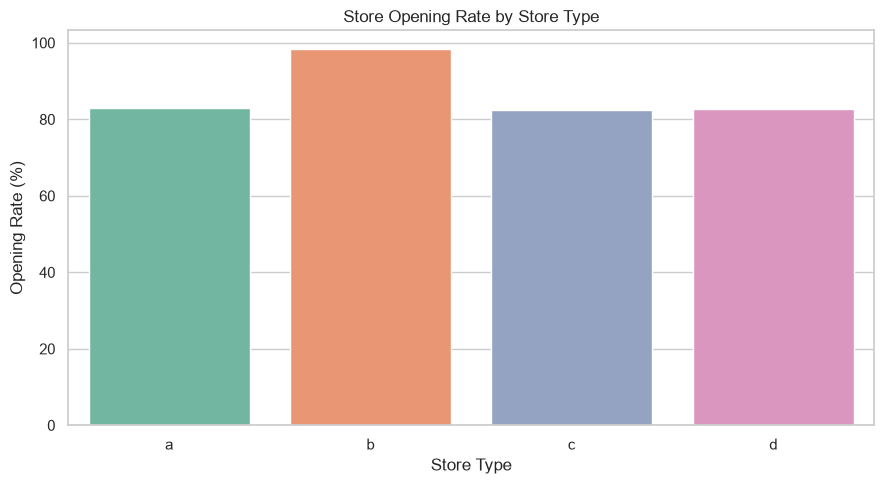

2026-11-10 11:23:54 | INFO | ======================================================================
2026-11-10 11:23:54 | INFO | Opening rate by store type
2026-11-10 11:23:54 | INFO | ======================================================================
2026-11-10 11:23:54 | INFO | 
StoreType  OpenRate
        a 82.859795
        b 98.313329
        c 82.562116
        d 82.698650


In [222]:
storetype_open_rate = (
    train_df.groupby('StoreType', observed=True)['Open']
    .mean()
    .mul(100)
    .reset_index(name='OpenRate')
)

print(storetype_open_rate)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=storetype_open_rate,
    x='StoreType',
    y='OpenRate',
    hue='StoreType',
    palette='Set2',
    legend=False
)

plt.title('Store Opening Rate by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Opening Rate (%)')

plt.tight_layout()

plt.show()
plt.close()

logger.info("=" * 70)
logger.info("Opening rate by store type")
logger.info("=" * 70)

logger.info(
    "\n%s",
    storetype_open_rate.to_string(index=False)
)

## 🏗️ Store Opening Rate by Store Type

- **Store Type B** has the highest opening rate at 98.31%, indicating near-continuous operations.
- **Store Types A, C, and D** have similar opening rates of approximately 82.5–82.9%.
- The difference suggests that Store Type B follows a distinct operating pattern compared with the other store types.

### 🎭 Business Recommendations

- **Store Type B:** Maintain consistent inventory and staffing due to its high operating frequency.
- **Store Types A, C, and D:** Align inventory replenishment and promotional schedules with their operating days.
- **Promotional Planning:** Use store-specific opening patterns to avoid allocating promotional budgets to closed-store days.
- **Sales Forecasting:** Include `StoreType` and `Open` as predictive features to capture differences in operating behaviour.

>**Overall Insight:** Store Type B demonstrates the highest operational availability, while Store Types A, C, and D share relatively similar opening patterns. Store-specific operational behaviour should be considered when planning promotions and forecasting sales.

Promo2             0          1
StoreType                      
a          53.249932  46.750068
b          71.408718  28.591282
c          50.118386  49.881614
d          42.952651  57.047349


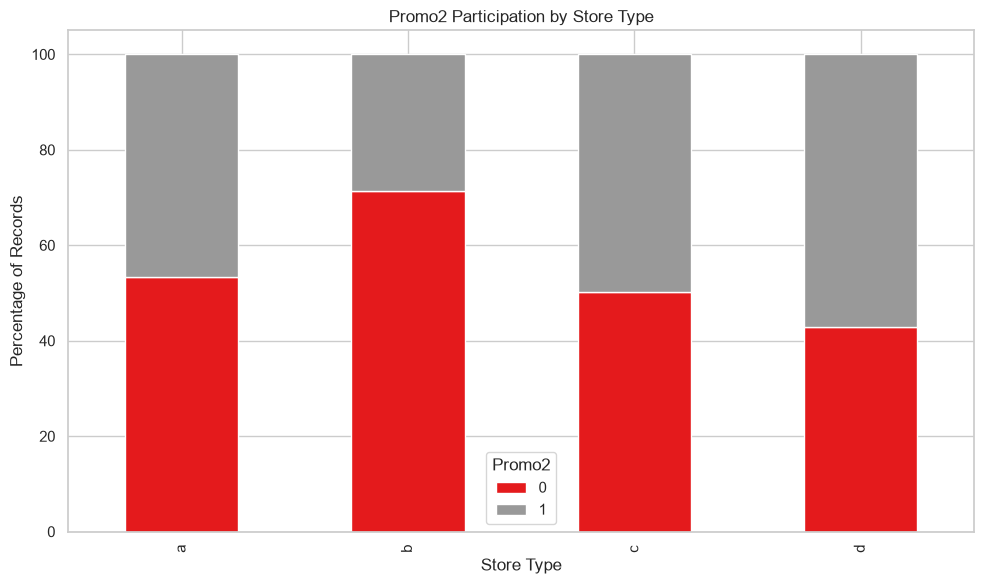

2026-11-10 11:23:54 | INFO | ======================================================================
2026-11-10 11:23:54 | INFO | Promo2 participation by store type
2026-11-10 11:23:54 | INFO | ======================================================================
2026-11-10 11:23:54 | INFO | 
Promo2             0          1
StoreType                      
a          53.249932  46.750068
b          71.408718  28.591282
c          50.118386  49.881614
d          42.952651  57.047349


In [223]:
promo2_storetype = pd.crosstab(
    train_df['StoreType'],
    train_df['Promo2'],
    normalize='index'
) * 100

print(promo2_storetype)

promo2_storetype.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='Set1'
)

plt.title('Promo2 Participation by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Percentage of Records')
plt.legend(title='Promo2')

plt.tight_layout()

plt.show()
plt.close()

logger.info("=" * 70)
logger.info("Promo2 participation by store type")
logger.info("=" * 70)

logger.info(
    "\n%s",
    promo2_storetype.to_string()
)

## 🏟️ Promo2 Distribution Across Store Types

The table represents the percentage distribution of stores with and without ongoing Promo2 participation across different store types.

| **Store Type** | **No Promo2 (0)** | **Active Promo2 (1)** |
|:--|--:|--:|
| A | 53.25% | 46.75% |
| B | **71.41%** | 28.59% |
| C | 50.12% | 49.88% |
| D | 42.95% | **57.05%** |

### 🔏 Key Findings

- **Store Type D:** Has the highest Promo2 participation at 57.05%.
- **Store Type C:** Shows an almost equal distribution between Promo2 and non-Promo2 stores.
- **Store Type A:** Has slightly higher non-Promo2 participation (53.25%).
- **Store Type B:** Has the lowest Promo2 participation at 28.59%, with most stores not participating in ongoing promotions.

### 🛃 Business Recommendations

- **Store Type D:** Optimise existing promotional campaigns and evaluate their incremental sales and profitability.
- **Store Type C:** Test additional promotional offers to determine whether increased participation can improve sales.
- **Store Type A:** Identify non-Promo2 stores with growth potential and introduce targeted campaigns.
- **Store Type B:** Evaluate whether ongoing promotions are suitable for its operating model before expanding participation.
- **Performance Monitoring:** Compare sales uplift, customer traffic, and profit margins between Promo2 and non-Promo2 stores within each store type.

**Overall Insight:** Store Type D has the strongest Promo2 participation, whereas Store Type B has the lowest. Promotional strategies should therefore be tailored to each store type rather than implemented uniformly.

*Note: Promo2 participation indicates ongoing promotional programme status; it does not necessarily mean a promotion was active on every recorded day.*

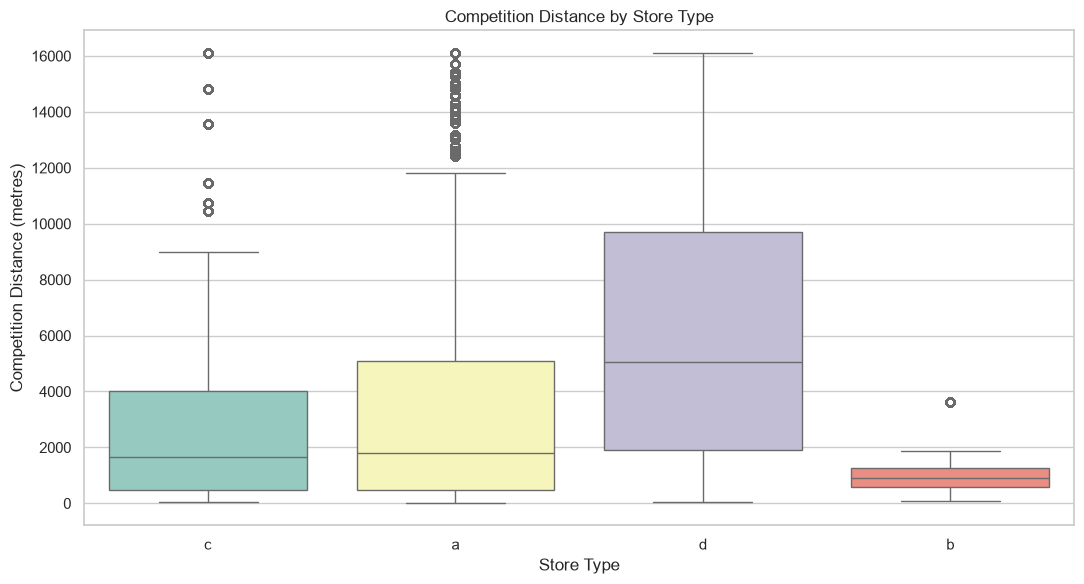

In [224]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=train_df,
    x='StoreType',
    y='CompetitionDistance',
    hue='StoreType',
    palette='Set3',
    legend=False
)

plt.title('Competition Distance by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Competition Distance (metres)')

plt.tight_layout()

plt.show()
plt.close()

## 🐪 Competition Distance Distribution by Store Type

- **Store Type D:** Has the highest median competition distance (approximately 5,000 metres), indicating that competitors are generally located farther away.
- **Store Type B:** Has the lowest median distance (approximately 900 metres) and a relatively narrow distribution, suggesting closer competitor proximity.
- **Store Types A and C:** Show wide variations in competition distance, indicating differences in competitive environments across their stores.
- **Potential Outliers:** Store Types A and C contain several stores with exceptionally high competitor distances.
- **Distribution Variation:** Store Type D exhibits the widest overall spread, reflecting substantial variation in competitor proximity.

### 🏢 Business Recommendations

- **Store Type B:** Focus on customer retention, competitive pricing, loyalty rewards, and differentiated product offerings due to closer competitor proximity.
- **Store Types A and C:** Identify stores facing intense local competition and deploy location-specific promotional campaigns.
- **Store Type D:** Focus on customer acquisition, product availability, and increasing basket value while monitoring local market changes.
- **Targeted Promotions:** Prioritise stores with both high competitive pressure and declining sales rather than relying solely on competitor distance.

### 📥 Overall Insight

Store Type D generally operates with competitors farther away, whereas Store Type B experiences closer competitive proximity. Store Types A and C show considerable geographical variation.

**Strategic Priority:** Combine competition distance with store-level sales and customer trends to identify competitive pressure and implement targeted promotional strategies.

*Note: Competition distance alone does not determine sales performance. Local demand, customer footfall, accessibility, and store characteristics should also be considered.*

In [225]:
store_opening_summary = (
    train_df.groupby('Store')
    .agg(
        TotalRecords=('Open', 'size'),
        OpenDays=('Open', lambda x: (x == 1).sum()),
        ClosedDays=('Open', lambda x: (x == 0).sum()),
        OpeningRate=('Open', 'mean')
    )
    .reset_index()
)

store_opening_summary['OpeningRate'] *= 100

# Sort stores by opening rate
store_opening_summary = store_opening_summary.sort_values(
    'OpeningRate',
    ascending=False
)

print("Top 10 stores by opening rate:")
print(store_opening_summary.head(10))

print("\nBottom 10 stores by opening rate:")
print(store_opening_summary.tail(10))

logger.info("=" * 70)
logger.info("Stores and their opening rates analysis")
logger.info("=" * 70)

logger.info(
    "Top 10 stores by opening rate:\n%s",
    store_opening_summary.head(10).to_string(index=False)
)

logger.info(
    "Bottom 10 stores by opening rate:\n%s",
    store_opening_summary.tail(10).to_string(index=False)
)

2026-11-10 11:23:57 | INFO | ======================================================================
2026-11-10 11:23:57 | INFO | Stores and their opening rates analysis
2026-11-10 11:23:57 | INFO | ======================================================================
2026-11-10 11:23:57 | INFO | Top 10 stores by opening rate:
 Store  TotalRecords  OpenDays  ClosedDays  OpeningRate
   494           942       942           0        100.0
    85           942       942           0        100.0
   562           942       942           0        100.0
   423           942       942           0        100.0
   733           942       942           0        100.0
  1097           942       942           0        100.0
   262           942       942           0        100.0
   769           942       942           0        100.0
   682           942       942           0        100.0
   335           942       942           0        100.0
2026-11-10 11:23:57 | INFO | Bottom 10 stores by openin

Top 10 stores by opening rate:
      Store  TotalRecords  OpenDays  ClosedDays  OpeningRate
493     494           942       942           0        100.0
84       85           942       942           0        100.0
561     562           942       942           0        100.0
422     423           942       942           0        100.0
732     733           942       942           0        100.0
1096   1097           942       942           0        100.0
261     262           942       942           0        100.0
768     769           942       942           0        100.0
681     682           942       942           0        100.0
334     335           942       942           0        100.0

Bottom 10 stores by opening rate:
     Store  TotalRecords  OpenDays  ClosedDays  OpeningRate
743    744           758       605         153    79.815303
836    837           942       751         191    79.723992
559    560           942       747         195    79.299363
673    674           94

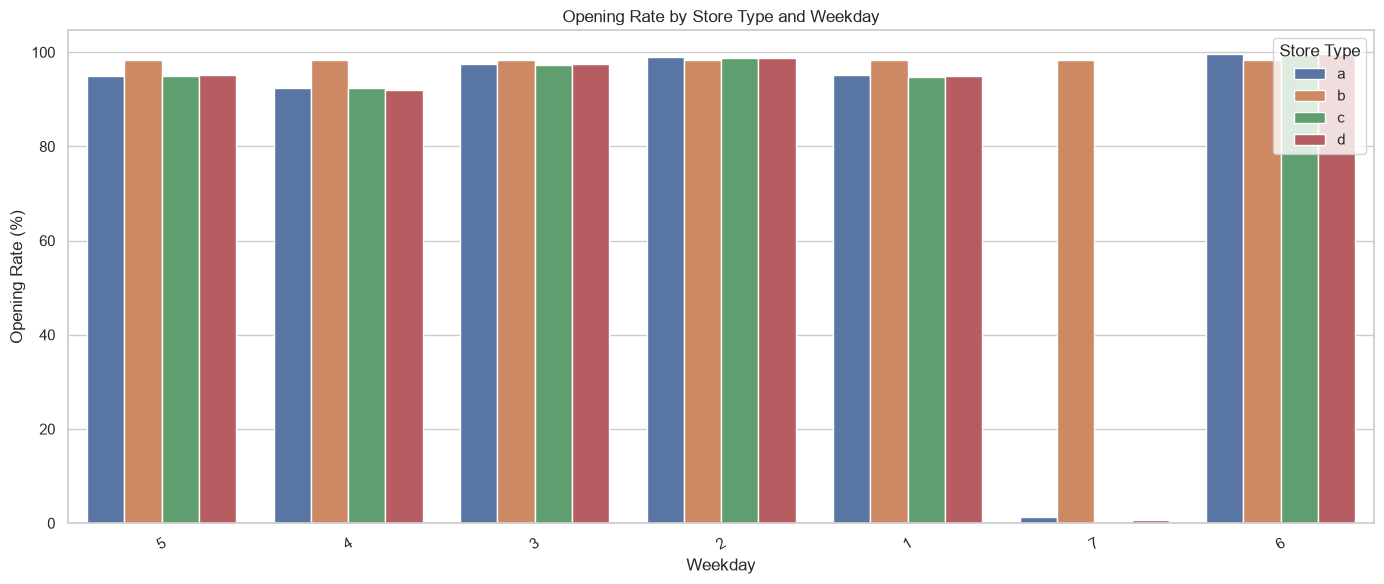

2026-11-10 11:24:01 | INFO | ======================================================================
2026-11-10 11:24:01 | INFO | Store type, weekday and opening analysis
2026-11-10 11:24:01 | INFO | ======================================================================
2026-11-10 11:24:01 | INFO | 
StoreType  DayOfWeek  OpeningRate
        a          1    95.055043
        a          2    98.873432
        a          3    97.457026
        a          4    92.337455
        a          5    94.997850
        a          6    99.528566
        a          7     1.401560
        b          1    98.357016
        b          2    98.236332
        b          3    98.236332
        b          4    98.281181
        b          5    98.325253
        b          6    98.357016
        b          7    98.401421
        c          1    94.811999
        c          2    98.678706
        c          3    97.199265
        c          4    92.490824
        c          5    94.886827
        c          6

In [226]:
storetype_weekday_open = (
    train_df.groupby(
        ['StoreType', 'DayOfWeek'],
        observed=True
    )['Open']
    .mean()
    .mul(100)
    .reset_index(name='OpeningRate')
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=storetype_weekday_open,
    x='DayOfWeek',
    y='OpeningRate',
    hue='StoreType',
    order=train_df["DayOfWeek"]
)

plt.title('Opening Rate by Store Type and Weekday')
plt.xlabel('Weekday')
plt.ylabel('Opening Rate (%)')
plt.xticks(rotation=30)
plt.legend(title='Store Type')

plt.tight_layout()

plt.show()
plt.close()

logger.info("=" * 70)
logger.info("Store type, weekday and opening analysis")
logger.info("=" * 70)

logger.info(
    "\n%s",
    storetype_weekday_open.to_string(index=False)
)

## 📆 Store Opening Patterns by Store Type and Weekday

- **Saturday:** Records the highest opening rates across Store Types A, C, and D, with approximately 99.5% of stores operational.
- **Sunday:** Store Types A, C, and D are predominantly closed, while Store Type B maintains an opening rate of approximately 98.4%.
- **Tuesday:** All four store types demonstrate consistently high opening rates of approximately 98–99%.
- **Thursday:** Shows the lowest weekday opening rates across Store Types A, C, and D, ranging from 91.91% to 92.49%.
- **Store Type B:** Maintains a remarkably consistent opening rate of approximately 98% throughout the week.

### 🏛️ Business Recommendations

- **Sunday Operations:** Prioritise Store Type B for Sunday-specific promotions and customer engagement campaigns.
- **Weekday Promotions:** Schedule major promotional campaigns across all store types from Monday to Saturday.
- **Thursday Opportunities:** Investigate lower opening rates on Thursdays for Store Types A, C, and D before allocating promotional budgets.
- **Operational Planning:** Align staffing, inventory replenishment, and promotional activities with store-specific operating schedules.
- **Sales Forecasting:** Use the interaction between `StoreType`, `DayOfWeek`, and `Open` to capture differences in weekly operating behaviour.

### 👩‍🦱 Overall Insight

Store Types A, C, and D follow similar operating patterns, with Sunday being predominantly non-operational. In contrast, Store Type B maintains almost continuous operations throughout the week.

**Strategic Priority:** Develop weekday-based promotional strategies for Stores A, C, and D, while leveraging Sunday operations in Store Type B to capture additional sales opportunities.

Opening status by Promo (%):
Open           0          1
Promo                      
0      25.691551  74.308449
1       2.881880  97.118120


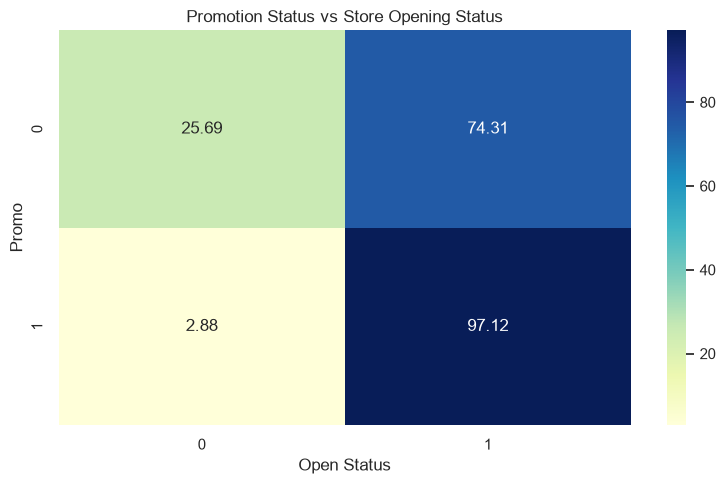

2026-11-10 11:24:02 | INFO | ======================================================================
2026-11-10 11:24:02 | INFO | Promo vs Open relationship
2026-11-10 11:24:02 | INFO | ======================================================================
2026-11-10 11:24:02 | INFO | 
Open           0          1
Promo                      
0      25.691551  74.308449
1       2.881880  97.118120


In [227]:
promo_open = pd.crosstab(
    train_df['Promo'],
    train_df['Open'],
    normalize='index'
) * 100

print("Opening status by Promo (%):")
print(promo_open)

plt.figure(figsize=(8, 5))

sns.heatmap(
    promo_open,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu'
)

plt.title('Promotion Status vs Store Opening Status')
plt.xlabel('Open Status')
plt.ylabel('Promo')

plt.tight_layout()

plt.show()
plt.close()

logger.info("=" * 70)
logger.info("Promo vs Open relationship")
logger.info("=" * 70)

logger.info(
    "\n%s",
    promo_open.to_string()
)

## 🏪 Store Opening Rate by Promotional Status

The table compares the percentage of open and closed store records across promotional and non-promotional days.

| **Promotion Status** | **Closed (0)** | **Open (1)** |
|:--|--:|--:|
| No Promotion (0) | 25.69% | 74.31% |
| Active Promotion (1) | 2.88% | **97.12%** |

### 🚄 Key Findings

- **Active Promotions:** Approximately 97.12% of promotional records correspond to open stores.
- **Non-Promotional Days:** Only 74.31% of records correspond to open stores.
- **Strong Operational Association:** Promotional activities are predominantly recorded on operational days.
- **Closed Store Records:** Promotional records have a substantially lower closure percentage (2.88%) than non-promotional records (25.69%).

### 🤵‍♂️ Business Recommendations

- **Prioritise Open Stores:** Schedule promotional campaigns only when stores are operational.
- **Avoid Wasted Discounts:** Prevent promotional spending on closed-store days.
- **Improve Campaign Timing:** Align promotional schedules with store opening patterns and high-demand trading periods.
- **Evaluate Incremental Impact:** Compare promotional and non-promotional sales across comparable open-store days to measure actual promotional effectiveness.

### 🐙 Overall Insight

Promotional activity is strongly associated with store operating status, with 97.12% of promotional records occurring when stores are open.

**Strategic Priority:** Align promotional campaigns with operational availability and evaluate their effectiveness using open-store records to obtain a more meaningful comparison.

*Note: These percentages describe the distribution of opening status within each promotional category. They do not establish that promotions cause stores to remain open.*

In [228]:
logger.info("=" * 70)
logger.info("TEST STORE SALES - EDA COMPLETED")
logger.info("=" * 70)
logger.info("All planned EDA activities have been executed for testing set.")

2026-11-10 11:24:02 | INFO | ======================================================================
2026-11-10 11:24:02 | INFO | TEST STORE SALES - EDA COMPLETED
2026-11-10 11:24:02 | INFO | ======================================================================
2026-11-10 11:24:02 | INFO | All planned EDA activities have been executed for testing set.


In [229]:

# Log completion before closing handlers
logger.info("=" * 70)
logger.info("Releasing logging resources")
logger.info("EDA logging session closed successfully")
logger.info("=" * 70)

# Flush and close all handlers
for handler in logger.handlers[:]:
    handler.flush()
    handler.close()
    logger.removeHandler(handler)

# Release logger reference
logging.shutdown()

print("All logging resources released successfully.")

2026-11-10 11:24:02 | INFO | ======================================================================
2026-11-10 11:24:02 | INFO | Releasing logging resources
2026-11-10 11:24:02 | INFO | EDA logging session closed successfully
2026-11-10 11:24:02 | INFO | ======================================================================


All logging resources released successfully.
